분석 개요

3일 무료체험 신청자의 이용 행동으로 유료 전환(결제) 여부를 설명하고 예측한다.
입·퇴실 로그를 방문 단위로 재구성해 피처를 만들고, 신청 시점 기준 시간 순으로
학습(2021\~2022년)과 평가(2023년)를 나눠 모델을 검증한다.

노트북의 목차

0. 환경설정
1. 데이터 확인
2. 전처리
3. EDA
4. 모델링
5. 클러스터링

# **0. 환경설정**

In [ ]:
# 시각화 설정 (코랩: 나눔고딕 설치 후 사용)
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm -rf ~/.cache/matplotlib

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

sns.set(style="whitegrid")

# 한글 폰트 설정 (sns.set이 폰트를 초기화하므로 그 뒤에 지정)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 폰트 적용 확인
plt.figure(figsize=(3, 1))
plt.text(0.5, 0.5, '한글 폰트 확인', ha='center', va='center', size=16)
plt.axis('off')
plt.show()

In [ ]:
# 구글 드라이브 마운트와 데이터 폴더 설정
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DATA_DIR = Path('/content/drive/MyDrive/Colab Notebooks/코드잇 스프린트/중급2프로젝트/데이터셋')
print('데이터 폴더 존재 :', DATA_DIR.exists())

In [3]:
#라이브러리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# 색상 (남색 = 강조·높은 쪽, 주황 = 주의·낮은 쪽, 베이지 = 기본)
from matplotlib.colors import LinearSegmentedColormap

NAVY = '#1E3B5F'
NAVY_L = '#8FA0B5'
BEIGE = '#CBC0AE'
BEIGE_L = '#E2D8C6'
ORANGE = '#E17B39'
CREAM = '#FBF6EF'   # 배경
GRID = '#EEE7DB'    # 격자선
DARK = '#555555'    # 글자, 기준선

# 히트맵 색 : 순차형(크림 → 남색), 발산형(음수 주황 ← 0 크림 → 양수 남색)
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_theme', [CREAM, NAVY_L, NAVY])
DIV_CMAP = LinearSegmentedColormap.from_list('div_theme', [ORANGE, CREAM, NAVY])

# 군집 색 (CLUSTER_NAMES 순서)
CLUSTER_PALETTE = [NAVY, ORANGE, '#9C8B6E', '#6F93B8']

# 배경, 격자선, 그림 바깥 여백
plt.rcParams.update({
    'figure.facecolor': CREAM,
    'axes.facecolor': CREAM,
    'savefig.facecolor': CREAM,
    'grid.color': GRID,
    'axes.edgecolor': BEIGE,
    'savefig.pad_inches': 0.3,   # 그림 바깥 여백 (제목이 위쪽 끝에 붙지 않게)
})

In [5]:
# 데이터 파일 경로 (2.1 이후 같은 이름의 데이터프레임과 겹치지 않도록 _PATH로 구분)

REGISTER_PATH = DATA_DIR / 'trial_register.csv'
VISIT_PATH = DATA_DIR / 'trial_visit_info.csv'
LOG_PATH = DATA_DIR / 'trial_access_log.csv'
PAY_PATH = DATA_DIR / 'trial_payment.csv'
AREA_PATH = DATA_DIR / 'site_area.csv'

# **1. 데이터 확인**

## 1.1 데이터 불러오기

| 테이블명 | 테이블 역할 | 주요 내용 |
|---|---|---|
| `df_register` | 무료체험 신청 정보 | 3일 무료체험 신청일과 사용자 식별자 정보 |
| `df_visit` | 일별 방문 정보 | 사용자별·지점별 방문일, 재실시간, 첫 입실시간, 마지막 퇴실시간 |
| `df_log` | 입·퇴실 로그 정보 | 사용자별·지점별 입실/퇴실 이벤트와 발생 시각 |
| `df_pay` | 결제 정보 | 무료체험 신청자의 최종 결제 여부 |
| `df_area` | 지점 정보 | 지점별 면적 정보 |

In [6]:
df_register = pd.read_csv(REGISTER_PATH)
df_visit = pd.read_csv(VISIT_PATH)
df_log = pd.read_csv(LOG_PATH)
df_pay = pd.read_csv(PAY_PATH)
df_area = pd.read_csv(AREA_PATH)

## 1.2 데이터 구조 확인

In [7]:
dfs = {
    'df_register': df_register,
    'df_visit': df_visit,
    'df_log': df_log,
    'df_pay': df_pay,
    'df_area': df_area
}

for name, df in dfs.items():
    print('=' * 60)
    print(f'[{name}]  shape: {df.shape}')
    print('=' * 60)
    df.info()
    print()

[df_register]  shape: (9659, 2)
<class 'pandas.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   trial_date  9659 non-null   str  
 1   user_uuid   9659 non-null   str  
dtypes: str(2)
memory usage: 585.0 KB

[df_visit]  shape: (11477, 7)
<class 'pandas.DataFrame'>
RangeIndex: 11477 entries, 0 to 11476
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   site_id           11477 non-null  int64
 1   date              11477 non-null  str  
 2   stay_time         11477 non-null  str  
 3   stay_time_second  11477 non-null  int64
 4   first_enter_time  10922 non-null  str  
 5   last_leave_time   10922 non-null  str  
 6   user_uuid         11477 non-null  str  
dtypes: int64(2), str(5)
memory usage: 1.8 MB

[df_log]  shape: (63708, 5)
<class 'pandas.DataFrame'>
RangeIndex: 63708 entries, 0 to 63707
Data c

| 테이블 | 한 행의 의미 | 행 수 |
|---|---|---|
| `df_register` | 무료체험 신청 1건 | 9,659 |
| `df_visit` | 사용자·지점·날짜별 방문 1건 | 11,477 |
| `df_log` | 입실 또는 퇴실 태그 1건 | 63,708 |
| `df_pay` | 신청자 1명의 최종 결제 여부 | 9,659 |
| `df_area` | 지점 1곳 | 9 |

## 1.3 데이터 품질 점검

- 중복행 및 결측치 확인

In [8]:
for name, df in dfs.items():
    duplicate_count = df.duplicated().sum()
    duplicate_rate = duplicate_count / len(df) * 100

    print('=' * 60)
    print(f'[{name}]')
    print(f'전체 행 수 : {len(df):,}')
    print(f'완전 중복행 수 : {duplicate_count:,}')
    print(f'완전 중복행 비율 : {duplicate_rate:.2f}%')
    print()

[df_register]
전체 행 수 : 9,659
완전 중복행 수 : 28
완전 중복행 비율 : 0.29%

[df_visit]
전체 행 수 : 11,477
완전 중복행 수 : 48
완전 중복행 비율 : 0.42%

[df_log]
전체 행 수 : 63,708
완전 중복행 수 : 359
완전 중복행 비율 : 0.56%

[df_pay]
전체 행 수 : 9,659
완전 중복행 수 : 35
완전 중복행 비율 : 0.36%

[df_area]
전체 행 수 : 9
완전 중복행 수 : 0
완전 중복행 비율 : 0.00%



In [9]:
for name, df in dfs.items():
    missing_summary = pd.DataFrame({
        '결측치 수': df.isna().sum(),
        '결측치 비율(%)': (
            df.isna().mean() * 100
        ).round(2)
    })

    missing_summary = missing_summary[
        missing_summary['결측치 수'] > 0
    ]

    print('=' * 60)
    print(f'[{name}]')
    print('=' * 60)

    if len(missing_summary) == 0:
        print('결측치 없음')
    else:
        print(missing_summary)

    print()

[df_register]
결측치 없음

[df_visit]
                  결측치 수  결측치 비율(%)
first_enter_time    555       4.84
last_leave_time     555       4.84

[df_log]
결측치 없음

[df_pay]
결측치 없음

[df_area]
결측치 없음



- 체류 시간 분포 확인

In [10]:
df_visit['stay_time_second'].describe()

count    11477.000000
mean     16689.460922
std      11968.841154
min          1.000000
25%       7776.000000
50%      14699.000000
75%      23326.000000
max      86377.000000
Name: stay_time_second, dtype: float64

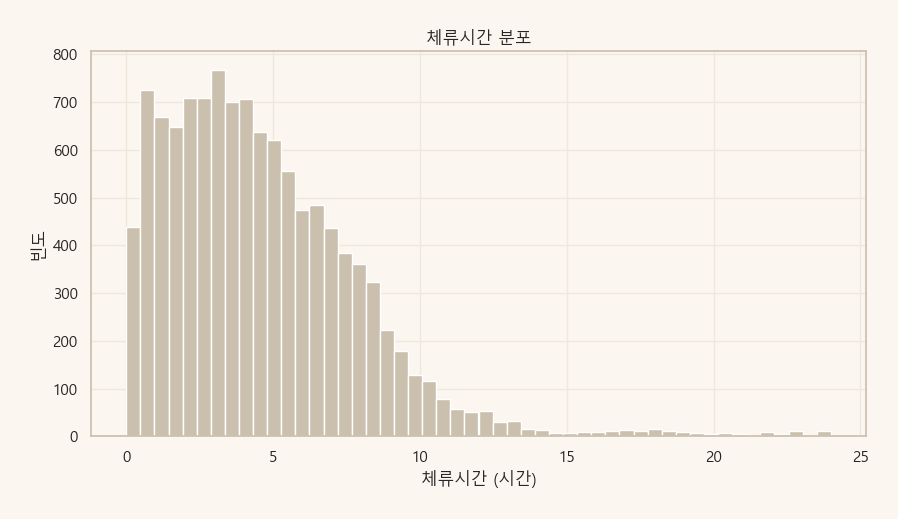

In [11]:
visit_check = df_visit.copy()

visit_check['stay_time_hour'] = (
    visit_check['stay_time_second'] / 3600
)

plt.figure(figsize=(10, 5))

plt.hist(
    visit_check['stay_time_hour'],
    bins=50,
    color=BEIGE
)

plt.title('체류시간 분포')
plt.xlabel('체류시간 (시간)')
plt.ylabel('빈도')

plt.show()

- 체류시간 중앙값은 4.1시간이고, 2\~4시간 구간(2,977건)에 가장 많이 분포한다.
- 분포의 오른쪽 꼬리가 24시간 부근까지 길게 이어진다. 12시간을 넘는 기록이 300건 있고, 최댓값인 86,377초는 24시간보다 1초 짧은 값이다. 실제 이용 시간이라기보다 퇴실 태그가 누락되어 생긴 기록으로 보인다.
- 이 체류시간은 `visit` 테이블에서 미리 계산된 값이다. 2.5\~2.6에서 `log` 테이블의 입·퇴실 태그로 체류시간을 다시 만들고, 이상치를 어떻게 처리할지 정한다.

# **2. 전처리**

## 2.1 완전 중복 행 제거

In [12]:
# 원본 보존 + 완전 중복행 제거
register = df_register.drop_duplicates().copy()
visit = df_visit.drop_duplicates().copy()
log = df_log.drop_duplicates().copy()
pay = df_pay.drop_duplicates().copy()
area = df_area.drop_duplicates().copy()

## 2.2 날짜/시간 타입 변환, 로그 시간대 보정

visit 테이블의 입·퇴실 시각은 KST 기준이다. 같은 사용자·지점의 `log` 테이블 기록과 비교하면 `cdate`가 약 9시간 이른 시각으로 기록되어 있었다. 따라서 `cdate`는 UTC 기준으로 저장된 것으로 판단하고, 분석 과정에서 KST로 변환했다.

In [13]:
# 날짜 타입 변환
register['trial_date'] = pd.to_datetime(
    register['trial_date'],
    format='mixed',
    errors='coerce'
)

visit['date'] = pd.to_datetime(
    visit['date'],
    format='mixed',
    errors='coerce'
)

visit['first_enter_time'] = pd.to_datetime(
    visit['first_enter_time'],
    format='mixed',
    errors='coerce'
)

visit['last_leave_time'] = pd.to_datetime(
    visit['last_leave_time'],
    format='mixed',
    errors='coerce'
)

log['cdate'] = pd.to_datetime(
    log['cdate'],
    format='mixed',
    errors='coerce'
)

In [14]:
# log 시간 UTC → KST
log['cdate'] = (
    log['cdate']
    + pd.Timedelta(hours=9)
)

In [15]:
#변환 결과
print(register['trial_date'].dtype)
print(visit['date'].dtype)
print(visit['first_enter_time'].dtype)
print(visit['last_leave_time'].dtype)
print(log['cdate'].dtype)

datetime64[us]
datetime64[us]
datetime64[us]
datetime64[us]
datetime64[us]


## 2.3 재신청 기록 제거

서로 다른 날짜에 재신청한 사용자 7명을 확인한 결과, 최초 신청 시점에는 방문 기록이 없고 재신청 시점에만 실제 방문 기록이 있었다. 따라서 실제 체험 행동과 연결된 재신청 기록은 유지하고, `register` 테이블에서는 최초 신청 기록만 제거했다. 이후 재신청일을 해당 사용자의 체험 신청일로 사용했다.

In [16]:
# 사용자별 최초 신청 기록 삭제
register = (
    register
    .sort_values('trial_date')
    .drop_duplicates(
        subset='user_uuid',
        keep='last'
    )
    .reset_index(drop=True)
)

print('처리 후 행 수 :', len(register))
print('고유 사용자 수 :', register['user_uuid'].nunique())

처리 후 행 수 : 9624
고유 사용자 수 : 9624


## 2.4 분석 기간을 벗어난 사용자 제거

다음 두 유형의 사용자를 제거한다.

1. 2024년 이후 입실 기록이 있는 사용자는 분석 기간인 2023년 12월을 벗어난 사례로 본다.
2. 3일차(신청일 + 2일)가 로그 관측 범위를 벗어나는 신청자도 제거한다. 로그는 2023-12-31 00:30에서 끊기므로
   하루 전체가 기록된 마지막 날짜는 2023-12-30이다. 2023-12-29 이후 신청자는 3일차 방문이
   있었더라도 기록이 남을 수 없어, `day3`가 실제와 무관하게 0이 된다.

두 유형 모두 일부 기록만 삭제하면 테이블 간 정보가 어긋나므로, 해당 사용자의 기록을
`register`, `visit`, `log`, `pay` 테이블에서 모두 제거한다.

In [17]:
# 2024년 이후 입실 기록이 있는 사용자 추출
out_of_period_users = (
    visit.loc[
        visit['first_enter_time'] >= pd.Timestamp('2024-01-01'),
        'user_uuid'
    ]
    .unique()
)

print('2024년 이후 입실 기록이 있는 사용자 수 :', len(out_of_period_users))

2024년 이후 입실 기록이 있는 사용자 수 : 13


In [18]:
# 제거 전 행 수
before_register = len(register)
before_visit = len(visit)
before_log = len(log)
before_pay = len(pay)

# 2024년 이후 입실 기록이 있는 사용자 전체 제거
register = register[
    ~register['user_uuid'].isin(out_of_period_users)
].copy()

visit = visit[
    ~visit['user_uuid'].isin(out_of_period_users)
].copy()

log = log[
    ~log['user_uuid'].isin(out_of_period_users)
].copy()

pay = pay[
    ~pay['user_uuid'].isin(out_of_period_users)
].copy()

# 인덱스 정리
register.reset_index(drop=True, inplace=True)
visit.reset_index(drop=True, inplace=True)
log.reset_index(drop=True, inplace=True)
pay.reset_index(drop=True, inplace=True)

# 제거 결과
print('=== 제거 결과 ===')
print(f'register : {before_register:,} → {len(register):,} '
      f'({before_register - len(register):,}행 제거)')

print(f'visit    : {before_visit:,} → {len(visit):,} '
      f'({before_visit - len(visit):,}행 제거)')

print(f'log      : {before_log:,} → {len(log):,} '
      f'({before_log - len(log):,}행 제거)')

print(f'pay      : {before_pay:,} → {len(pay):,} '
      f'({before_pay - len(pay):,}행 제거)')

=== 제거 결과 ===
register : 9,624 → 9,611 (13행 제거)
visit    : 11,429 → 11,400 (29행 제거)
log      : 63,349 → 63,162 (187행 제거)
pay      : 9,624 → 9,611 (13행 제거)


In [19]:
# 3일차(신청일 + 2일)가 로그 관측 범위를 벗어나는 신청자 제거
# 로그가 2023-12-31 00:30에서 끊기므로 하루가 온전히 담긴 마지막 날은 2023-12-30이다.
LAST_FULL_DAY = pd.Timestamp('2023-12-30')
TRIAL_CUTOFF = LAST_FULL_DAY - pd.Timedelta(days=2)   # 2023-12-28

truncated_users = register.loc[
    register['trial_date'] > TRIAL_CUTOFF, 'user_uuid'
].unique()

before_register = len(register)
before_visit = len(visit)
before_log = len(log)
before_pay = len(pay)

register = register[~register['user_uuid'].isin(truncated_users)].reset_index(drop=True)
visit = visit[~visit['user_uuid'].isin(truncated_users)].reset_index(drop=True)
log = log[~log['user_uuid'].isin(truncated_users)].reset_index(drop=True)
pay = pay[~pay['user_uuid'].isin(truncated_users)].reset_index(drop=True)

print(f'3일차가 관측되지 않는 신청자 : {len(truncated_users):,}명 '
      f'(신청일 {TRIAL_CUTOFF + pd.Timedelta(days=1):%Y-%m-%d} 이후)')
print('=== 제거 결과 ===')
print(f'register : {before_register:,} → {len(register):,}')
print(f'visit    : {before_visit:,} → {len(visit):,}')
print(f'log      : {before_log:,} → {len(log):,}')
print(f'pay      : {before_pay:,} → {len(pay):,}')
print('마지막 신청일 :', f"{register['trial_date'].max():%Y-%m-%d}")

3일차가 관측되지 않는 신청자 : 14명 (신청일 2023-12-29 이후)
=== 제거 결과 ===
register : 9,611 → 9,597
visit    : 11,400 → 11,386
log      : 63,162 → 63,064
pay      : 9,611 → 9,597
마지막 신청일 : 2023-12-28


## 2.5 입·퇴실 짝 정리

`log` 테이블은 입실(`checkin=1`)과 퇴실(`checkin=2`) 태그를 한 줄씩 기록한다. 사용자·지점·시각 순으로 정렬했을 때 입실 다음 행에 같은 사용자·지점의 퇴실 기록이 있으면 한 쌍으로 간주하고, 이 조건을 충족하지 않는 태그는 짝이 맞지 않는 것으로 분류했다.

처리 기준 시간은 60분이다. 공유오피스 이용 규칙에 "퇴실 후 60분 이내에 재입실하면 연속 이용으로 본다"는 내용이 있어 이를 근거로 삼았다.

| # | 패턴 | 추정 상황 | 처리 |
|---|---|---|---|
| 1 | 입실 → 입실 (60분 이내) | 태그를 두 번 찍었거나, 퇴실 태그 없이 나갔다가 곧 돌아옴 | 첫 입실만 남김 |
| 2 | 입실 → 입실 (60분 초과) | 퇴실 태그 없이 나감 | 방문으로 유지, 체류시간은 결측 |
| 3 | 마지막 태그가 입실 | 퇴실 태그 없이 나감 | 2와 같음 |
| 4 | 퇴실 → 퇴실 (60분 이내) | 태그를 두 번 찍었거나, 입실 태그 없이 들어왔다가 다시 나감 | 마지막 퇴실만 남김 |
| 5 | 퇴실 → 퇴실 (60분 초과) | 입실 태그 없이 들어옴 | 제거 |
| 6 | 첫 태그가 퇴실 | 입실 태그 없이 들어옴 | 제거 |

- 1·4: 같은 종류의 태그가 60분 이내에 연속으로 기록되면 이용 규칙에 따라 연속 이용으로 보고, 첫 입실부터 마지막 퇴실까지를 하나의 체류로 남긴다.
- 2·3: 입실 태그는 실제 방문의 근거이며 방문일도 첫 입실 날짜를 기준으로 계산하므로 방문 기록으로 유지한다. 퇴실 시각을 알 수 없어 체류시간은 0이 아닌 결측으로 두고, 체류시간 분석에서만 제외한다.
- 5·6: 방문이 언제 시작됐는지 알 수 없고, 방문일을 첫 입실 날짜로 세는 정의와 맞지 않아 제거한다.

- 60분 이내 연속 태그 정리 (1·4)

In [20]:
PAIR_GAP_MIN = 60  # 이용 규칙 : 퇴실 후 60분 이내 재입실은 연속 이용

# 사용자·지점·시각 순 정렬 (같은 시각이면 입실 먼저)
log = log.sort_values(['user_uuid', 'site_id', 'cdate', 'checkin']).reset_index(drop=True)

prev = log.shift(1)
nxt = log.shift(-1)
same_prev = (prev['user_uuid'] == log['user_uuid']) & (prev['site_id'] == log['site_id'])
same_next = (nxt['user_uuid'] == log['user_uuid']) & (nxt['site_id'] == log['site_id'])

# 1. 입실 → 입실 (60분 이내) : 뒤의 입실을 지워 첫 입실만 남김
dup_enter = (
    (log['checkin'] == 1)
    & same_prev
    & (prev['checkin'] == 1)
    & ((log['cdate'] - prev['cdate']).dt.total_seconds() <= PAIR_GAP_MIN * 60)
)

# 4. 퇴실 → 퇴실 (60분 이내) : 앞의 퇴실을 지워 마지막 퇴실만 남김
dup_leave = (
    (log['checkin'] == 2)
    & same_next
    & (nxt['checkin'] == 2)
    & ((nxt['cdate'] - log['cdate']).dt.total_seconds() <= PAIR_GAP_MIN * 60)
)

before_log = len(log)
log = log[~(dup_enter | dup_leave)].reset_index(drop=True)

print('1. 입실 → 입실 (60분 이내) 정리 :', f'{dup_enter.sum():,}')
print('4. 퇴실 → 퇴실 (60분 이내) 정리 :', f'{dup_leave.sum():,}')
print(f'log : {before_log:,} → {len(log):,}')

1. 입실 → 입실 (60분 이내) 정리 : 1,246
4. 퇴실 → 퇴실 (60분 이내) 정리 : 888
log : 63,064 → 60,930


- 입·퇴실 짝 맞추기, 짝 없는 태그 처리 (2·3·5·6)

In [21]:
prev = log.shift(1)
nxt = log.shift(-1)
same_prev = (prev['user_uuid'] == log['user_uuid']) & (prev['site_id'] == log['site_id'])
same_next = (nxt['user_uuid'] == log['user_uuid']) & (nxt['site_id'] == log['site_id'])

# 입실 바로 다음 행이 같은 사용자·지점의 퇴실이면 한 쌍
next_is_leave = (log['checkin'] == 1) & same_next & (nxt['checkin'] == 2)
prev_is_enter = (log['checkin'] == 2) & same_prev & (prev['checkin'] == 1)

# 짝 없는 입실 (2·3)
lone_enter = (log['checkin'] == 1) & ~next_is_leave
print('2. 입실 → 입실 (60분 초과) :', f"{(lone_enter & same_next).sum():,}")
print('3. 마지막 태그가 입실 :', f"{(lone_enter & ~same_next).sum():,}")

# 짝 없는 퇴실 (5·6)
lone_leave = (log['checkin'] == 2) & ~prev_is_enter
print('5. 퇴실 → 퇴실 (60분 초과) :', f"{(lone_leave & same_prev).sum():,}")
print('6. 첫 태그가 퇴실 :', f"{(lone_leave & ~same_prev).sum():,}")

# 입실 행에 짝 퇴실 시각 붙이기 (짝 없는 입실은 퇴실·체류시간 결측)
ent = log[log['checkin'] == 1].copy()
ent['leave'] = nxt.loc[ent.index, 'cdate'].where(next_is_leave[ent.index])
ent['stay_sec'] = (ent['leave'] - ent['cdate']).dt.total_seconds()

# 짝 없는 퇴실 제거
log = log[~lone_leave].reset_index(drop=True)

print()
print('입실 태그 :', f'{len(ent):,}')
print('퇴실까지 짝지어진 입실 :', f"{ent['leave'].notna().sum():,}")
print('짝 없는 입실 (체류시간 결측) :', f"{ent['leave'].isna().sum():,}")
print('제거한 짝 없는 퇴실 :', f'{lone_leave.sum():,}')

2. 입실 → 입실 (60분 초과) : 254
3. 마지막 태그가 입실 : 280
5. 퇴실 → 퇴실 (60분 초과) : 170
6. 첫 태그가 퇴실 : 140

입실 태그 : 30,577
퇴실까지 짝지어진 입실 : 30,043
짝 없는 입실 (체류시간 결측) : 534
제거한 짝 없는 퇴실 : 310


## 2.6 방문 단위 구성 및 체류시간 이상치 처리

입·퇴실 짝을 방문 단위로 묶어 방문일을 구성하고, 체류시간이 비정상적으로 긴 기록을 처리한다. 장시간 기록은 두 가지 원인에서 발생하며, 원인에 따라 처리 단위가 다르다.

| 원인 | 예 | 처리 |
|---|---|---|
| A. 입·퇴실 짝 하나가 비정상적으로 긺 | 17시 입실, 다음 날 12시 퇴실. 중간 태그가 빠진 것으로 보인다 | 짝 체류시간이 12시간 이상이면 체류시간을 결측으로 둔다 |
| B. 방문일 체류시간이 12시간을 넘음 | 11월 5일 12시부터 다음 날 23시까지 9번 입·퇴실. 방문일 체류가 31.5시간이 된다 | 방문일 체류시간에 12시간 상한을 적용한다 |

- 순서: 짝 단위 처리(원인 A) → 방문 단위 구성 및 방문일 집계 → 방문일 상한 적용(원인 B). 잘못된 측정값이 방문일 합계에 포함되지 않도록 짝 단위를 먼저 처리한다.
- 방문 단위 구성은 퇴실 시각을 기준으로 간격을 계산하므로, 짝 체류시간을 결측 처리해도 방문 구분은 바뀌지 않는다.
- 원인 B는 두 가지가 섞여 있다. 체류시간이 짧은 짝이 60분 이내로 이어져 이틀이 하루로 합쳐진 경우가 절반이고, 나머지 절반은 같은 날 안에서 태그를 여러 번 찍으며 실제로 12시간 넘게 머문 기록이다. 두 경우를 구분하지 않고 동일한 상한을 적용한다. 해당하는 방문일이 전체의 1% 남짓이라 결과는 거의 바뀌지 않는다.
- 두 기준 모두 데이터에서 학습한 값이 아닌 고정 규칙이므로, 학습·평가 분할 전에 적용해도 누수가 없다.
- 짝을 결측 처리해도 입실 기록은 남기므로 방문일은 줄지 않는다.

- 짝 체류시간 12시간 기준의 근거

  짝 체류시간은 12시간 전까지 매끄럽게 줄어들다가, 12시간 이후에는 1시간 구간당 0\~2건으로 흩어진다. 기존 분포의 연속이라기보다 태그 누락으로 생긴 기록으로 보고 12시간을 기준으로 삼았다.
  그래프의 가로축 눈금은 1시간 구간의 시작값이다(6은 6\~7시간). 주황 막대는 결측으로 처리한 12시간 이상 구간이다.

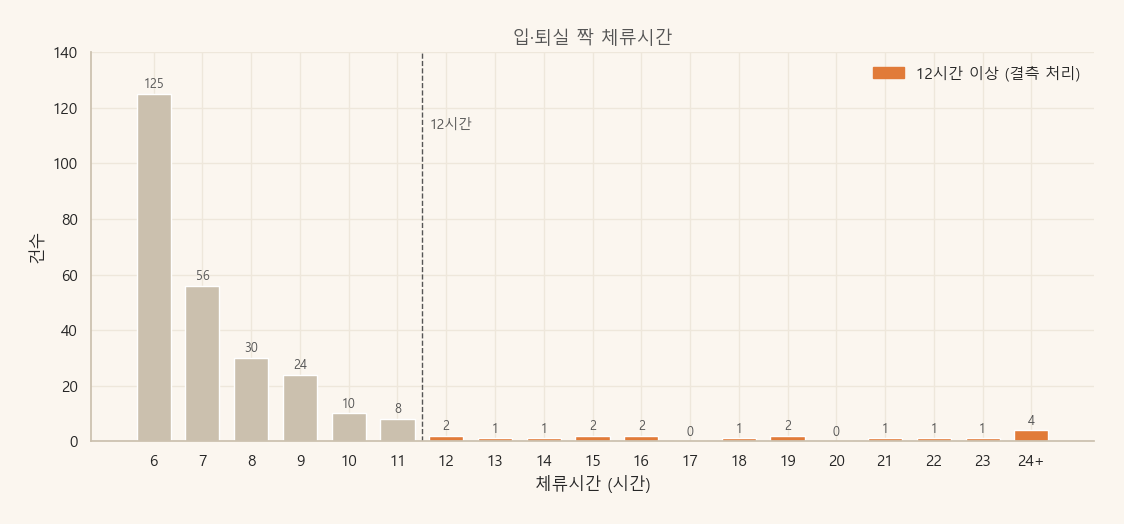

짝 12시간 이상 : 18건 / 30,043건 (0.06%)
99.9분위수 10.7h, 99.95분위수 13.8h


In [22]:
from matplotlib.patches import Patch

pair_h = ent['stay_sec'].dropna() / 3600  # 입·퇴실 짝 체류시간

# 6시간 이상, 1시간 구간별 건수
edges = list(range(6, 25)) + [np.inf]
labels = [str(e) for e in range(6, 24)] + ['24+']
cnt = pd.cut(pair_h, edges, right=False).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 5))
colors = [ORANGE if e >= 12 else BEIGE for e in range(6, 25)]
ax.bar(labels, cnt.values, color=colors, width=0.7)
for i, c in enumerate(cnt.values):
    ax.text(i, c + 2, f'{c}', ha='center', fontsize=9, color=DARK)
ax.set_ylim(0, cnt.max() * 1.12)
ax.axvline(5.5, color=DARK, linestyle='--', linewidth=1)
ax.text(5.65, cnt.max() * 0.9, '12시간', fontsize=10, color=DARK)
ax.legend(handles=[Patch(color=ORANGE, label='12시간 이상 (결측 처리)')], frameon=False, loc='upper right')
ax.set_title('입·퇴실 짝 체류시간', fontsize=13, color=DARK)
ax.set_xlabel('체류시간 (시간)')
ax.set_ylabel('건수')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'짝 12시간 이상 : {(pair_h >= 12).sum()}건 / {len(pair_h):,}건 ({(pair_h >= 12).mean():.2%})')
print(f'99.9분위수 {pair_h.quantile(0.999):.1f}h, 99.95분위수 {pair_h.quantile(0.9995):.1f}h')

- 짝 체류시간 12시간 이상 결측 처리

In [23]:
PAIR_MAX_H = 12  # 짝 체류시간이 이 값 이상이면 태그 누락으로 보고 결측 처리

long_pair = ent['stay_sec'] >= PAIR_MAX_H * 3600
ent.loc[long_pair, 'stay_sec'] = np.nan

print('체류시간을 결측 처리한 짝 :', f'{long_pair.sum():,}')
print('체류시간 결측 입실 (짝 없는 입실 포함) :', f"{ent['stay_sec'].isna().sum():,}")

체류시간을 결측 처리한 짝 : 18
체류시간 결측 입실 (짝 없는 입실 포함) : 552


- 방문(세션) 묶기와 방문일 집계

  이전 퇴실(퇴실이 없으면 이전 입실)로부터 60분 이내에 다시 입실하면 같은 방문으로 묶는다. 이용 규칙(퇴실 후 60분 이내 재입실은 연속 이용)과 같은 기준이며, 자정을 넘긴 재입실도 이 기준으로 판단한다. 방문의 첫 입실 날짜를 방문일로 쓰고, 이용 횟수는 (사용자, 지점, 방문일) 단위로 계산한다. 체류시간을 알 수 없는 방문도 방문일에는 포함한다.

In [24]:
GAP_MIN = 60  # 이전 퇴실 ~ 다음 입실이 60분 이내면 같은 방문 (이용 규칙과 같은 기준)

# 사용자·지점·시각 순 정렬
ent = ent.sort_values(['user_uuid', 'site_id', 'cdate']).reset_index(drop=True)

# 이전 입실 행
prev = ent.shift(1)

# 이전 구간의 끝 : 퇴실이 없으면 입실 시각
prev_end = prev['leave'].fillna(prev['cdate'])

# 사용자·지점이 바뀌거나 간격이 60분을 넘으면 새 방문
new_visit = (
    (ent['user_uuid'] != prev['user_uuid'])
    | (ent['site_id'] != prev['site_id'])
    | ((ent['cdate'] - prev_end).dt.total_seconds() > GAP_MIN * 60)
)
ent['visit_id'] = new_visit.cumsum()

# 방문일 = 방문의 첫 입실 날짜
ent['visit_date'] = ent.groupby('visit_id')['cdate'].transform('min').dt.normalize()

# 입실 날짜와 방문일이 다른 태그 = 자정을 넘긴 방문 중 재입실
print('방문(세션) 수 :', f"{ent['visit_id'].nunique():,}")
print('자정 넘겨 이어진 재입실 태그 :', (ent['cdate'].dt.normalize() != ent['visit_date']).sum())

방문(세션) 수 : 10,943


자정 넘겨 이어진 재입실 태그 : 300


In [25]:
trial = register.set_index('user_uuid')['trial_date']

# 이용 1회 = (사용자, 지점, 방문일)
# skipna=False : 그 날 짝 중 하나라도 체류시간을 모르면 방문일 체류시간도 결측으로 둔다.
#   min_count=1을 쓰면 아는 값만 더해 그 날을 실제보다 짧게 기록하고,
#   체류시간을 아는 날로 분류해 평균의 분모에도 넣게 된다.
visit_day = (
    ent
    .groupby(['user_uuid', 'site_id', 'visit_date'])['stay_sec']
    .sum(skipna=False)
    .reset_index()
)

# 신청일 = 1일차
visit_day['day_n'] = (visit_day['visit_date'] - visit_day['user_uuid'].map(trial)).dt.days + 1
visit_day['weekday'] = visit_day['visit_date'].dt.weekday

print('이용 횟수(사용자·지점·방문일) :', f'{len(visit_day):,}')
print('체류시간 결측 이용 :', f"{visit_day['stay_sec'].isna().sum():,}")
print('일차 분포 :', visit_day['day_n'].value_counts().sort_index().to_dict())

이용 횟수(사용자·지점·방문일) : 8,864
체류시간 결측 이용 : 528
일차 분포 : {1: 1639, 2: 4042, 3: 3183}


- 방문일 체류시간 12시간 상한 (원인 B)

  방문일 체류시간의 IQR 상한(12.4시간)과 99분위수(12.2시간)를 근거로, 반올림한 12시간을 상한으로 정하고 이를 넘는 값은 12시간으로 바꿨다. 장시간 체류자의 결제율이 낮으므로, 분석 대상에서 제외하지 않고 체류시간에만 상한을 적용했다.
  그래프의 가로축 눈금은 1시간 구간의 시작값이다(0은 0\~1시간).

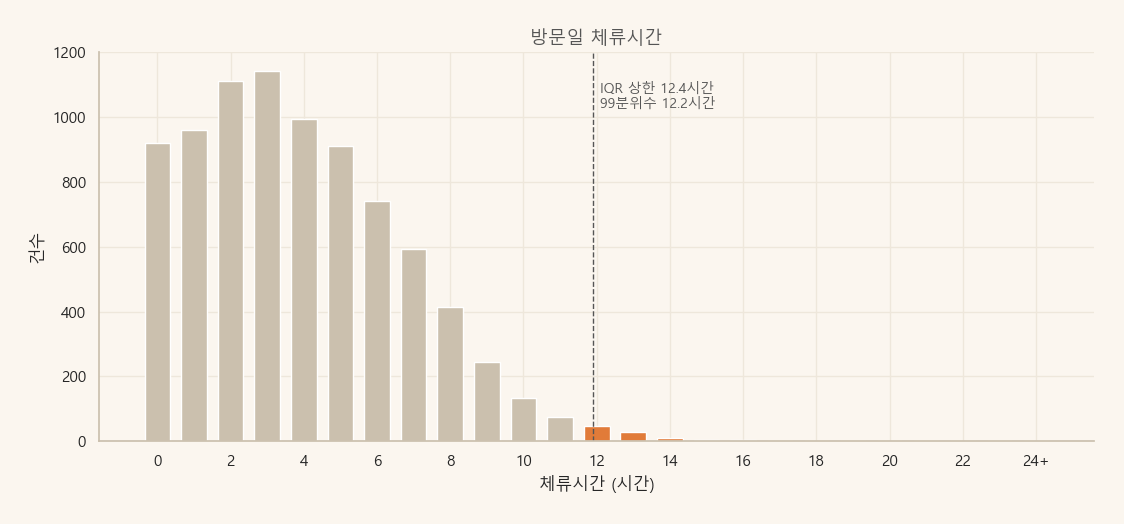

방문일 Q1 2.2h, Q3 6.3h → IQR 상한 12.4h, 99분위수 12.2h
방문일 최댓값 19.4h


In [26]:
day_h = visit_day['stay_sec'].dropna() / 3600  # 방문일(사용자·지점·방문일) 체류시간

# IQR 상한, 99분위수
q1, q3 = day_h.quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
p99 = day_h.quantile(0.99)

edges = list(range(0, 25)) + [np.inf]
labels = [str(e) for e in range(0, 24)] + ['24+']
cnt = pd.cut(day_h, edges, right=False).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 5))
colors = [ORANGE if e >= 12 else BEIGE for e in range(0, 25)]
ax.bar(labels, cnt.values, color=colors, width=0.7)
ax.axvline(iqr_upper - 0.5, color=DARK, linestyle='--', linewidth=1)
ax.text(iqr_upper - 0.3, cnt.max() * 0.9,
        f'IQR 상한 {iqr_upper:.1f}시간\n99분위수 {p99:.1f}시간', fontsize=10, color=DARK)
ax.set_title('방문일 체류시간', fontsize=13, color=DARK)
ax.set_xlabel('체류시간 (시간)')
ax.set_ylabel('건수')
ax.set_xticks(range(0, 25, 2))
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f'방문일 Q1 {q1:.1f}h, Q3 {q3:.1f}h → IQR 상한 {iqr_upper:.1f}h, 99분위수 {p99:.1f}h')
print(f'방문일 최댓값 {day_h.max():.1f}h')

In [27]:
DAY_MAX_H = 12  # 방문일 체류시간 상한

over_day = visit_day['stay_sec'] > DAY_MAX_H * 3600
visit_day['stay_sec'] = visit_day['stay_sec'].clip(upper=DAY_MAX_H * 3600)

print('12시간 상한을 적용한 방문일 :', f'{over_day.sum():,}건 (사용자 {visit_day.loc[over_day, "user_uuid"].nunique():,}명)')
print('방문일 체류시간 최댓값 :', f"{visit_day['stay_sec'].max() / 3600:.1f}h")

12시간 상한을 적용한 방문일 : 96건 (사용자 90명)
방문일 체류시간 최댓값 : 12.0h


# **3. EDA**

## 3.0 사용자 단위 요약

2.6에서 만든 방문일(`visit_day`)을 사용자 1명당 1행으로 요약한다. 신청자 전체 데이터와 결합하고, 로그가 없는 사용자는 미방문자로 분류한다.

In [28]:
# 사용자 1명당 1행
g = visit_day.groupby('user_uuid')

user_log = pd.DataFrame()
user_log['visit_days'] = g['visit_date'].nunique()                      # 방문일수
user_log['total_stay_h'] = g['stay_sec'].sum(min_count=1) / 3600       # 총 체류시간 (모두 결측이면 결측)
known_days = visit_day.dropna(subset=['stay_sec']).groupby('user_uuid')['visit_date'].nunique()
user_log['avg_stay_h'] = user_log['total_stay_h'] / known_days        # 일평균 체류시간 (체류시간을 아는 방문일 기준)
user_log['lead_day'] = g['day_n'].min()                                 # 첫 방문 일차
user_log['pattern'] = g['day_n'].apply(lambda s: tuple(sorted(set(s))))  # 방문 일차 조합
user_log['n_sites'] = g['site_id'].nunique()                            # 이용 지점 수
user_log['n_use'] = g.size()                                            # 이용 횟수
user_log = user_log.reset_index()

# 신청자 전체에 붙이기 (로그 없는 사용자 = 미방문)
u = (
    register[['user_uuid', 'trial_date']]
    .merge(pay[['user_uuid', 'is_payment']], on='user_uuid', how='left')
    .merge(user_log, on='user_uuid', how='left')
)
u['visited'] = u['visit_days'].notna().astype(int)
u['visit_days'] = u['visit_days'].fillna(0).astype(int)

overall = u['is_payment'].mean()
print('신청자 :', f'{len(u):,}', '/ 방문자 :', f"{u['visited'].sum():,}", '/ 전체 결제율 :', f'{overall:.1%}')
print('방문했지만 체류시간을 알 수 없음 :', ((u['visited'] == 1) & u['total_stay_h'].isna()).sum(), '명')

신청자 : 9,597 / 방문자 : 5,987 / 전체 결제율 : 38.0%
방문했지만 체류시간을 알 수 없음 : 193 명


## 3.1 분기별 방문율과 결제율

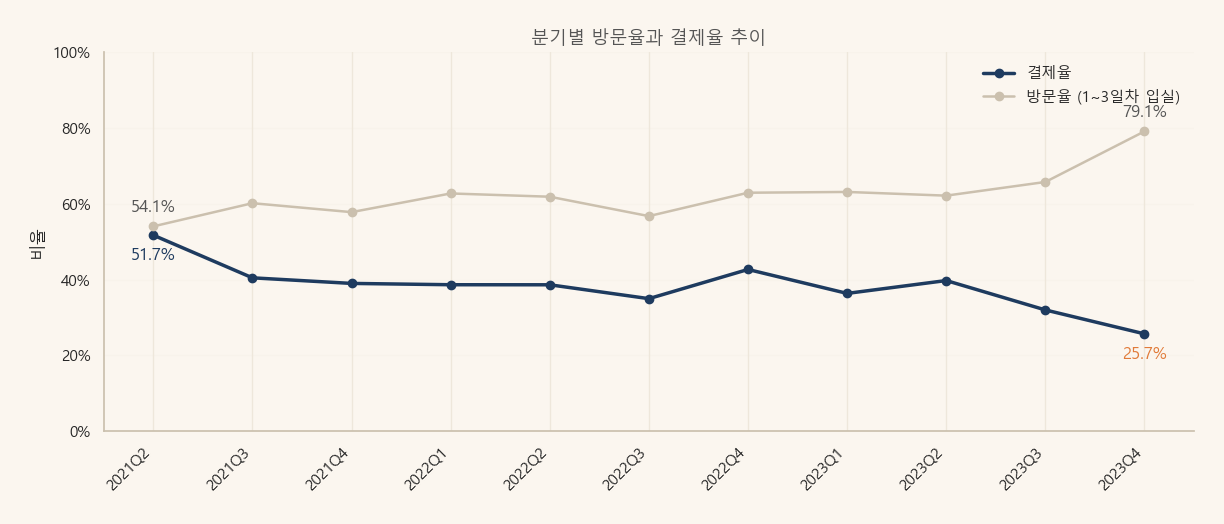

quarter  2021Q2  2021Q3  2021Q4  2022Q1  2022Q2  2022Q3  2022Q4  2023Q1  2023Q2  2023Q3  2023Q4
users       603    1193    1010     988     740     886     869     844     772     906     786


In [29]:
# 분기
u['quarter'] = u['trial_date'].dt.to_period('Q')

quarterly = (
    u.groupby('quarter')
    .agg(
        users=('user_uuid', 'nunique'),
        payment_rate=('is_payment', 'mean'),
        visit_rate=('visited', 'mean')
    )
)

x = range(len(quarterly))
labels = quarterly.index.astype(str)
first = quarterly.iloc[0]
last = quarterly.iloc[-1]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(x, quarterly['payment_rate'], color=NAVY, marker='o', linewidth=2.5, label='결제율')
ax.plot(x, quarterly['visit_rate'], color=BEIGE, marker='o', linewidth=1.8, label='방문율 (1~3일차 입실)')

# 시작점, 끝점 값 표시
ax.annotate(f"{first['payment_rate']:.1%}", (0, first['payment_rate']), xytext=(0, -18), textcoords='offset points', ha='center', color=NAVY)
ax.annotate(f"{last['payment_rate']:.1%}", (len(x) - 1, last['payment_rate']), xytext=(0, -18), textcoords='offset points', ha='center', color=ORANGE)
ax.annotate(f"{first['visit_rate']:.1%}", (0, first['visit_rate']), xytext=(0, 10), textcoords='offset points', ha='center', color=DARK)
ax.annotate(f"{last['visit_rate']:.1%}", (len(x) - 1, last['visit_rate']), xytext=(0, 10), textcoords='offset points', ha='center', color=DARK)

ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylabel('비율')
ax.set_title('분기별 방문율과 결제율 추이', fontsize=13, color=DARK)
ax.legend(frameon=False, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

print(quarterly[['users']].T.to_string())

- `log` 테이블 기준 방문율은 2021년 2분기 54.1%에서 2023년 4분기 79.1%로 올랐고, 결제율은 51.7%에서 25.7%로 떨어졌다.
- `visit` 테이블 기준 방문율(58.4% → 81.9%)보다 조금 낮다. 공식 체험 기간이 끝난 4일차에만 방문한 사용자가 `log` 테이블에서는 미방문으로 분류되기 때문이다.
- 방문은 늘고 결제는 줄어드는 흐름은 `visit` 테이블 기준 분석과 동일하다.

## 3.2 전체 신청자 → 방문 여부 → 결제 여부

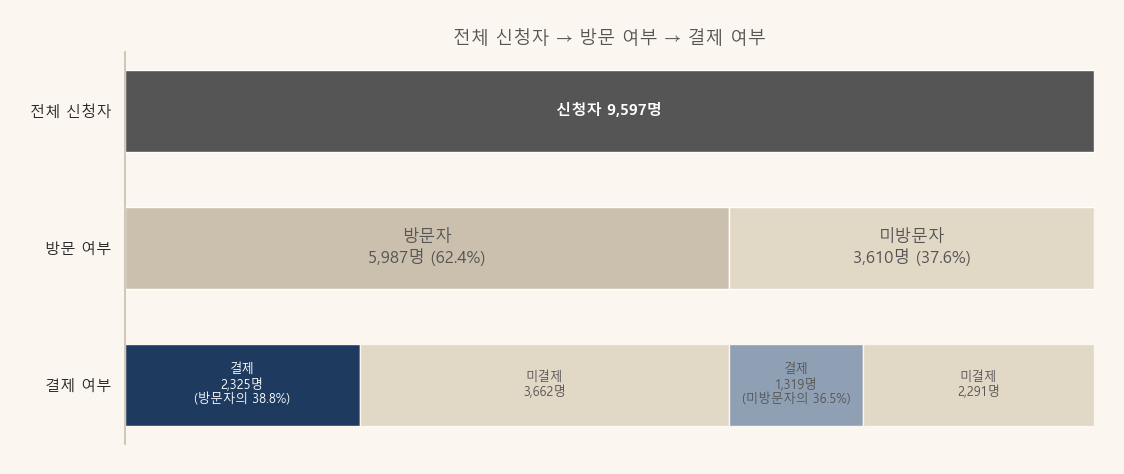

In [30]:
total = len(u)
n_visit = (u['visited'] == 1).sum()
n_novisit = (u['visited'] == 0).sum()

visit_yes = ((u['visited'] == 1) & (u['is_payment'] == 1)).sum()
visit_no = ((u['visited'] == 1) & (u['is_payment'] == 0)).sum()
novisit_yes = ((u['visited'] == 0) & (u['is_payment'] == 1)).sum()
novisit_no = ((u['visited'] == 0) & (u['is_payment'] == 0)).sum()

fig, ax = plt.subplots(figsize=(11, 4.5))

# 행1 : 전체 신청자
ax.barh(2, total, color=DARK, height=0.6)
ax.text(total / 2, 2, f'신청자 {total:,}명', ha='center', va='center', color='white', fontsize=11, fontweight='bold')

# 행2 : 방문자 / 미방문자
ax.barh(1, n_visit, color=BEIGE, height=0.6)
ax.barh(1, n_novisit, left=n_visit, color=BEIGE_L, height=0.6)
ax.text(n_visit / 2, 1, f'방문자\n{n_visit:,}명 ({n_visit / total:.1%})', ha='center', va='center', color=DARK)
ax.text(n_visit + n_novisit / 2, 1, f'미방문자\n{n_novisit:,}명 ({n_novisit / total:.1%})', ha='center', va='center', color=DARK)

# 행3 : 방문 여부별 결제 / 미결제 (괄호 = 방문자·미방문자 안에서 계산한 결제율)
ax.barh(0, visit_yes, color=NAVY, height=0.6, edgecolor=CREAM)
ax.barh(0, visit_no, left=visit_yes, color=BEIGE_L, height=0.6, edgecolor=CREAM)
ax.barh(0, novisit_yes, left=n_visit, color=NAVY_L, height=0.6, edgecolor=CREAM)
ax.barh(0, novisit_no, left=n_visit + novisit_yes, color=BEIGE_L, height=0.6, edgecolor=CREAM)

ax.text(visit_yes / 2, 0, f'결제\n{visit_yes:,}명\n(방문자의 {visit_yes / n_visit:.1%})', ha='center', va='center', color='white', fontsize=9)
ax.text(visit_yes + visit_no / 2, 0, f'미결제\n{visit_no:,}명', ha='center', va='center', color=DARK, fontsize=9)
ax.text(n_visit + novisit_yes / 2, 0, f'결제\n{novisit_yes:,}명\n(미방문자의 {novisit_yes / n_novisit:.1%})', ha='center', va='center', color=DARK, fontsize=9)
ax.text(n_visit + novisit_yes + novisit_no / 2, 0, f'미결제\n{novisit_no:,}명', ha='center', va='center', color=DARK, fontsize=9)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(['결제 여부', '방문 여부', '전체 신청자'])
ax.set_xlim(0, total)
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom']].set_visible(False)
ax.set_title('전체 신청자 → 방문 여부 → 결제 여부', fontsize=13, color=DARK)

plt.tight_layout()
plt.show()

- 신청자 9,597명 중 1\~3일차에 방문한 사용자는 5,987명(62.4%)이다.
- 결제 막대의 괄호 안 비율은 방문자와 미방문자 안에서 각각 계산한 결제율이다. 방문자는 38.8%(2,325명 / 5,987명), 미방문자는 36.5%(1,319명 / 3,610명)로 차이가 2.3%p에 그친다.
- 전체 신청자 대비로는 방문 후 결제한 사람이 24.2%, 방문하지 않고 결제한 사람이 13.7%다.
- `visit` 테이블 기준 방문자(6,511명)와의 차이 524명은 4일차에만 방문한 511명, `log` 테이블에 퇴실 태그만 남은 15명이 미방문으로 바뀌고, `visit` 테이블에 없던 2명이 방문으로 포함된 결과다.

## 3.3 방문일수별 결제율

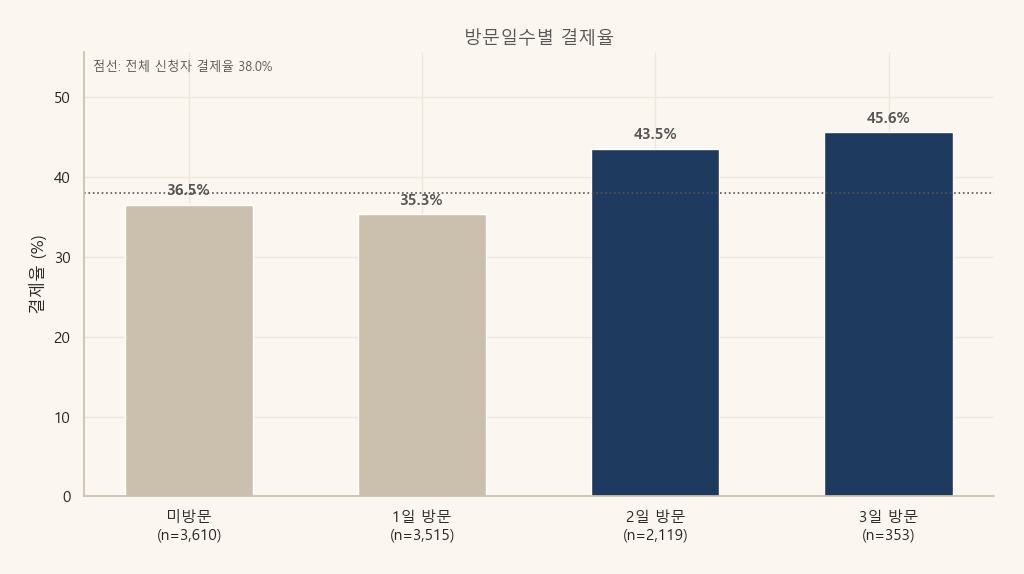

In [31]:
result = u.groupby('visit_days')['is_payment'].agg(['count', 'mean'])

labels = ['미방문' if d == 0 else f'{d}일 방문' for d in result.index]
counts = result['count'].values
rates = result['mean'].values * 100

# 전체 신청자 결제율보다 5%p 이상 높으면 남색, 5%p 이상 낮으면 주황
colors = []
for d, r in zip(result.index, rates):
    if d == 0:
        colors.append(BEIGE)
    elif r >= overall * 100 + 5:
        colors.append(NAVY)
    elif r <= overall * 100 - 5:
        colors.append(ORANGE)
    else:
        colors.append(BEIGE)

x_labels = [f'{l}\n(n={c:,})' for l, c in zip(labels, counts)]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x_labels, rates, color=colors, width=0.55)

for i, r in enumerate(rates):
    ax.text(i, r + 1.2, f'{r:.1f}%', ha='center', fontsize=11, color=DARK, fontweight='bold')

ax.axhline(overall * 100, color=DARK, linestyle=':', linewidth=1.2)
ax.text(0.01, 0.98, f'점선: 전체 신청자 결제율 {overall:.1%}', transform=ax.transAxes, va='top', fontsize=9, color=DARK)

ax.set_title('방문일수별 결제율', fontsize=13, color=DARK)
ax.set_ylabel('결제율 (%)')
ax.set_ylim(0, max(rates) + 10)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

- 막대 색은 전체 신청자 결제율과 비교한 결과다. 5%p 이상 높으면 남색, 5%p 이상 낮으면 주황으로 칠했고, 미방문 막대는 베이지로 두었다.
- 1일만 방문한 사용자의 결제율(35.3%)이 미방문(36.5%)보다 낮고, 2일 43.5%, 3일 45.6%로 여러 날 방문할수록 결제율이 높아진다.
- `visit` 테이블 기준 분석과 동일한 경향을 보인다.

## 3.4 방문일차 조합별 결제율

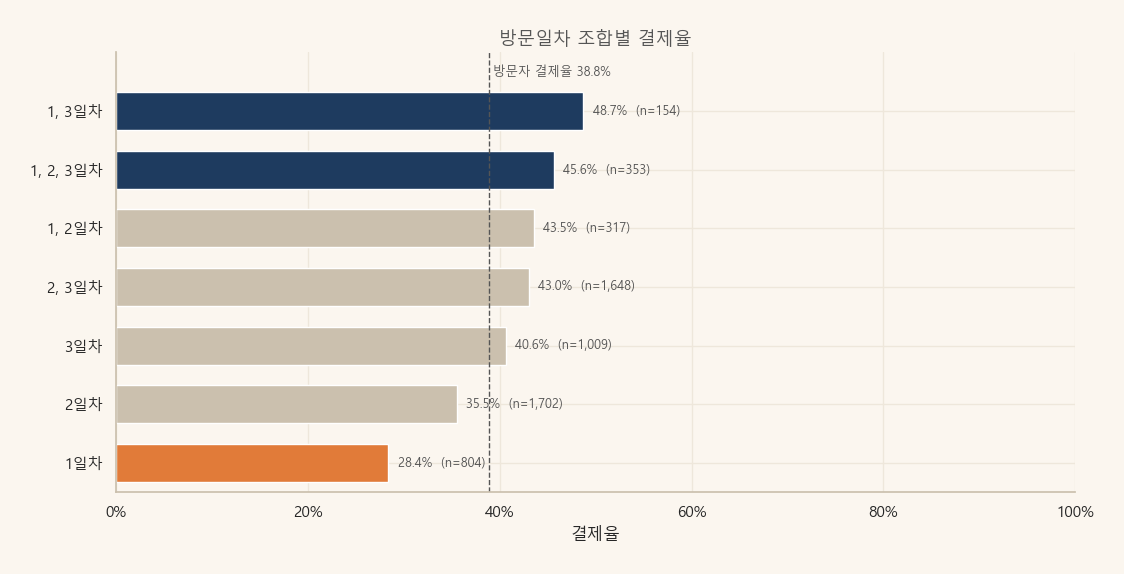

In [32]:
vis = u[u['visited'] == 1].copy()
vis['pattern_str'] = vis['pattern'].apply(lambda p: ', '.join(str(d) for d in p) + '일차')

result = vis.groupby('pattern_str')['is_payment'].agg(['count', 'mean'])
result = result[result['count'] >= 30].sort_values('mean')   # 30명 미만 조합 제외, 오름차순 → 위가 최댓값

visitor_rate = vis['is_payment'].mean()

labels = result.index.tolist()
counts = result['count'].values
rates = result['mean'].values

colors = [
    NAVY if r >= visitor_rate + 0.05 else (ORANGE if r <= visitor_rate - 0.05 else BEIGE)
    for r in rates
]

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(labels, rates, color=colors, height=0.65)

for b, c, r in zip(bars, counts, rates):
    ax.text(r + 0.01, b.get_y() + b.get_height() / 2, f'{r:.1%}  (n={c:,})', va='center', fontsize=9, color=DARK)

ax.axvline(visitor_rate, color=DARK, linestyle='--', linewidth=1)
ax.text(visitor_rate + 0.005, len(labels) - 0.4, f'방문자 결제율 {visitor_rate:.1%}', fontsize=9, color=DARK)

ax.set_title('방문일차 조합별 결제율', fontsize=13, color=DARK)
ax.set_xlabel('결제율')
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, len(labels))   # 위쪽에 '방문자 결제율' 글자가 들어갈 공간을 둔다
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

- 막대 색은 방문자 결제율과 비교한 결과다. 5%p 이상 높으면 남색, 5%p 이상 낮으면 주황으로 칠했다.
- 1일차(신청일)에만 방문한 사용자가 28.4%로 가장 낮다.
- 1·3일차(48.7%), 1·2·3일차(45.6%)처럼 공식 체험 마지막 날인 3일차까지 방문한 조합의 결제율이 높고, 3일차에만 방문한 사용자(40.6%)도 방문자 결제율(38.8%)보다 높다.

## 3.5 일평균 체류시간별 결제율

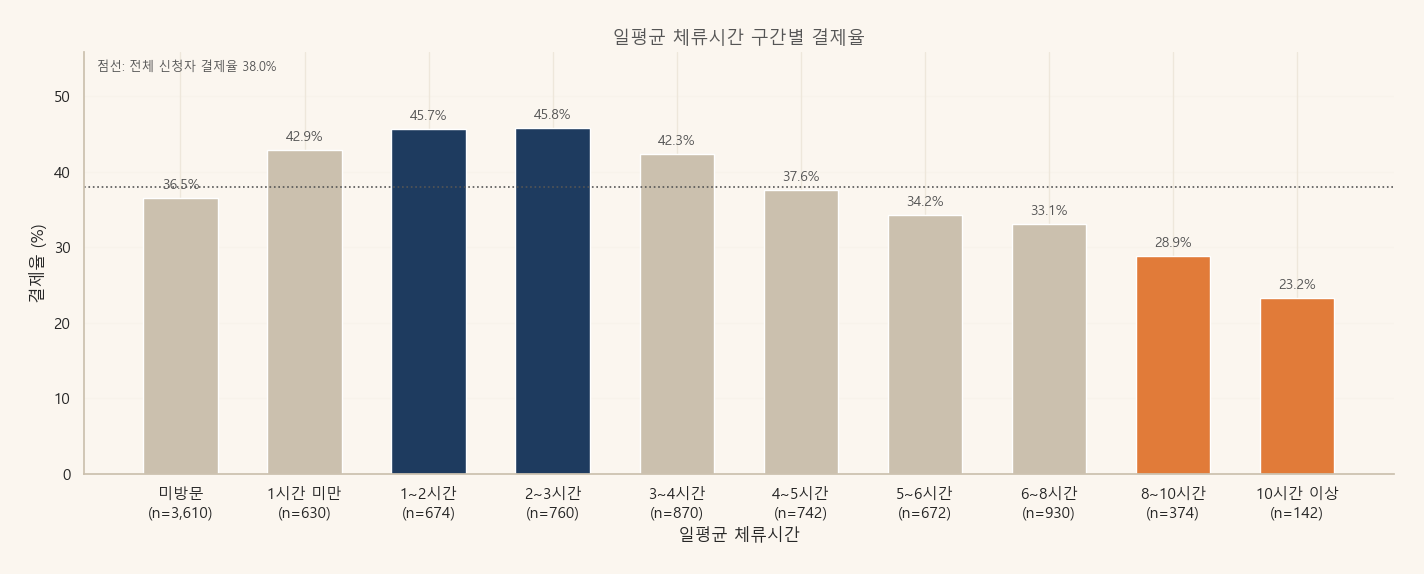

In [33]:
edges = [0, 1, 2, 3, 4, 5, 6, 8, 10, float('inf')]
labels = ['1시간 미만', '1~2시간', '2~3시간', '3~4시간', '4~5시간', '5~6시간', '6~8시간', '8~10시간', '10시간 이상']

u['stay_bucket'] = pd.cut(u['avg_stay_h'], bins=edges, right=False, labels=labels)

result = (
    u[u['visited'] == 1]
    .groupby('stay_bucket', observed=True)['is_payment']
    .agg(['count', 'mean'])
)

novisit_n = (u['visited'] == 0).sum()
novisit_rate = u.loc[u['visited'] == 0, 'is_payment'].mean()

all_labels = ['미방문'] + list(result.index)
all_counts = [novisit_n] + list(result['count'])
all_rates = [novisit_rate * 100] + list(result['mean'] * 100)

colors = [BEIGE]
for r in all_rates[1:]:
    if r >= overall * 100 + 5:
        colors.append(NAVY)
    elif r <= overall * 100 - 5:
        colors.append(ORANGE)
    else:
        colors.append(BEIGE)

x_labels = [f'{l}\n(n={c:,})' for l, c in zip(all_labels, all_counts)]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.bar(x_labels, all_rates, color=colors, width=0.6)

for i, r in enumerate(all_rates):
    ax.text(i, r + 1.2, f'{r:.1f}%', ha='center', fontsize=10, color=DARK)

ax.axhline(overall * 100, color=DARK, linestyle=':', linewidth=1.2)
ax.text(0.01, 0.98, f'점선: 전체 신청자 결제율 {overall:.1%}', transform=ax.transAxes, va='top', fontsize=9, color=DARK)

ax.set_title('일평균 체류시간 구간별 결제율', fontsize=13, color=DARK)
ax.set_ylabel('결제율 (%)')
ax.set_xlabel('일평균 체류시간')
ax.set_ylim(0, max(all_rates) + 10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

- 일평균 체류시간은 `log` 테이블의 재실구간 합을 체류시간을 아는 방문일수로 나눈 값이다.
- 막대 색은 전체 신청자 결제율과 비교한 결과다. 5%p 이상 높으면 남색, 5%p 이상 낮으면 주황으로 칠했고, 미방문 막대는 베이지로 두었다.
- 일평균 4시간 미만 구간이 42\~46%로 가장 높고, 6시간 이상은 23\~33%로 전체 신청자 결제율보다 낮다. 체류시간과 결제율 사이에는 단조 증가 관계가 나타나지 않는다.
- 구간을 세분화하면 단시간 구간에서도 결제율 하락이 나타난다. 학습 데이터 기준 30분 미만은 34.3%로, 1\~4시간(48.3%)보다 14%p 낮고 6시간 이상(34.9%)과 비슷하다. 결제율은 중간 구간에서 가장 높다.
- 체류시간을 알 수 없는 방문자 193명은 이 그래프에서 제외했다. 내역은 아래와 같다.

  | 유형 | 인원 |
  |---|---|
  | 짝이 없는 입실과 12시간 이상인 짝이 함께 있음 | 160명 |
  | 짝이 없는 입실만 있음(퇴실 태그 없음) | 25명 |
  | 12시간 이상인 짝만 있음 | 8명 |

  2.6에서 방문일 안에 체류시간을 모르는 짝이 하나라도 있으면 그 방문일 전체를 결측으로 두기 때문에, 두 유형이 함께 나타나는 경우가 가장 많다.

## 3.6 방문 요일별 이용 횟수와 결제율

- 막대: 요일별 이용 횟수 (사용자·지점·방문일 조합 수)
- 선: 그 요일에 한 번이라도 방문한 사용자의 결제율 (한 사용자가 여러 요일에 들어갈 수 있음)

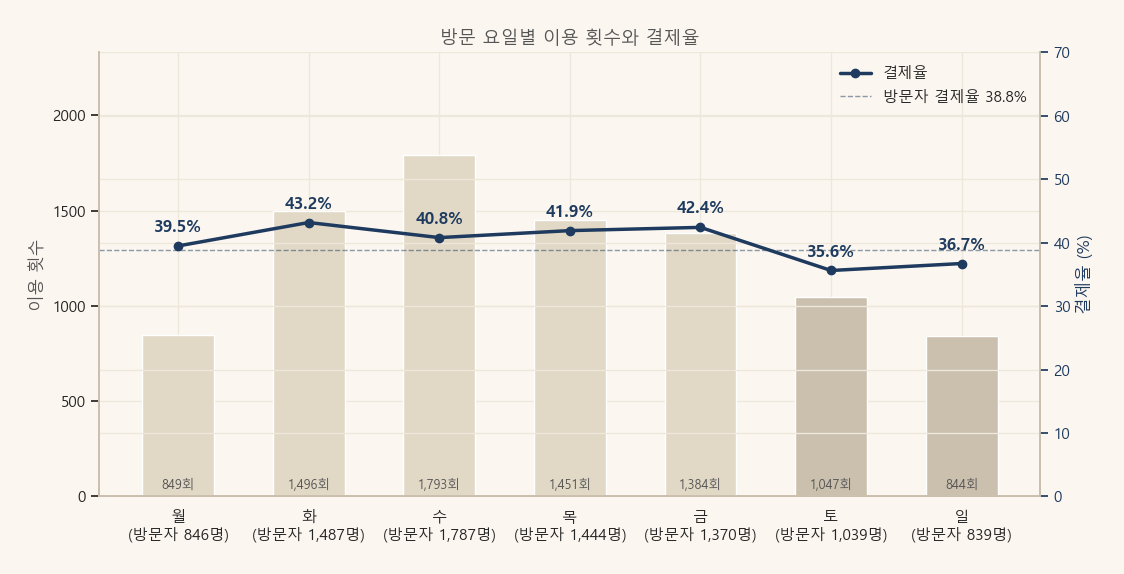

In [34]:
WEEKDAYS = ['월', '화', '수', '목', '금', '토', '일']

# 요일별 이용 횟수
use_cnt = visit_day.groupby('weekday').size()

# 요일별 방문 사용자의 결제율
wd_user = visit_day[['user_uuid', 'weekday']].drop_duplicates().merge(pay[['user_uuid', 'is_payment']], on='user_uuid')
wd_rate = wd_user.groupby('weekday')['is_payment'].mean()
wd_users = wd_user.groupby('weekday')['user_uuid'].nunique()

x = range(7)
visitor_rate = u.loc[u['visited'] == 1, 'is_payment'].mean()

fig, ax1 = plt.subplots(figsize=(11, 5.5))

# 주말만 진하게
bar_colors = [BEIGE_L] * 5 + [BEIGE] * 2
ax1.bar(x, use_cnt.values, color=bar_colors, width=0.55)
for i, c in enumerate(use_cnt.values):
    ax1.text(i, 40, f'{c:,}회', ha='center', fontsize=9, color=DARK)

ax1.set_xticks(list(x))
ax1.set_xticklabels([f'{w}\n(방문자 {n:,}명)' for w, n in zip(WEEKDAYS, wd_users.values)])
ax1.set_ylabel('이용 횟수', color=DARK)
ax1.set_ylim(0, use_cnt.max() * 1.3)
ax1.spines[['top']].set_visible(False)

ax2 = ax1.twinx()
ax2.plot(x, wd_rate.values * 100, color=NAVY, marker='o', linewidth=2.5, label='결제율')
for i, r in enumerate(wd_rate.values * 100):
    ax2.annotate(f'{r:.1f}%', (i, r), textcoords='offset points', xytext=(0, 10), ha='center', color=NAVY, fontweight='bold')

ax2.axhline(visitor_rate * 100, color=NAVY, linestyle='--', linewidth=1, alpha=0.5, label=f'방문자 결제율 {visitor_rate:.1%}')
ax2.legend(frameon=False, loc='upper right')
ax2.set_ylabel('결제율 (%)', color=NAVY)
ax2.set_ylim(0, 70)
ax2.tick_params(axis='y', colors=NAVY)
ax2.spines[['top']].set_visible(False)

ax1.set_title('방문 요일별 이용 횟수와 결제율', fontsize=13, color=DARK)

plt.tight_layout()
plt.show()

- 이용 횟수는 수요일이 가장 많고 일·월요일이 가장 적다.
- 화\~금요일 방문자의 결제율은 40.8\~43.2%로 방문자 결제율보다 높고, 토요일(35.6%)과 일요일(36.7%)은 낮다.

## 3.7 지점별 이용 횟수와 결제율

- 막대: 지점별 이용 횟수, 선: 그 지점을 한 번이라도 이용한 사용자의 결제율, 지점 번호 아래 인원: 그 지점을 이용한 사용자 수

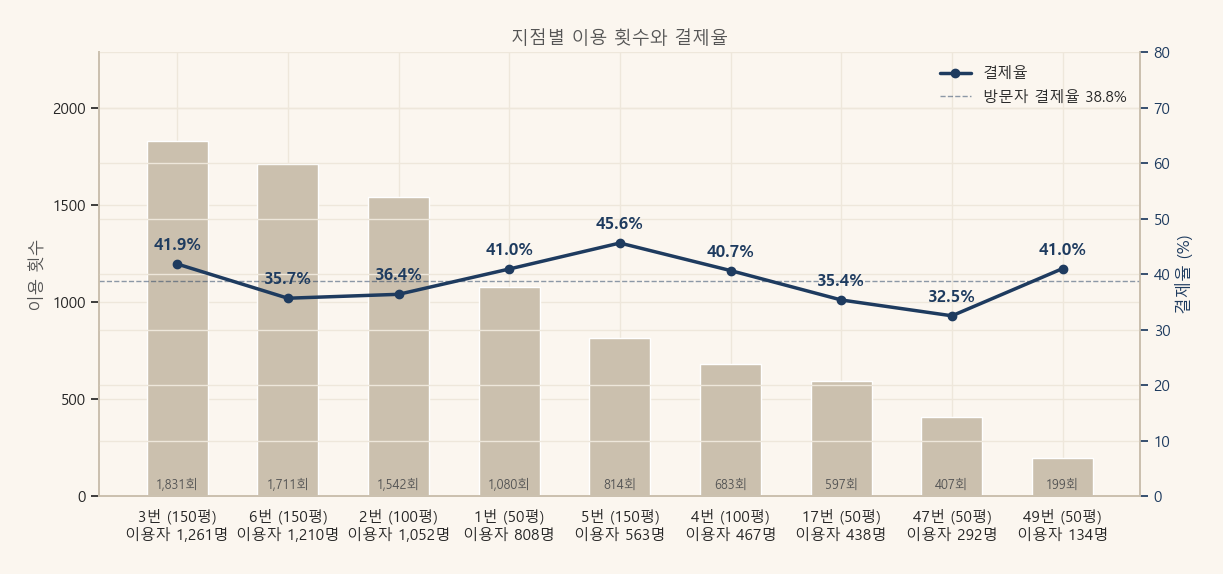

In [35]:
area_map = area.set_index('site_id')['area_pyeong']

# 지점별 이용 횟수 (많은 순)
site_cnt = visit_day.groupby('site_id').size().sort_values(ascending=False)

# 지점별 이용 사용자의 결제율
site_user = visit_day[['user_uuid', 'site_id']].drop_duplicates().merge(pay[['user_uuid', 'is_payment']], on='user_uuid')
site_rate = site_user.groupby('site_id')['is_payment'].mean().reindex(site_cnt.index)
site_users = site_user.groupby('site_id')['user_uuid'].nunique().reindex(site_cnt.index)

x = range(len(site_cnt))
visitor_rate = u.loc[u['visited'] == 1, 'is_payment'].mean()

fig, ax1 = plt.subplots(figsize=(12, 5.5))

ax1.bar(x, site_cnt.values, color=BEIGE, width=0.55)
for i, c in enumerate(site_cnt.values):
    ax1.text(i, 40, f'{c:,}회', ha='center', fontsize=9, color=DARK)

ax1.set_xticks(list(x))
ax1.set_xticklabels([f'{s}번 ({area_map[s]}평)\n이용자 {n:,}명' for s, n in zip(site_cnt.index, site_users.values)])
ax1.set_ylabel('이용 횟수', color=DARK)
ax1.set_ylim(0, site_cnt.max() * 1.25)
ax1.spines[['top']].set_visible(False)

ax2 = ax1.twinx()
ax2.plot(x, site_rate.values * 100, color=NAVY, marker='o', linewidth=2.5, label='결제율')
for i, r in enumerate(site_rate.values * 100):
    ax2.annotate(f'{r:.1f}%', (i, r), textcoords='offset points', xytext=(0, 10), ha='center', color=NAVY, fontweight='bold')

ax2.axhline(visitor_rate * 100, color=NAVY, linestyle='--', linewidth=1, alpha=0.5, label=f'방문자 결제율 {visitor_rate:.1%}')
ax2.legend(frameon=False, loc='upper right')
ax2.set_ylabel('결제율 (%)', color=NAVY)
ax2.set_ylim(0, 80)
ax2.tick_params(axis='y', colors=NAVY)
ax2.spines[['top']].set_visible(False)

ax1.set_title('지점별 이용 횟수와 결제율', fontsize=13, color=DARK)

plt.tight_layout()
plt.show()

- 이용 횟수는 3번(150평), 6번(150평), 2번(100평) 순으로 많다.
- 결제율은 5번(45.6%)이 가장 높고 47번(32.5%)이 가장 낮다. 이용 횟수가 많은 6번과 2번 지점은 방문자 결제율보다 낮다.
- 면적과 결제율 사이에는 일관된 관계가 나타나지 않는다.

## 3.8 방문 시간대별 결제율

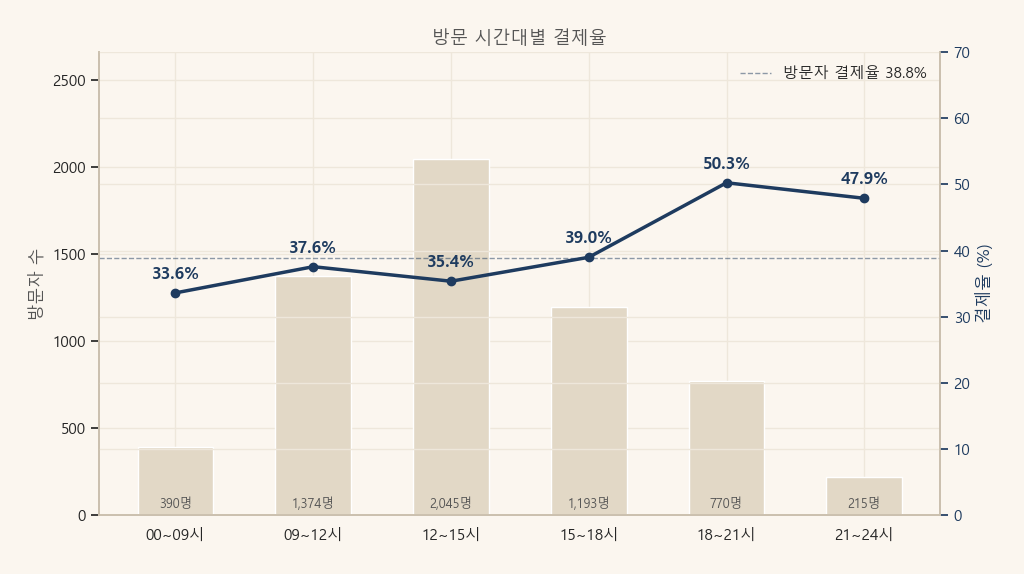

In [36]:
# 첫 입실 시각
first_in = ent.sort_values('cdate').drop_duplicates('user_uuid').set_index('user_uuid')['cdate']
u['first_hour'] = u['user_uuid'].map(first_in.dt.hour + first_in.dt.minute / 60)

HOUR_BINS = [0, 9, 12, 15, 18, 21, 24]
HOUR_LABELS = ['00~09시', '09~12시', '12~15시', '15~18시', '18~21시', '21~24시']

vis = u[u['visited'] == 1].copy()
vis['hour_bin'] = pd.cut(vis['first_hour'], bins=HOUR_BINS, labels=HOUR_LABELS, include_lowest=True)

hour_cnt = vis.groupby('hour_bin', observed=True).size().reindex(HOUR_LABELS)
hour_rate = vis.groupby('hour_bin', observed=True)['is_payment'].mean().reindex(HOUR_LABELS)
visitor_rate = vis['is_payment'].mean()

x = range(len(HOUR_LABELS))
fig, ax1 = plt.subplots(figsize=(10, 5.5))

ax1.bar(x, hour_cnt.values, color=BEIGE_L, width=0.55)
for i, c in enumerate(hour_cnt.values):
    ax1.text(i, 40, f'{c:,}명', ha='center', fontsize=9, color=DARK)

ax1.set_xticks(list(x))
ax1.set_xticklabels(HOUR_LABELS)
ax1.set_ylabel('방문자 수', color=DARK)
ax1.set_ylim(0, hour_cnt.max() * 1.3)
ax1.spines[['top']].set_visible(False)

ax2 = ax1.twinx()
rate_vals = hour_rate.values * 100
ax2.plot(x, rate_vals, color=NAVY, marker='o', linewidth=2.5)
for i, r in enumerate(rate_vals):
    ax2.annotate(f'{r:.1f}%', (i, r), textcoords='offset points', xytext=(0, 10), ha='center', color=NAVY, fontweight='bold')

ax2.axhline(visitor_rate * 100, color=NAVY, linestyle='--', linewidth=1, alpha=0.5, label=f'방문자 결제율 {visitor_rate:.1%}')
ax2.legend(frameon=False, loc='upper right')
ax2.set_ylabel('결제율 (%)', color=NAVY)
ax2.set_ylim(0, 70)
ax2.tick_params(axis='y', colors=NAVY)
ax2.spines[['top']].set_visible(False)

ax1.set_title('방문 시간대별 결제율', fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

- 첫 입실이 18시 이후인 사용자의 결제율이 뚜렷하게 높다. 18\~21시 50.3%, 21\~24시 47.9%로 방문자 결제율(38.8%)보다 9\~12%p 높다. 4.1의 `any_evening` 피처는 이 관찰을 근거로 만든다.
- 낮 시간대의 결제율은 방문자 결제율과 비슷하거나 낮다. 12\~15시가 35.4%로 가장 낮고, 이 구간에 방문자가 2,045명으로 가장 많다.
- 00\~09시의 결제율도 33.6%로 낮지만, 표본이 390명으로 적어 추정의 불확실성이 크다.
- 저녁 방문과 체류시간은 함께 고려할 필요가 있다. 늦게 오면 머무는 시간도 짧아지므로, 4.1에서 두 피처(`any_evening`, `avg_stay_h`)를 함께 고려해 각각의 관계를 살펴본다.

# **4. 모델링**

## 4.1 모델 테이블 만들기 (방문자 1명 = 1행)

- 대상: 1\~3일차에 한 번 이상 방문한 사용자
- 타깃: `is_payment` (결제 = 1)
- 체류시간을 알 수 없는 방문자 193명(3.5의 표 참고)은 제외한다.
- `site_rate`(주 이용 지점의 결제율)는 학습 데이터로만 계산해야 하므로 여기서는 `main_site`만 만들고, 학습·평가 분할 뒤에 계산한다.

| 피처 | 의미 |
|---|---|
| `visit_days` | 1\~3일차 방문일수 |
| `day1`, `day2`, `day3` | 일차별 방문 여부 |
| `lead_day` | 처음 방문한 일차(1\~3일차) |
| `avg_stay_h` | 방문일당 평균 체류시간 |
| `stay_lt1`, `stay_1_4`, `stay_6p` | 일평균 체류시간 구간 (1시간 미만 / 1\~4시간 / 6시간 이상, 기준 구간은 4\~6시간) |
| `tags_per_day` | 방문일당 입실 태그 수 (2.5에서 60분 이내 연속 입실을 정리한 뒤 기준) |
| `any_evening` | 방문일별 첫 입실이 18시 이후인 날이 하루라도 있으면 1 (3.8에서 18시 이후 첫 입실의 결제율이 높음) |
| `weekend_ratio` | 방문일 중 주말 비율 |
| `n_sites` | 이용 지점 수 |
| `month_idx` | 신청 시점 (2021년 5월 = 0) |

In [37]:
# 방문일 단위 (사용자, 방문일) : 하루에 여러 지점을 가도 하루로 센다
vday = (
    visit_day[['user_uuid', 'visit_date', 'day_n', 'weekday']]
    .drop_duplicates(['user_uuid', 'visit_date'])
)

# 일차별 방문 여부 (day1, day2, day3)
day_flag = (
    pd.crosstab(vday['user_uuid'], vday['day_n'])
    .reindex(columns=[1, 2, 3], fill_value=0)
    .clip(upper=1)
)
day_flag.columns = ['day1', 'day2', 'day3']

# 주말 비율 = 주말(토·일) 방문일 / 방문일수
weekend_ratio = (
    vday.assign(is_weekend=vday['weekday'] >= 5)
    .groupby('user_uuid')['is_weekend']
    .mean()
    .rename('weekend_ratio')
)

# 입실 태그 수 (2.5에서 60분 이내 연속 입실을 정리한 뒤 기준)
n_tags = ent.groupby('user_uuid').size().rename('n_tags')

# 저녁 방문 여부 : 방문일별 첫 입실이 18시 이후인 날이 하루라도 있으면 1 (3.8)
day_first_in = ent.groupby(['user_uuid', 'visit_date'])['cdate'].min()
any_evening = (
    (day_first_in.dt.hour >= 18)
    .groupby('user_uuid')
    .max()
    .astype(int)
    .rename('any_evening')
)

# 주 이용 지점 : 방문일이 가장 많은 지점, 같으면 체류시간이 긴 지점
site_use = (
    visit_day
    .groupby(['user_uuid', 'site_id'])
    .agg(days=('visit_date', 'nunique'), stay=('stay_sec', 'sum'))
    .reset_index()
)
main_site = (
    site_use
    .sort_values(['user_uuid', 'days', 'stay'], ascending=[True, False, False])
    .drop_duplicates('user_uuid')
    .set_index('user_uuid')['site_id']
    .rename('main_site')
)

# 방문자만 남기고 피처 붙이기
model_df = (
    u.loc[u['visited'] == 1, ['user_uuid', 'trial_date', 'is_payment',
                              'visit_days', 'lead_day', 'avg_stay_h', 'n_sites']]
    .set_index('user_uuid')
    .join([day_flag, weekend_ratio, n_tags, any_evening, main_site])
)

model_df['lead_day'] = model_df['lead_day'].astype(int)
model_df['n_sites'] = model_df['n_sites'].astype(int)
model_df['tags_per_day'] = model_df['n_tags'] / model_df['visit_days']

# 신청 시점 : 2021년 5월 = 0
model_df['month_idx'] = (
    (model_df['trial_date'].dt.year - 2021) * 12
    + model_df['trial_date'].dt.month - 5
)

# 체류시간을 알 수 없는 방문자 제외
before = len(model_df)
model_df = model_df[model_df['avg_stay_h'].notna()].copy()

# 일평균 체류시간 구간 (3.5에서 결제율이 역 U자형 관계를 보여 선형항만으로는 표현하기 어렵다)
# 기준 구간은 4~6시간이며, 더미 세 개는 그 구간 대비 차이를 뜻한다.
model_df['stay_lt1'] = (model_df['avg_stay_h'] < 1).astype(int)
model_df['stay_1_4'] = model_df['avg_stay_h'].between(1, 4, inclusive='left').astype(int)
model_df['stay_6p'] = (model_df['avg_stay_h'] >= 6).astype(int)

# 컬럼 순서 정리
model_df = model_df[[
    'trial_date', 'main_site',                                    # 분할·site_rate 계산용
    'visit_days', 'day1', 'day2', 'day3', 'lead_day',             # 방문
    'avg_stay_h', 'stay_lt1', 'stay_1_4', 'stay_6p',              # 체류시간 (선형 + 구간)
    'tags_per_day', 'any_evening', 'weekend_ratio',               # 이용 행동
    'n_sites', 'month_idx',                                       # 지점 수, 신청 시점
    'is_payment'                                                  # 타깃
]].reset_index()

print(f'방문자 {before:,}명 → 체류시간 결측 제외 후 {len(model_df):,}명 ({before - len(model_df)}명 제외)')
print('결제율 :', f"{model_df['is_payment'].mean():.1%}")
print('결측치 :', model_df.isna().sum().sum())
display(model_df.head())
display(model_df.describe().T.round(2))

방문자 5,987명 → 체류시간 결측 제외 후 5,794명 (193명 제외)
결제율 : 38.9%
결측치 : 0


,user_uuid,trial_date,main_site,visit_days,day1,day2,day3,lead_day,avg_stay_h,stay_lt1,stay_1_4,stay_6p,tags_per_day,any_evening,weekend_ratio,n_sites,month_idx,is_payment
0,e079e682-62f2-4c05-84b9-86913e3dc146,2021-05-01,3,1,0,1,0,2,2.750341,0,1,0,3.0,1,1.0,1,0,0
1,fce967b5-070c-46ed-a5fa-ef7d298cc7aa,2021-05-01,1,1,0,0,1,3,2.372412,0,1,0,1.0,0,0.0,1,0,1
2,22aad31c-1958-4c83-bfde-099d70765447,2021-05-03,3,1,0,1,0,2,3.842805,0,1,0,2.0,0,0.0,1,0,1
3,e5a39f9e-88be-4507-95d8-ceedcee175e4,2021-05-04,2,1,0,0,1,3,6.126315,0,0,1,3.0,0,0.0,1,0,0
4,e0e372b4-7f33-498b-ba1a-895aaffe18ff,2021-05-04,3,1,0,1,0,2,4.367291,0,0,0,5.0,0,0.0,1,0,0


,count,mean,min,25%,50%,75%,max,std
trial_date,5794,2022-08-26 21:50:15.947532,2021-05-01 00:00:00,2021-12-08 06:00:00,2022-08-22 00:00:00,2023-05-04 00:00:00,2023-12-28 00:00:00,NaN
main_site,5794.0,7.451674,1.0,2.0,4.0,6.0,49.0,11.559877
visit_days,5794.0,1.485502,1.0,1.0,1.0,2.0,3.0,0.609675
day1,5794.0,0.275112,0.0,0.0,0.0,1.0,1.0,0.446609
day2,5794.0,0.681395,0.0,0.0,1.0,1.0,1.0,0.465976
day3,5794.0,0.528996,0.0,0.0,1.0,1.0,1.0,0.499202
lead_day,5794.0,1.883673,1.0,1.0,2.0,2.0,3.0,0.648412
avg_stay_h,5794.0,4.261294,0.001274,2.213739,3.949387,5.994909,12.0,2.586753
stay_lt1,5794.0,0.108733,0.0,0.0,0.0,0.0,1.0,0.311331
stay_1_4,5794.0,0.397653,0.0,0.0,0.0,1.0,1.0,0.489455


## 4.2 피처 상관관계와 다중공선성 점검

- 피처 간 중복이 크면 로지스틱 회귀 계수가 불안정해지고, 트리 모델의 중요도가 여러 피처에 나뉘어 해석이 어려워진다.
- 스피어만 상관계수로 피처 쌍의 관계를 보고, VIF(분산팽창계수)로 한 피처가 다른 피처들로 어느 정도 설명되는지 확인한다. VIF가 10을 넘으면 다중공선성이 있다고 판단한다.
- 타깃을 사용하지 않는 점검이므로 전체 모델 테이블로 계산한다. `site_rate`는 학습·평가 분할 뒤에 만들므로 여기서는 제외한다.

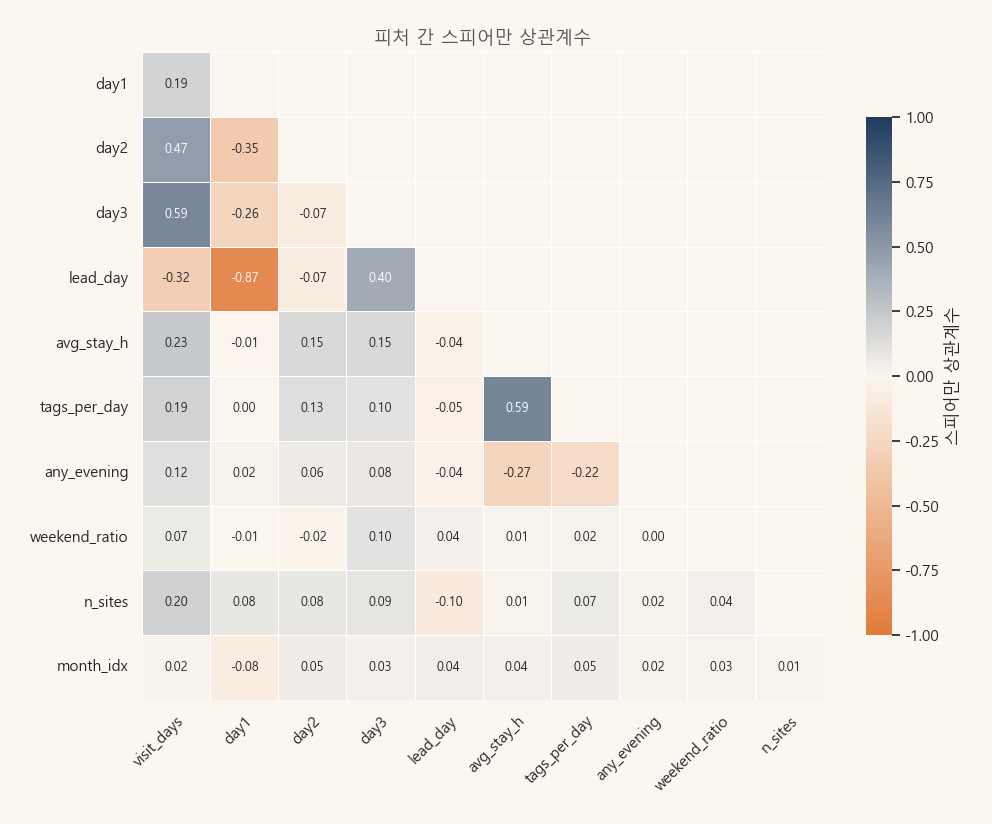

,level_0,level_1,rho
45,lead_day,day1,-0.87
71,tags_per_day,avg_stay_h,0.59
33,day3,visit_days,0.59


In [38]:
FEATURES = [
    'visit_days', 'day1', 'day2', 'day3', 'lead_day',
    'avg_stay_h', 'tags_per_day', 'any_evening', 'weekend_ratio',
    'n_sites', 'month_idx'
]

corr = model_df[FEATURES].corr(method='spearman')

# 아래 삼각형만 표시 (대각선과 빈 첫 행·마지막 열 제외)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr.iloc[1:, :-1], mask=mask[1:, :-1], cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 9},
    linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': '스피어만 상관계수'}, ax=ax
)
ax.grid(False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
ax.set_title('피처 간 스피어만 상관계수', fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

# 절댓값 0.5 이상인 쌍
pairs = (
    corr.where(~mask)
    .stack()
    .rename('rho')
    .reset_index()
    .query('abs(rho) >= 0.5')
    .sort_values('rho', key=abs, ascending=False)
)
display(pairs.round(2))

In [39]:
def calc_vif(df, cols):
    """각 피처를 나머지 피처로 선형회귀했을 때의 R²로 VIF = 1 / (1 - R²)를 구한다."""
    X = df[cols].astype(float)
    vif = {}
    for c in cols:
        y = X[c].values
        A = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        vif[c] = np.inf if r2 > 1 - 1e-10 else 1 / (1 - r2)
    return pd.Series(vif, name='VIF').round(2)


print('전체 피처 VIF')
display(calc_vif(model_df, FEATURES).to_frame())

# visit_days = day1 + day2 + day3 인지 확인
same = (model_df['visit_days'] == model_df[['day1', 'day2', 'day3']].sum(axis=1)).mean()
print(f'visit_days = day1 + day2 + day3 인 행 비율 : {same:.1%}')

전체 피처 VIF


,VIF
visit_days,inf
day1,inf
day2,inf
day3,inf
lead_day,11.38
avg_stay_h,1.60
tags_per_day,1.49
any_evening,1.12
weekend_ratio,1.01
n_sites,1.05


visit_days = day1 + day2 + day3 인 행 비율 : 100.0%


- `visit_days`는 `day1 + day2 + day3`와 모든 행에서 같다. 네 피처를 함께 넣으면 한 피처가 나머지로 완전히 설명되어 VIF가 무한대가 된다.
- `lead_day`는 `day1`과 상관계수 -0.86으로, 일차별 방문 여부로 거의 결정된다.
- 나머지 피처는 VIF가 1.6 이하다. 가장 높은 상관은 `avg_stay_h`와 `tags_per_day`(0.59)이지만 다중공선성 기준에는 미치지 않는다.

방문 관련 피처(`visit_days`, `day1`\~`day3`, `lead_day`) 중 무엇을 남길지 조합별로 비교한다.

In [40]:
BASE = ['avg_stay_h', 'tags_per_day', 'any_evening', 'weekend_ratio', 'n_sites', 'month_idx']

candidates = {
    'A. day1 + day2 + day3': ['day1', 'day2', 'day3'],
    'B. visit_days + day3 + lead_day': ['visit_days', 'day3', 'lead_day'],
    'C. visit_days + lead_day': ['visit_days', 'lead_day'],
}

rows = []
for name, visit_cols in candidates.items():
    vif = calc_vif(model_df, visit_cols + BASE)
    rows.append({
        '조합': name,
        '방문 피처 최대 VIF': vif[visit_cols].max(),
        '전체 최대 VIF': vif.max(),
    })

display(pd.DataFrame(rows).set_index('조합'))

,방문 피처 최대 VIF,전체 최대 VIF
조합,,
A. day1 + day2 + day3,1.32,1.60
B. visit_days + day3 + lead_day,4.51,4.51
C. visit_days + lead_day,1.30,1.59


| 조합 | 방문 정보 | 방문 피처 최대 VIF | 판단 |
|---|---|---|---|
| A. `day1`, `day2`, `day3` | 모두 보존 (`visit_days`, `lead_day`를 계산할 수 있음) | 1.3 | 가장 낮다. 일차별 방문 여부로 바로 해석된다 |
| B. `visit_days`, `day3`, `lead_day` | 모두 보존 (`day1`, `day2`를 계산할 수 있음) | 4.5 | 처음 정한 피처 구성이다. VIF가 10을 넘지 않아 사용할 수 있지만, A·C(1.3)보다 높다 |
| C. `visit_days`, `lead_day` | 일부 손실 (예: 2일 방문, 1일차 시작이면 1·2일차인지 1·3일차인지 구분할 수 없음) | 1.3 | 3일차 방문 정보가 사라진다 |

A와 B가 포함하는 정보는 같다. 모든 모델에 동일한 피처를 사용해 비교할 때는 VIF가 가장 낮은 A가 더 안정적이다.

## 4.3 피처 확정

4.2의 A 조합으로 방문 피처를 정리한다. `visit_days`와 `lead_day`는 `day1`\~`day3`로 계산할 수 있어 정보 손실 없이 뺀다.

체류시간은 선형항 `avg_stay_h`에 구간 더미 세 개를 추가한다. 3.5에서 결제율이 중간 구간에서 가장 높은 비선형 관계로 나타나, 선형항만으로는 단시간 구간의 하락을 표현하기 어렵기 때문이다. 기준 구간은 4\~6시간이다.

이 네 피처는 동일한 원변수에서 파생되어 정보가 중복된다. 아래 VIF에서 `avg_stay_h`가 7.8, 구간 더미가 3.1\~3.3으로 나머지 피처(1.0\~1.5)보다 높다. 4.2에서 정한 기준인 10은 넘지 않으므로 함께 쓰되, 계수는 네 피처를 묶어서 해석한다.

| 구분 | 피처 |
|---|---|
| 방문 | `day1`, `day2`, `day3` |
| 체류시간 | `avg_stay_h`, `stay_lt1`, `stay_1_4`, `stay_6p` |
| 이용 행동 | `tags_per_day`, `any_evening`, `weekend_ratio` |
| 지점 | `n_sites`, `site_rate` (4.4에서 학습 데이터로 계산) |
| 신청 시점 | `month_idx` |

In [41]:
FEATURES_FINAL = [
    'day1', 'day2', 'day3',                                       # 방문
    'avg_stay_h', 'stay_lt1', 'stay_1_4', 'stay_6p',              # 체류시간 (선형 + 구간)
    'tags_per_day', 'any_evening', 'weekend_ratio',               # 이용 행동
    'n_sites', 'site_rate',                                       # 지점
    'month_idx',                                                  # 신청 시점
]
TARGET = 'is_payment'

print('피처 수 :', len(FEATURES_FINAL))

# site_rate를 뺀 나머지 피처의 VIF 확인
display(calc_vif(model_df, [f for f in FEATURES_FINAL if f != 'site_rate']).to_frame())

피처 수 : 13


,VIF
day1,1.33
day2,1.28
day3,1.21
avg_stay_h,7.80
stay_lt1,3.33
stay_1_4,3.09
stay_6p,3.18
tags_per_day,1.49
any_evening,1.13
weekend_ratio,1.01


## 4.4 학습·평가 데이터 분할

- 신청일을 기준으로 시간 순서에 따라 나눈다. 2021\~2022년 신청자는 학습, 2023년 신청자는 평가 데이터다.
- 무작위로 나누면 과거와 최근 데이터가 섞여 새 신청자를 예측하는 실제 상황보다 성능이 과대평가될 수 있다.
- 평가 데이터는 최종 성능 평가에 한 번만 사용한다.

In [42]:
SPLIT_DATE = pd.Timestamp('2023-01-01')

train_df = model_df[model_df['trial_date'] < SPLIT_DATE].copy()
test_df = model_df[model_df['trial_date'] >= SPLIT_DATE].copy()

split_summary = pd.DataFrame({
    '기간': [
        f"{train_df['trial_date'].min():%Y-%m-%d} ~ {train_df['trial_date'].max():%Y-%m-%d}",
        f"{test_df['trial_date'].min():%Y-%m-%d} ~ {test_df['trial_date'].max():%Y-%m-%d}",
    ],
    '인원': [len(train_df), len(test_df)],
    '비율': [len(train_df) / len(model_df), len(test_df) / len(model_df)],
    '결제율': [train_df[TARGET].mean(), test_df[TARGET].mean()],
}, index=['학습', '평가'])

display(split_summary.style.format({'인원': '{:,}', '비율': '{:.1%}', '결제율': '{:.1%}'}))

,기간,인원,비율,결제율
학습,2021-05-01 ~ 2022-12-30,"3,635",62.7%,42.0%
평가,2023-01-02 ~ 2023-12-28,"2,159",37.3%,33.6%


- `site_rate`: 주 이용 지점의 결제율

  평가 데이터의 결제 정보가 섞이지 않도록 학습 데이터로만 지점별 결제율을 계산해 두 데이터에 적용한다. 학습 데이터에 없는 지점은 학습 데이터 전체 결제율로 채운다.

In [43]:
site_rate_map = train_df.groupby('main_site')[TARGET].mean()
train_rate = train_df[TARGET].mean()

train_df['site_rate'] = train_df['main_site'].map(site_rate_map)
test_df['site_rate'] = test_df['main_site'].map(site_rate_map).fillna(train_rate)

# 지점별 학습 인원과 결제율
site_table = (
    train_df.groupby('main_site')[TARGET]
    .agg(학습_인원='size', 결제율='mean')
    .join(test_df.groupby('main_site').size().rename('평가_인원'))
    .fillna({'평가_인원': 0})
    .astype({'평가_인원': int})
    .sort_values('학습_인원', ascending=False)
)
display(site_table.style.format({'결제율': '{:.1%}'}))

unseen = set(test_df['main_site']) - set(site_rate_map.index)
print('학습 데이터에 없는 평가 지점 :', sorted(unseen) if unseen else '없음')

,학습_인원,결제율,평가_인원
main_site,,,
3,813,44.4%,364
2,670,39.6%,321
6,632,39.2%,481
1,501,43.9%,224
5,415,46.7%,128
4,355,42.8%,94
17,159,36.5%,238
47,90,31.1%,186


학습 데이터에 없는 평가 지점 : [49]


In [44]:
X_train, y_train = train_df[FEATURES_FINAL], train_df[TARGET]
X_test, y_test = test_df[FEATURES_FINAL], test_df[TARGET]

print('X_train :', X_train.shape, '/ X_test :', X_test.shape)
print('결측치 :', X_train.isna().sum().sum(), '/', X_test.isna().sum().sum())
print(f'결제율 : 학습 {y_train.mean():.1%} / 평가 {y_test.mean():.1%}')

X_train : (3635, 13) / X_test : (2159, 13)
결측치 : 0 / 0
결제율 : 학습 42.0% / 평가 33.6%


- 확인 사항

  1. 49번 지점은 2023년 4월에 처음 나오는 지점이라 학습 데이터에 이용자가 없다. 따라서 이 지점을 주로 이용한 평가 데이터에 포함된 123명은 `site_rate`를 계산할 수 없어, 학습 데이터 전체 결제율(42.0%)로 채웠다. 방문·결제 기록 자체는 정상이다. 새 지점은 과거 기록이 없으므로 실제 운영에서도 같은 상황이 생긴다.

  2. `site_rate`는 학습 데이터 전체의 결제 정보로 만들었다. 학습 데이터 안에서 교차검증을 하면 검증 구간의 결제 정보가 `site_rate`에 이미 포함된다. 지점이 9개이고 지점마다 인원이 수백 명이라 영향은 제한적이지만, 엄밀하게 계산하려면 교차검증 구간마다 `site_rate`를 다시 계산해야 한다.

  3. 모델을 사용하지 않고 대상자를 무작위로 선정하면, 정밀도는 평가 데이터의 결제율과 같은 33.6%가 된다. 따라서 모델의 정밀도는 33.6%보다 높아야 의미가 있다. 학습 기간의 결제율(42.0%)은 평가 기간과 다르므로 비교 기준으로 쓰지 않는다.

## 4.5 모델 학습과 교차검증

- 모델: 로지스틱 회귀, 랜덤포레스트, XGBoost, LightGBM
- 학습 데이터(2021\~2022년)만 사용해 모델과 하이퍼파라미터를 선택한다. 평가 데이터는 4.6에서 한 번만 쓴다.
- 교차검증: 층화 5겹 교차검증을 사용한다. 각 폴드의 결제 비율을 유지하면서 학습과 검증을 5번 반복한다.
- `site_rate`는 평균 타깃 인코딩(Mean Target Encoding) 방식이므로, 검증 폴드의 결제 정보가 섞이면 데이터 누출이 생긴다. 각 반복에서 학습 폴드 4개만 사용해 다시 계산한 뒤 검증 폴드 1개에 적용한다.
- `GridSearchCV`는 각 반복에서 `site_rate`를 다시 계산할 수 없어, 같은 방식을 반복문으로 직접 구현한다.
- 로지스틱 회귀는 값의 크기에 민감하므로 스케일링을 파이프라인에 넣는다.
- LightGBM은 데이터가 수천 건 이하면 과적합이 심하므로 `num_leaves`와 `max_depth`를 작게 제한한다.
- 하이퍼파라미터는 교차검증 AUC 평균으로 고르고, 상위 20%·30% 정밀도를 함께 본다.

In [45]:
from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def add_site_rate(fit_df, apply_df):
    """fit_df의 지점별 결제율을 apply_df에 붙인다. fit_df에 없는 지점은 fit_df 전체 결제율로 채운다."""
    rate_map = fit_df.groupby('main_site')[TARGET].mean()
    return apply_df['main_site'].map(rate_map).fillna(fit_df[TARGET].mean())


def precision_at_k(y_true, score, k):
    """결제 확률 상위 k 비율을 결제 예상군으로 선정했을 때의 정밀도"""
    n = int(np.ceil(len(score) * k))
    top = np.argsort(-np.asarray(score))[:n]
    return np.asarray(y_true)[top].mean()


def cv_scores(model, features=None):
    """층화 5겹 교차검증 점수. 각 반복에서 site_rate를 학습 폴드로만 다시 계산한다.
    features를 주지 않으면 FEATURES_FINAL을 쓴다."""
    features = FEATURES_FINAL if features is None else features
    rows = []
    for tr_idx, va_idx in skf.split(train_df, train_df[TARGET]):
        tr = train_df.iloc[tr_idx].copy()
        va = train_df.iloc[va_idx].copy()
        tr['site_rate'] = add_site_rate(tr, tr)
        va['site_rate'] = add_site_rate(tr, va)

        fitted = clone(model).fit(tr[features], tr[TARGET])
        prob = fitted.predict_proba(va[features])[:, 1]
        rows.append({
            'AUC': roc_auc_score(va[TARGET], prob),
            '상위 20% 정밀도': precision_at_k(va[TARGET], prob, 0.2),
            '상위 30% 정밀도': precision_at_k(va[TARGET], prob, 0.3),
        })
    return pd.DataFrame(rows)

In [46]:
models = {
    '로지스틱 회귀': (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        {'logisticregression__C': [0.01, 0.1, 1, 10]},
    ),
    '랜덤포레스트': (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {'max_depth': [4, 6, 8], 'min_samples_leaf': [5, 20]},
    ),
    'XGBoost': (
        XGBClassifier(n_estimators=200, subsample=0.8, colsample_bytree=0.8,
                      eval_metric='logloss', random_state=RANDOM_STATE),
        {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.1]},
    ),
    'LightGBM': (
        LGBMClassifier(n_estimators=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=RANDOM_STATE, verbose=-1),
        {'num_leaves': [7, 15], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.1]},
    ),
}

results = []
for name, (base, grid) in models.items():
    for params in ParameterGrid(grid):
        scores = cv_scores(clone(base).set_params(**params))
        results.append({
            '모델': name,
            '하이퍼파라미터': params,
            'AUC 평균': scores['AUC'].mean(),
            'AUC 표준편차': scores['AUC'].std(),
            '상위 20% 정밀도': scores['상위 20% 정밀도'].mean(),
            '상위 30% 정밀도': scores['상위 30% 정밀도'].mean(),
        })

cv_results = pd.DataFrame(results)
print('비교한 조합 수 :', len(cv_results))

비교한 조합 수 : 24


In [47]:
# 모델별로 AUC 평균이 가장 높은 하이퍼파라미터
best = (
    cv_results.sort_values('AUC 평균', ascending=False)
    .drop_duplicates('모델')
    .set_index('모델')
)
best_params = best['하이퍼파라미터'].to_dict()

display(best.style.format({
    'AUC 평균': '{:.3f}', 'AUC 표준편차': '{:.3f}',
    '상위 20% 정밀도': '{:.1%}', '상위 30% 정밀도': '{:.1%}',
}))
print(f"학습 데이터 결제율(교차검증 정밀도의 무작위 기준) : {train_df[TARGET].mean():.1%}")

,하이퍼파라미터,AUC 평균,AUC 표준편차,상위 20% 정밀도,상위 30% 정밀도
모델,,,,,
로지스틱 회귀,{'logisticregression__C': 0.1},0.604,0.017,56.7%,53.7%
랜덤포레스트,"{'max_depth': 6, 'min_samples_leaf': 20}",0.602,0.022,56.2%,53.2%
XGBoost,"{'learning_rate': 0.03, 'max_depth': 2}",0.601,0.019,54.2%,52.7%
LightGBM,"{'learning_rate': 0.03, 'max_depth': 3, 'num_leaves': 7}",0.600,0.018,56.0%,52.9%


학습 데이터 결제율(교차검증 정밀도의 무작위 기준) : 42.0%


- 네 모델의 교차검증 AUC 평균은 0.600\~0.604로 거의 같다. 차이(0.004)가 폴드별 표준편차(0.017\~0.022)보다 작아, 이 점수만으로 어느 모델이 낫다고 보기 어렵다.
- 상위 20%를 결제 예상군으로 선정하면 정밀도는 54\~57%, 상위 30%면 53\~54%다. 교차검증 각 검증 폴드의 결제율(42.0%)보다 11%p 이상 높다.
- 트리 모델은 모두 규제 강도가 높은 설정에서 점수가 가장 높았다. XGBoost와 LightGBM은 얕은 깊이와 낮은 학습률, 랜덤포레스트는 리프 하나에 최소 20개의 표본이 포함되는 설정이 선택됐다. 로지스틱 회귀도 규제가 더 강한 `C=0.1`이 선택됐다. 학습 데이터가 3,635명으로 비교적 적어 복잡한 모델은 과적합되는 것으로 보인다.
- 모델별로 고른 하이퍼파라미터는 `best_params`에 저장했다. 4.6에서 선택한 모델을 전체 학습 데이터로 다시 학습한 뒤 평가 데이터로 한 번 확인한다.

---
- 다음 단계: 4.6 평가 데이터로 최종 확인

  선택한 모델을 전체 학습 데이터로 다시 학습한 뒤, 2023년 평가 데이터로 최종 평가한다. 결과는 무작위로 골랐을 때의 정밀도(평가 데이터 결제율 33.6%)와 비교한다.

  팀이 정할 사항: 평가 데이터로 최종 평가할 모델

  | 방식 | 내용 | 판단 |
  |---|---|---|
  | 네 모델을 모두 평가 | 네 모델의 평가 성능을 함께 비교한다 | 평가 데이터의 결과를 보고 모델을 선택하게 되어, 선택한 모델의 성능이 실제보다 좋게 나타날 수 있다 |
  | 한 모델만 최종 평가 | 교차검증 결과로 모델을 미리 정하고 그 모델만 평가한다 | 평가 데이터를 한 번만 쓴다는 원칙에 맞다 |

  교차검증에서 네 모델의 AUC 차이(0.004)가 폴드별 표준편차보다 작아 성능으로는 우열을 가리기 어렵다. 따라서 한 모델을 미리 정하는 방식을 제안한다.

  로지스틱 회귀를 선택한다. 교차검증 AUC가 0.604로 가장 높고, 상위 20%·30% 정밀도도 네 모델 중 가장 높다. 계수의 방향으로 피처와 결제 여부의 관계를 해석하기도 쉽다. 성능과 해석 가능성을 모두 고려하면 로지스틱 회귀가 가장 적합하다.

## 4.6 평가 데이터로 최종 확인 (로지스틱 회귀)

- 교차검증에서 네 모델의 성능 차이가 작아, 해석이 쉬운 로지스틱 회귀를 사전에 선택했다. 평가 데이터로는 이 모델 하나만 최종 평가한다.
- 4.5에서 고른 하이퍼파라미터로 학습 데이터 전체(2021\~2022년)에 다시 학습한다. `site_rate`는 4.4에서 학습 데이터 전체로 계산한 값을 쓴다.
- 평가 데이터(2023년)로 최종 평가한 뒤, 무작위로 골랐을 때(정밀도 33.6%)와 비교한다.
- 결제 확률 상위 20%, 30%를 결제 예상군으로 선정했을 때의 정밀도와 재현율을 본다. 참고로 확률 0.5를 기준으로 나눈 결과도 함께 적는다.

In [48]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

final_model = clone(models['로지스틱 회귀'][0]).set_params(**best_params['로지스틱 회귀'])
final_model.fit(X_train, y_train)

test_prob = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_prob)

cv_auc = best.loc['로지스틱 회귀', 'AUC 평균']
print('하이퍼파라미터 :', best_params['로지스틱 회귀'])
print(f'교차검증 AUC {cv_auc:.3f} → 평가 AUC {test_auc:.3f}')

하이퍼파라미터 : {'logisticregression__C': 0.1}
교차검증 AUC 0.604 → 평가 AUC 0.620


In [49]:
def top_k_pred(prob, k):
    """결제 확률 상위 k 비율을 결제 예상군(1), 나머지를 비대상군(0)으로 분류"""
    n = int(np.ceil(len(prob) * k))
    pred = np.zeros(len(prob), dtype=int)
    pred[np.argsort(-prob)[:n]] = 1
    return pred


model_rows = []
for label, pred in [
    ('로지스틱 회귀 상위 20%', top_k_pred(test_prob, 0.2)),
    ('로지스틱 회귀 상위 30%', top_k_pred(test_prob, 0.3)),
    ('로지스틱 회귀 확률 0.5 기준 (참고)', (test_prob >= 0.5).astype(int)),
]:
    model_rows.append({
        '선정 방식': label,
        '결제 예상군 비율': pred.mean(),
        '정밀도': precision_score(y_test, pred),
        '재현율': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': test_auc,
    })

compare = pd.DataFrame(model_rows).set_index('선정 방식')
compare.index.name = '평가 데이터 (2023년)'

display(compare.style.format({
    '결제 예상군 비율': '{:.1%}', '정밀도': '{:.1%}', '재현율': '{:.1%}', 'F1': '{:.3f}', 'AUC': '{:.3f}'
}, na_rep='-'))

,결제 예상군 비율,정밀도,재현율,F1,AUC
평가 데이터 (2023년),,,,,
로지스틱 회귀 상위 20%,20.0%,48.6%,28.9%,0.363,0.620
로지스틱 회귀 상위 30%,30.0%,45.1%,40.2%,0.425,0.620
로지스틱 회귀 확률 0.5 기준 (참고),22.0%,47.4%,31.0%,0.375,0.620


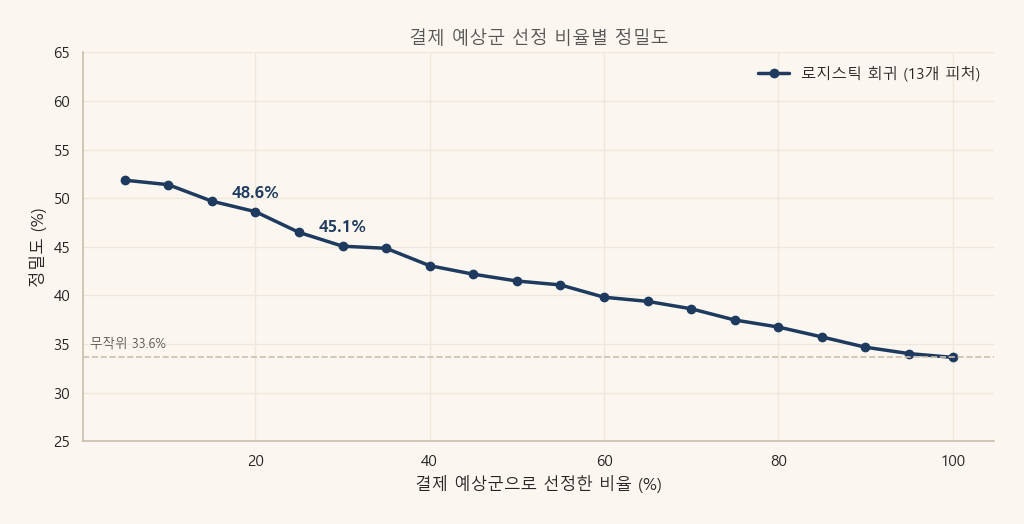

In [50]:
# 결제 확률 상위 k%마다 정밀도 (평가 데이터)
ks = np.arange(0.05, 1.0001, 0.05)
prec_by_k = [precision_at_k(y_test, test_prob, k) for k in ks]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ks * 100, np.array(prec_by_k) * 100, color=NAVY, marker='o', linewidth=2.5, label='로지스틱 회귀 (13개 피처)')
ax.axhline(y_test.mean() * 100, color=BEIGE, linestyle='--', linewidth=1.2)
ax.text(1, y_test.mean() * 100 + 1, f'무작위 {y_test.mean():.1%}', ha='left', fontsize=9, color=DARK)

for k in (0.2, 0.3):
    p = precision_at_k(y_test, test_prob, k)
    ax.annotate(f'{p:.1%}', (k * 100, p * 100), textcoords='offset points',
                xytext=(0, 10), ha='center', color=NAVY, fontweight='bold')

ax.set_xlabel('결제 예상군으로 선정한 비율 (%)')
ax.set_ylabel('정밀도 (%)')
ax.set_ylim(25, 65)
ax.set_title('결제 예상군 선정 비율별 정밀도', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
plt.show()

In [51]:
# 평가 지표의 95% 신뢰구간 (부트스트랩 2,000회)
rng = np.random.default_rng(RANDOM_STATE)

boot_auc, boot_p20 = [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    y_boot = y_test.values[idx]
    if y_boot.min() == y_boot.max():   # 한쪽 클래스만 뽑히면 AUC를 못 구한다
        continue
    boot_auc.append(roc_auc_score(y_boot, test_prob[idx]))
    boot_p20.append(precision_at_k(y_boot, test_prob[idx], 0.2))

ci = pd.DataFrame({
    '값': [test_auc, precision_at_k(y_test, test_prob, 0.2)],
    '95% 하한': [np.percentile(boot_auc, 2.5), np.percentile(boot_p20, 2.5)],
    '95% 상한': [np.percentile(boot_auc, 97.5), np.percentile(boot_p20, 97.5)],
}, index=['평가 AUC', '평가 상위 20% 정밀도'])

display(ci.style.format('{:.3f}'))

,값,95% 하한,95% 상한
평가 AUC,0.620,0.594,0.644
평가 상위 20% 정밀도,0.486,0.438,0.532


- 평가 AUC는 0.620으로 교차검증(0.604)보다 조금 높다. 학습 기간과 평가 기간이 달라도 성능이 떨어지지 않았다.
- 상위 20%를 결제 예상군으로 선정하면 정밀도 48.6%로 무작위(33.6%)보다 15.0%p 높다. 교차검증의 상위 20% 정밀도(56.7%)보다 낮은 것은 평가 기간의 결제율 자체가 낮기 때문이다. 무작위 대비 배율로 보면 교차검증 1.35배(56.7 ÷ 42.0), 평가 1.45배(48.6 ÷ 33.6)로 평가 데이터에서 오히려 더 높다.
- 모델이 예측한 결제 확률의 평균은 41.8%로, 실제 평가 기간 결제율(33.6%)보다 높다. 결제율이 높던 학습 기간으로 학습했기 때문이다. 확률 0.5를 기준으로 나누는 방식은 이 차이의 영향을 받으므로, 상위 K% 방식으로 판단한다.
- 평가 데이터는 2,159명이므로 표본 변동에 따른 지표의 불확실성이 있다. 부트스트랩 95% 신뢰구간은 AUC 0.594\~0.644, 상위 20% 정밀도 43.8\~53.2%다. AUC 신뢰구간이 무작위 기준인 0.5를 웃돌지만 교차검증 AUC(0.604)도 이 구간에 포함되므로, 앞서 언급한 "조금 높다"는 표현을 성능 향상으로 해석하지 않는다.

## 4.7 피처 중요도

4.6의 최종 모델이 결제 가능성이 높은 사용자의 순위를 정할 때 어떤 피처를 활용하는지 확인한다.

- 방법: 순열 중요도. 한 피처의 값을 사용자 간에 무작위로 재배열해 결제와의 관계를 끊은 뒤, AUC가 얼마나 감소하는지 측정한다. 감소 폭이 클수록 모델의 예측이 해당 피처에 크게 의존한다는 뜻이다. 계수의 크기와 달리 실제 예측 성능에 미치는 기여도를 직접 측정한다.
- 데이터: 학습 데이터 안에서 4.5와 같은 층화 5겹 교차검증으로 계산한다. 각 반복에서 학습 폴드로 모델을 학습하고 `site_rate`를 다시 만든 뒤, 검증 폴드에서 피처를 무작위로 재배열한다. 평가 데이터는 사용하지 않는다.
- 반복: 각 폴드에서 10번씩 무작위로 재배열해, 총 50번의 AUC 감소량을 평균한다.
- 묶음 중요도: 체류시간 네 피처는 같은 원변수에서 파생되어 서로 겹친다(4.3, VIF 최대 7.8). 하나만 무작위로 재배열하면 나머지 셋에 같은 정보가 남아 있어 중요도가 작게 측정된다. 따라서 체류시간 네 피처와 방문 일차 세 피처를 동일한 순열로 함께 재배열한 결과도 계산한다.
- 그래프: 막대는 AUC 감소량의 평균, 가로선은 표준편차다. 평균 감소량이 표준편차보다 큰 피처(묶음)는 남색, 나머지는 베이지색으로 칠했다.

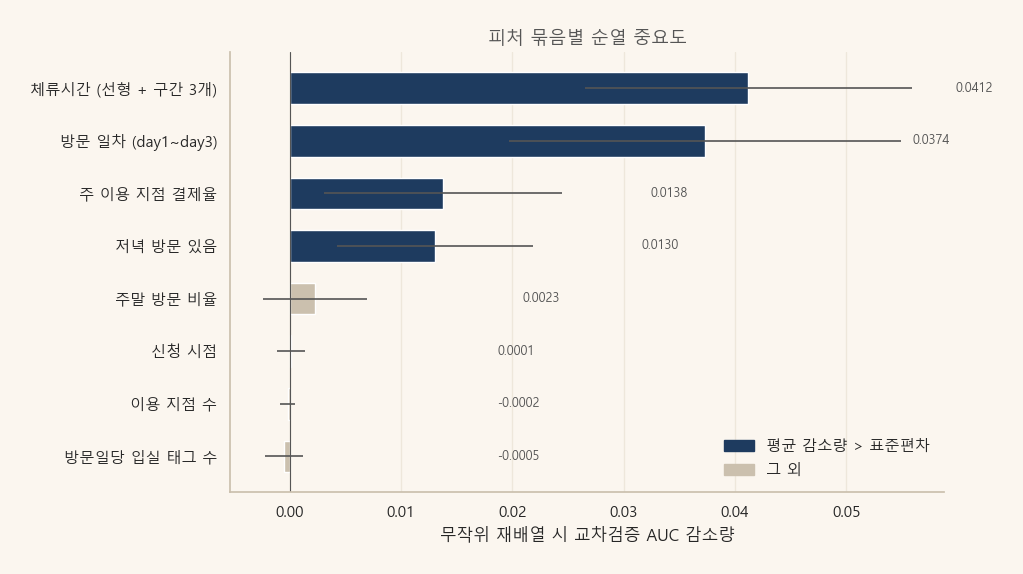

기준 : 교차검증 5개 폴드 × 10번 무작위 재배열


,AUC 감소 평균,AUC 감소 표준편차,감소가 0 이하인 비율
피처 묶음,,,
체류시간 (선형 + 구간 3개),0.0412,0.0147,0%
방문 일차 (day1~day3),0.0374,0.0176,4%
주 이용 지점 결제율,0.0138,0.0107,8%
저녁 방문 있음,0.0130,0.0088,10%
주말 방문 비율,0.0023,0.0047,30%
신청 시점,0.0001,0.0013,40%
이용 지점 수,-0.0002,0.0007,48%
방문일당 입실 태그 수,-0.0005,0.0017,44%


,AUC 감소 평균,AUC 감소 표준편차,감소가 0 이하인 비율,표준화 계수 (4.6 최종 모델)
피처,,,,
3일차 방문,0.0369,0.0156,0%,+0.252
일평균 체류시간,0.0223,0.0156,10%,-0.183
2일차 방문,0.0141,0.0101,6%,+0.159
주 이용 지점 결제율,0.0133,0.0115,14%,+0.165
저녁 방문 있음,0.0111,0.0081,12%,+0.129
체류 1~4시간,0.0105,0.0058,2%,+0.120
1일차 방문,0.0049,0.0047,14%,+0.082
주말 방문 비율,0.0023,0.0045,28%,-0.069
신청 시점,0.0003,0.0015,36%,+0.019


In [52]:
from matplotlib.patches import Patch

# 순열 중요도 : 피처(또는 묶음)를 무작위로 재배열했을 때 교차검증 AUC가 얼마나 감소하는가
FEATURE_NAMES = {
    'day1': '1일차 방문', 'day2': '2일차 방문', 'day3': '3일차 방문',
    'avg_stay_h': '일평균 체류시간', 'stay_lt1': '체류 1시간 미만',
    'stay_1_4': '체류 1~4시간', 'stay_6p': '체류 6시간 이상',
    'tags_per_day': '방문일당 입실 태그 수', 'any_evening': '저녁 방문 있음',
    'weekend_ratio': '주말 방문 비율', 'n_sites': '이용 지점 수',
    'site_rate': '주 이용 지점 결제율', 'month_idx': '신청 시점',
}

# 서로 겹치는 피처는 묶어서 함께 무작위로 재배열한다
GROUPS = {
    '방문 일차 (day1~day3)': ['day1', 'day2', 'day3'],
    '체류시간 (선형 + 구간 3개)': ['avg_stay_h', 'stay_lt1', 'stay_1_4', 'stay_6p'],
}
for f in ['tags_per_day', 'any_evening', 'weekend_ratio', 'n_sites', 'site_rate', 'month_idx']:
    GROUPS[FEATURE_NAMES[f]] = [f]

N_REPEATS = 10
rng = np.random.default_rng(RANDOM_STATE)
single_drop = {f: [] for f in FEATURES_FINAL}
group_drop = {g: [] for g in GROUPS}


def auc_drop(fitted, X_va, y_va, base_auc, cols):
    """cols를 동일한 순열로 함께 재배열한 뒤 AUC 감소량을 계산"""
    X_s = X_va.copy()
    order = rng.permutation(len(X_s))
    X_s[cols] = X_va[cols].values[order]
    return base_auc - roc_auc_score(y_va, fitted.predict_proba(X_s)[:, 1])


for tr_idx, va_idx in skf.split(train_df, train_df[TARGET]):
    tr = train_df.iloc[tr_idx].copy()
    va = train_df.iloc[va_idx].copy()
    tr['site_rate'] = add_site_rate(tr, tr)
    va['site_rate'] = add_site_rate(tr, va)

    fitted = clone(final_model).fit(tr[FEATURES_FINAL], tr[TARGET])
    X_va = va[FEATURES_FINAL].reset_index(drop=True)
    y_va = va[TARGET].values
    base_auc = roc_auc_score(y_va, fitted.predict_proba(X_va)[:, 1])

    for _ in range(N_REPEATS):
        for f in FEATURES_FINAL:
            single_drop[f].append(auc_drop(fitted, X_va, y_va, base_auc, [f]))
        for g, cols in GROUPS.items():
            group_drop[g].append(auc_drop(fitted, X_va, y_va, base_auc, cols))


def summarize(drops):
    return pd.DataFrame({
        'AUC 감소 평균': {k: np.mean(v) for k, v in drops.items()},
        'AUC 감소 표준편차': {k: np.std(v) for k, v in drops.items()},
        '감소가 0 이하인 비율': {k: np.mean(np.array(v) <= 0) for k, v in drops.items()},
    }).sort_values('AUC 감소 평균', ascending=False)


group_imp = summarize(group_drop)
single_imp = summarize(single_drop)
single_imp['표준화 계수 (4.6 최종 모델)'] = pd.Series(
    final_model.named_steps['logisticregression'].coef_[0], index=FEATURES_FINAL
)
single_imp.index = [FEATURE_NAMES[f] for f in single_imp.index]
single_imp.index.name = '피처'
group_imp.index.name = '피처 묶음'

# 그래프 : 묶음 중요도 (막대 = 평균, 가로선 = 표준편차)
plot = group_imp.iloc[::-1]
colors = [NAVY if m - s > 0 else BEIGE for m, s in zip(plot['AUC 감소 평균'], plot['AUC 감소 표준편차'])]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(plot.index, plot['AUC 감소 평균'], xerr=plot['AUC 감소 표준편차'],
        color=colors, height=0.6, error_kw={'ecolor': DARK, 'linewidth': 1.2})
for i, v in enumerate(plot['AUC 감소 평균']):
    ax.text(max(v, 0) + plot['AUC 감소 표준편차'].max() + 0.001, i, f'{v:.4f}', va='center', fontsize=9, color=DARK)
ax.axvline(0, color=DARK, linewidth=0.8)
ax.set_xlabel('무작위 재배열 시 교차검증 AUC 감소량')
ax.legend(handles=[Patch(color=NAVY, label='평균 감소량 > 표준편차'), Patch(color=BEIGE, label='그 외')],
          frameon=False, loc='lower right')
ax.set_title('피처 묶음별 순열 중요도', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0)
plt.tight_layout()
plt.show()

print(f'기준 : 교차검증 5개 폴드 × {N_REPEATS}번 무작위 재배열')
display(group_imp.style.format({
    'AUC 감소 평균': '{:.4f}', 'AUC 감소 표준편차': '{:.4f}', '감소가 0 이하인 비율': '{:.0%}',
}))
display(single_imp.style.format({
    'AUC 감소 평균': '{:.4f}', 'AUC 감소 표준편차': '{:.4f}', '감소가 0 이하인 비율': '{:.0%}',
    '표준화 계수 (4.6 최종 모델)': '{:+.3f}',
}))

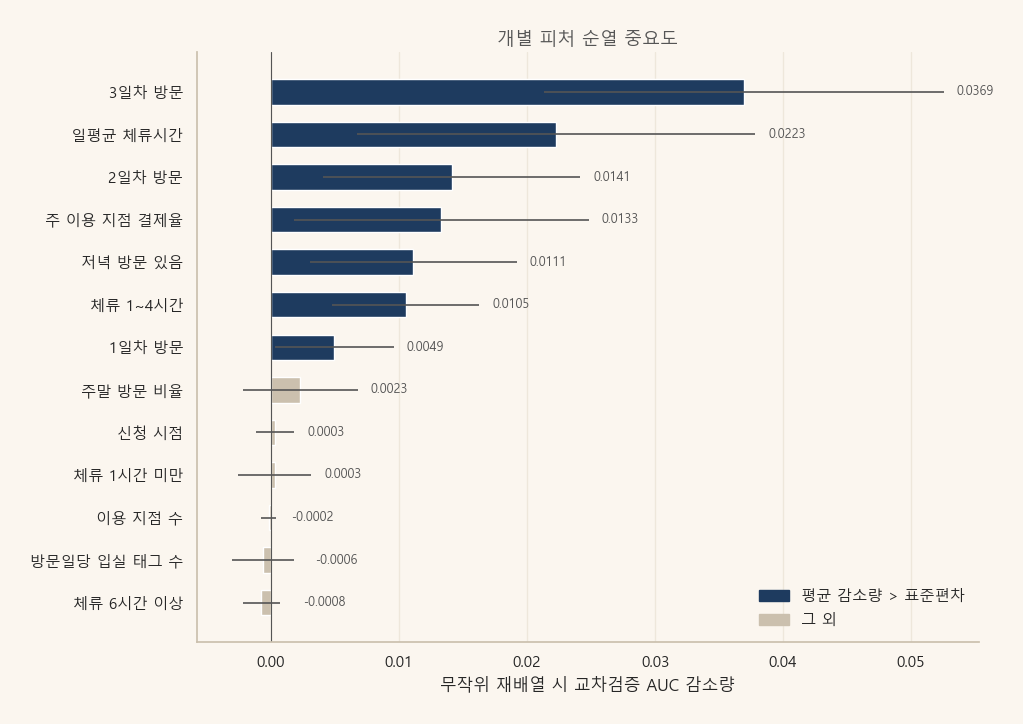

In [53]:
# 그래프 : 개별 피처 13개 중요도 (막대 = 평균, 가로선 = 표준편차)
plot = single_imp.iloc[::-1]
colors = [NAVY if m - s > 0 else BEIGE for m, s in zip(plot['AUC 감소 평균'], plot['AUC 감소 표준편차'])]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot.index, plot['AUC 감소 평균'], xerr=plot['AUC 감소 표준편차'],
        color=colors, height=0.6, error_kw={'ecolor': DARK, 'linewidth': 1.2})
for i, (v, sd) in enumerate(zip(plot['AUC 감소 평균'], plot['AUC 감소 표준편차'])):
    ax.text(max(v, 0) + sd + 0.001, i, f'{v:.4f}', va='center', fontsize=9, color=DARK)
ax.axvline(0, color=DARK, linewidth=0.8)
ax.set_xlabel('무작위 재배열 시 교차검증 AUC 감소량')
ax.legend(handles=[Patch(color=NAVY, label='평균 감소량 > 표준편차'), Patch(color=BEIGE, label='그 외')],
          frameon=False, loc='lower right')
ax.set_title('개별 피처 순열 중요도', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0)
plt.tight_layout()
plt.show()

- 묶음으로 보면 체류시간(AUC 0.041 감소)과 방문 일차(0.037)가 다른 피처보다 두세 배 이상 크다. 교차검증 AUC가 0.604이므로, 둘 중 하나만 무작위로 재배열해도 0.56대로 떨어진다. 50번 중 감소가 0 이하였던 경우도 각각 0회, 2회뿐이다.
- 그다음은 주 이용 지점 결제율(0.014)과 저녁 방문 있음(0.013)이다. 50번 중 4\~5번은 감소가 0 이하로 나와, 두 주요 피처군보다 중요도가 불확실하다.
- 주말 방문 비율의 중요도(0.002)는 작고, 50번의 무작위 재배열 중 30%에서는 AUC가 감소하지 않았다. 신청 시점, 이용 지점 수, 방문일당 입실 태그 수의 중요도는 0에 가까워, 예측 성능에 대한 추가 기여가 거의 없다.
- 체류시간은 개별로 보면 일평균 체류시간(0.022)만 두드러지고, 구간 더미는 1\~4시간(0.011)을 빼면 0에 가깝다. 네 피처를 함께 무작위로 재배열하면 0.041로 가장 커진다. 서로 겹치는 피처는 하나만 재배열하면 나머지에 같은 정보가 남아 있어 중요도가 작게 측정되므로, 체류시간은 묶음 값으로 판단한다.
- 방문 일차에서는 `day3` 하나의 중요도(0.037)가 방문 일차 묶음 전체의 중요도(0.037)와 거의 같다. 방문 일차의 정보는 대부분 3일차 방문 여부에 담겨 있다.
- 표준화 계수의 크기와 순열 중요도의 순위는 대체로 비슷하지만, 일부 피처에서는 차이가 난다. 체류 1시간 미만(−0.038)과 방문일당 입실 태그 수(−0.028)는 계수가 0이 아니지만 무작위로 재배열해도 AUC가 거의 변하지 않는다. 계수가 있다고 해서 예측 성능에 기여한다고 볼 수는 없다.

## 4.8 피처 정리 후 재학습

4.7에서 예측 성능에 거의 기여하지 않은 피처를 빼고, 4.5\~4.6과 같은 순서로 교차검증과 평가 데이터 확인을 다시 한다.

- 4.8.1 13개와 10개 피처 비교 (로지스틱 회귀)
- 4.8.2 최종 피처로 네 모델 교차검증
- 4.8.3 평가 데이터로 최종 확인 (로지스틱 회귀, 10개 피처)

### 4.8.1 13개와 10개 피처 비교 (로지스틱 회귀)

로지스틱 회귀에서 세 피처를 빼고 다시 학습해, 성능이 유지되는지 확인한다.

| 제외 피처 | 4.7 AUC 감소 평균 | 감소가 0 이하인 비율 | 제외 이유 |
|---|---|---|---|
| `month_idx` (신청 시점) | 0.0003 | 36% | 기여가 0에 가깝다 |
| `n_sites` (이용 지점 수) | −0.0002 | 66% | 기여가 0에 가깝다. 대부분(96%)이 한 지점만 이용해 값의 차이가 거의 없다 |
| `tags_per_day` (방문일당 입실 태그 수) | −0.0006 | 44% | 기여가 0에 가깝다. `avg_stay_h`와 상관(0.59)이 있어 정보가 겹친다 |

- EDA(3.1)에서 본 결제율 차이는 변수를 하나씩 따로 본 결과다. 모델에서는 방문 일차와 체류시간이 같은 정보를 이미 담고 있어 추가로 더해지는 것이 없었다.
- `day1`(1일차 방문)은 남긴다. 개별 중요도(0.0049)가 표준편차(0.0047)보다 커 기여가 있고, `day1`\~`day3`를 모두 두어야 4.3처럼 `visit_days`, `lead_day`를 계산할 수 있다는 특성이 유지된다.
- 체류 1시간 미만, 체류 6시간 이상도 개별 중요도는 0에 가깝지만, 체류시간 네 피처는 묶어서 판단하기로 했으므로(4.7) 남긴다.
- 로지스틱 회귀의 C는 4.6과 같은 0.1로 고정한다. 두 모델의 차이가 피처 구성에서만 발생하도록 하기 위해서다. 참고로 축소한 피처 세트로 C 후보 네 개를 다시 비교하면 AUC 차이가 0.0002 이하로, C에 따른 차이는 거의 없다.
- 판정 기준: 평가 데이터를 보기 전에 교차검증으로 정한다. 교차검증 AUC 차이가 폴드별 표준편차보다 작으면 축소한 피처 세트를 최종 모델에 사용한다. 평가 데이터는 결과 확인에만 쓴다.

In [54]:
DROP = ['tags_per_day', 'n_sites', 'month_idx']
FEATURES_REDUCED = [f for f in FEATURES_FINAL if f not in DROP]

print('제외 :', ', '.join(FEATURE_NAMES[f] for f in DROP))
print('피처 수 :', len(FEATURES_FINAL), '→', len(FEATURES_REDUCED))
print('남은 피처 :', FEATURES_REDUCED)

# 참고 : 줄인 피처로 4.5와 같은 C 후보를 다시 비교한다
lr_base, lr_grid = models['로지스틱 회귀']
rows = []
for params in ParameterGrid(lr_grid):
    scores = cv_scores(clone(lr_base).set_params(**params), FEATURES_REDUCED)
    rows.append({
        'C': params['logisticregression__C'],
        'AUC 평균': scores['AUC'].mean(),
        'AUC 표준편차': scores['AUC'].std(),
        '상위 20% 정밀도': scores['상위 20% 정밀도'].mean(),
        '상위 30% 정밀도': scores['상위 30% 정밀도'].mean(),
    })
reduced_grid = pd.DataFrame(rows).set_index('C')
display(reduced_grid.style.format({
    'AUC 평균': '{:.4f}', 'AUC 표준편차': '{:.3f}',
    '상위 20% 정밀도': '{:.1%}', '상위 30% 정밀도': '{:.1%}',
}))
print(f"C 후보 간 AUC 차이 : 최대 {reduced_grid['AUC 평균'].max() - reduced_grid['AUC 평균'].min():.4f}")

# C는 4.6과 같은 값으로 고정해, 두 모델의 차이가 피처 구성에서만 나오게 한다
best_params_reduced = best_params['로지스틱 회귀']
print('사용할 하이퍼파라미터 :', best_params_reduced)

제외 : 방문일당 입실 태그 수, 이용 지점 수, 신청 시점
피처 수 : 13 → 10
남은 피처 : ['day1', 'day2', 'day3', 'avg_stay_h', 'stay_lt1', 'stay_1_4', 'stay_6p', 'any_evening', 'weekend_ratio', 'site_rate']


,AUC 평균,AUC 표준편차,상위 20% 정밀도,상위 30% 정밀도
C,,,,
0.010000,0.6059,0.018,56.4%,54.2%
0.100000,0.6060,0.017,56.6%,54.3%
1.000000,0.6061,0.017,56.7%,54.1%
10.000000,0.6061,0.017,56.6%,54.1%


C 후보 간 AUC 차이 : 최대 0.0002
사용할 하이퍼파라미터 : {'logisticregression__C': 0.1}


In [55]:
# 13개와 10개를 같은 5개 폴드에서 비교한다 (skf의 random_state가 같아 폴드 구성이 같다)
full_cv = cv_scores(clone(lr_base).set_params(**best_params['로지스틱 회귀']))
reduced_cv = cv_scores(clone(lr_base).set_params(**best_params_reduced), FEATURES_REDUCED)

cv_compare = pd.DataFrame({
    f'13개 (4.5)': full_cv.mean(),
    f'10개': reduced_cv.mean(),
})
cv_compare['차이 (10개 − 13개)'] = cv_compare['10개'] - cv_compare['13개 (4.5)']
cv_compare.index.name = '교차검증 평균'
display(cv_compare.style.format('{:+.3f}', subset=['차이 (10개 − 13개)'])
        .format('{:.3f}', subset=['13개 (4.5)', '10개']))

# 폴드별 AUC
fold_auc = pd.DataFrame({
    '13개': full_cv['AUC'],
    '10개': reduced_cv['AUC'],
})
fold_auc['차이'] = fold_auc['10개'] - fold_auc['13개']
fold_auc.index = [f'폴드 {i + 1}' for i in range(len(fold_auc))]
display(fold_auc.style.format('{:.3f}').format('{:+.3f}', subset=['차이']))
print(f"AUC 차이 평균 {fold_auc['차이'].mean():+.4f} / 13개 모델의 폴드별 AUC 표준편차 {full_cv['AUC'].std():.3f}")

,13개 (4.5),10개,차이 (10개 − 13개)
교차검증 평균,,,
AUC,0.604,0.606,+0.002
상위 20% 정밀도,0.567,0.566,-0.001
상위 30% 정밀도,0.537,0.543,+0.006


,13개,10개,차이
폴드 1,0.612,0.611,-0.000
폴드 2,0.623,0.626,+0.003
폴드 3,0.606,0.612,+0.006
폴드 4,0.577,0.579,+0.002
폴드 5,0.603,0.603,-0.000


AUC 차이 평균 +0.0020 / 13개 모델의 폴드별 AUC 표준편차 0.017


In [56]:
# 평가 데이터 확인 : 줄인 피처로 학습 데이터 전체에 다시 학습 (site_rate는 4.4 값)
reduced_model = clone(lr_base).set_params(**best_params_reduced)
reduced_model.fit(train_df[FEATURES_REDUCED], y_train)
reduced_prob = reduced_model.predict_proba(test_df[FEATURES_REDUCED])[:, 1]


def test_summary(prob):
    row = {'평가 AUC': roc_auc_score(y_test, prob)}
    for k in (0.2, 0.3):
        pred = top_k_pred(prob, k)
        row[f'상위 {k:.0%} 정밀도'] = precision_score(y_test, pred)
        row[f'상위 {k:.0%} 재현율'] = recall_score(y_test, pred)
    return row


test_compare = pd.DataFrame({
    '13개 (4.6)': test_summary(test_prob),
    '10개': test_summary(reduced_prob),
}).T
test_compare.index.name = '평가 데이터 (2023년)'
display(test_compare.style.format({
    '평가 AUC': '{:.3f}',
    '상위 20% 정밀도': '{:.1%}', '상위 20% 재현율': '{:.1%}',
    '상위 30% 정밀도': '{:.1%}', '상위 30% 재현율': '{:.1%}',
}))

# AUC 차이의 95% 신뢰구간 (같은 부트스트랩 표본으로 두 모델을 함께 계산, 2,000회)
rng = np.random.default_rng(RANDOM_STATE)
auc_diff = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    y_boot = y_test.values[idx]
    if y_boot.min() == y_boot.max():
        continue
    auc_diff.append(roc_auc_score(y_boot, reduced_prob[idx]) - roc_auc_score(y_boot, test_prob[idx]))

print(f"평가 AUC 차이 (10개 − 13개) : {test_compare.loc['10개', '평가 AUC'] - test_compare.loc['13개 (4.6)', '평가 AUC']:+.4f}, "
      f"95% 신뢰구간 {np.percentile(auc_diff, 2.5):+.4f} ~ {np.percentile(auc_diff, 97.5):+.4f}")

,평가 AUC,상위 20% 정밀도,상위 20% 재현율,상위 30% 정밀도,상위 30% 재현율
평가 데이터 (2023년),,,,,
13개 (4.6),0.620,48.6%,28.9%,45.1%,40.2%
10개,0.623,48.6%,28.9%,45.4%,40.5%


평가 AUC 차이 (10개 − 13개) : +0.0033, 95% 신뢰구간 +0.0017 ~ +0.0050


In [57]:
# 표준화 계수 비교 (4.6 최종 모델 vs 줄인 모델)
coef_compare = pd.DataFrame({
    '13개 (4.6)': pd.Series(final_model.named_steps['logisticregression'].coef_[0], index=FEATURES_FINAL),
    '10개': pd.Series(reduced_model.named_steps['logisticregression'].coef_[0], index=FEATURES_REDUCED),
}).reindex(FEATURES_FINAL)
coef_compare.index = [FEATURE_NAMES[f] for f in coef_compare.index]
coef_compare.index.name = '피처 (표준화 계수)'
display(coef_compare.style.format('{:+.3f}', na_rep='제외'))

,13개 (4.6),10개
피처 (표준화 계수),,
1일차 방문,+0.082,+0.077
2일차 방문,+0.159,+0.158
3일차 방문,+0.252,+0.251
일평균 체류시간,-0.183,-0.197
체류 1시간 미만,-0.038,-0.037
체류 1~4시간,+0.120,+0.120
체류 6시간 이상,+0.008,+0.008
방문일당 입실 태그 수,-0.028,제외
저녁 방문 있음,+0.129,+0.129


- 교차검증 AUC는 13개 피처 모델이 0.604, 10개 피처 모델이 0.606으로 차이가 +0.002다. 폴드별 표준편차(0.017)보다 훨씬 작아 판정 기준을 충족한다. 폴드 5개 모두 차이가 −0.001\~+0.006 사이다.
- 교차검증 상위 20% 정밀도는 56.7%와 56.6%로 같고, 상위 30% 정밀도는 53.7%에서 54.3%로 0.6%p 높다.
- 평가 데이터에서도 성능이 유지된다. AUC는 0.620에서 0.623, 상위 20% 정밀도는 48.6%로 같고, 상위 30% 정밀도는 45.1%에서 45.4%다.
- 평가 AUC 차이의 95% 신뢰구간(+0.0017\~+0.0050)은 0을 포함하지 않는다. 다만 이 구간은 같은 평가 데이터를 다시 뽑아 계산한 것이라 학습 데이터에 따른 변동은 담지 않고, 차이 자체도 0.003으로 작다. 따라서 성능이 좋아졌다기보다 세 피처를 빼도 성능이 떨어지지 않는다고 본다.
- 남은 피처의 계수 방향은 두 모델에서 모두 같다. 일평균 체류시간(−0.183 → −0.197)과 주 이용 지점 결제율(+0.165 → +0.154)이 0.01 남짓 달라졌고, 나머지는 차이가 0.005 이하다.
- 결론: 세 피처는 예측 성능에 기여하지 않으므로 뺀다. 이후 해석은 10개 피처 모델(`reduced_model`)로 한다.

### 4.8.2 최종 피처로 네 모델 교차검증

4.5에서는 13개 피처로 네 모델을 비교했다. 피처를 10개로 줄인 뒤에도 네 모델의 성능이 비슷한지, 로지스틱 회귀를 고른 판단이 그대로 유효한지 확인한다.

- 4.5와 같은 층화 5겹 폴드와 하이퍼파라미터 후보를 쓴다. `site_rate`도 4.5처럼 반복마다 학습 폴드로 다시 계산한다.
- 트리 모델 세 개는 10개 피처로 하이퍼파라미터를 다시 고른다.
- 로지스틱 회귀는 4.8.1에서 정한 대로 C를 0.1로 고정한다. C 후보별 결과는 4.8.1 표에 있다.
- 평가 데이터는 쓰지 않는다.

,하이퍼파라미터,AUC 평균,AUC 표준편차,상위 20% 정밀도,상위 30% 정밀도,13개 AUC (4.5),AUC 차이 (10개 − 13개)
교차검증 (10개 피처),,,,,,,
로지스틱 회귀,{'logisticregression__C': 0.1},0.606,0.017,56.6%,54.3%,0.604,+0.002
랜덤포레스트,"{'max_depth': 6, 'min_samples_leaf': 20}",0.602,0.019,57.0%,53.8%,0.602,+0.000
XGBoost,"{'learning_rate': 0.03, 'max_depth': 2}",0.600,0.022,55.1%,52.6%,0.601,-0.000
LightGBM,"{'learning_rate': 0.03, 'max_depth': 3, 'num_leaves': 7}",0.598,0.021,55.6%,53.2%,0.600,-0.002


네 모델의 AUC 평균 범위 : 0.598 ~ 0.606 (차이 0.008)
폴드별 AUC 표준편차 범위 : 0.017 ~ 0.022
학습 데이터 결제율(교차검증 정밀도의 무작위 기준) : 42.0%


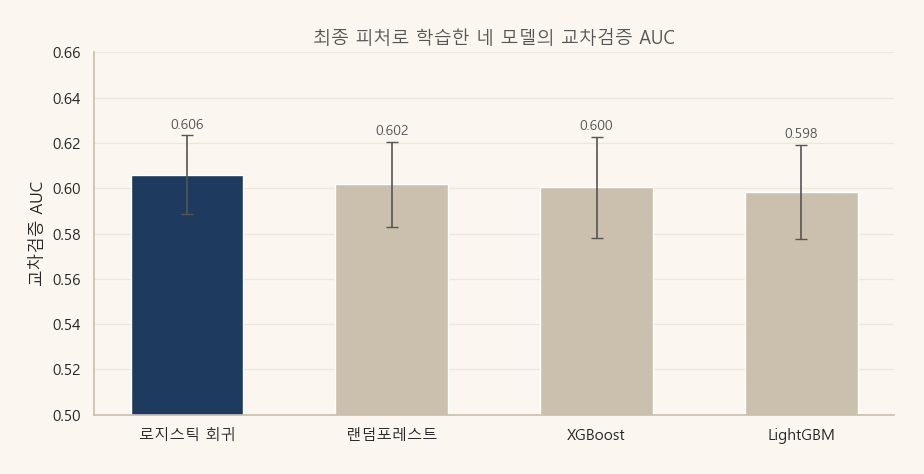

In [58]:
# 10개 피처로 네 모델을 교차검증한다 (로지스틱 회귀는 C = 0.1 고정, 나머지는 4.5와 같은 후보에서 다시 선택)
grids_reduced = {name: grid for name, (base, grid) in models.items()}
grids_reduced['로지스틱 회귀'] = {'logisticregression__C': [best_params_reduced['logisticregression__C']]}

results_reduced = []
for name, (base, _) in models.items():
    for params in ParameterGrid(grids_reduced[name]):
        scores = cv_scores(clone(base).set_params(**params), FEATURES_REDUCED)
        results_reduced.append({
            '모델': name,
            '하이퍼파라미터': params,
            'AUC 평균': scores['AUC'].mean(),
            'AUC 표준편차': scores['AUC'].std(),
            '상위 20% 정밀도': scores['상위 20% 정밀도'].mean(),
            '상위 30% 정밀도': scores['상위 30% 정밀도'].mean(),
        })

cv_results_reduced = pd.DataFrame(results_reduced)
best_reduced = (
    cv_results_reduced.sort_values('AUC 평균', ascending=False)
    .drop_duplicates('모델')
    .set_index('모델')
    .reindex(list(models))
)
best_reduced['13개 AUC (4.5)'] = best['AUC 평균']
best_reduced['AUC 차이 (10개 − 13개)'] = best_reduced['AUC 평균'] - best_reduced['13개 AUC (4.5)']
best_reduced.index.name = '교차검증 (10개 피처)'

display(best_reduced.style.format({
    'AUC 평균': '{:.3f}', 'AUC 표준편차': '{:.3f}',
    '상위 20% 정밀도': '{:.1%}', '상위 30% 정밀도': '{:.1%}',
    '13개 AUC (4.5)': '{:.3f}', 'AUC 차이 (10개 − 13개)': '{:+.3f}',
}))
print(f"네 모델의 AUC 평균 범위 : {best_reduced['AUC 평균'].min():.3f} ~ {best_reduced['AUC 평균'].max():.3f} "
      f"(차이 {best_reduced['AUC 평균'].max() - best_reduced['AUC 평균'].min():.3f})")
print(f"폴드별 AUC 표준편차 범위 : {best_reduced['AUC 표준편차'].min():.3f} ~ {best_reduced['AUC 표준편차'].max():.3f}")
print(f"학습 데이터 결제율(교차검증 정밀도의 무작위 기준) : {train_rate:.1%}")

# 그래프 : 모델별 교차검증 AUC (막대 = 평균, 세로선 = 폴드별 표준편차)
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_colors = [NAVY if m == '로지스틱 회귀' else BEIGE for m in best_reduced.index]
ax.bar(best_reduced.index, best_reduced['AUC 평균'], yerr=best_reduced['AUC 표준편차'],
       color=bar_colors, width=0.55, error_kw={'ecolor': DARK, 'linewidth': 1.2, 'capsize': 4})
for i, (v, sd) in enumerate(zip(best_reduced['AUC 평균'], best_reduced['AUC 표준편차'])):
    ax.text(i, v + sd + 0.003, f'{v:.3f}', ha='center', fontsize=10, color=DARK)
ax.set_ylim(0.5, 0.66)
ax.set_ylabel('교차검증 AUC')
ax.set_title('최종 피처로 학습한 네 모델의 교차검증 AUC', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0)
plt.tight_layout()
plt.show()

- 10개 피처로 학습한 네 모델의 교차검증 AUC 평균은 0.598\~0.606이다. 모델 간 차이(0.008)가 폴드별 표준편차(0.017\~0.022)보다 작아, 4.5와 마찬가지로 이 점수만으로 어느 모델이 낫다고 보기 어렵다.
- 4.5의 13개 피처 결과와 비교하면 모델별 AUC 차이는 −0.002\~+0.002다. 세 피처를 빼도 로지스틱 회귀뿐 아니라 트리 모델 세 개의 성능도 유지된다. 트리 모델이 고른 하이퍼파라미터도 4.5와 같다.
- 상위 20%를 결제 예상군으로 선정하면 정밀도는 55.1\~57.0%, 상위 30%면 52.6\~54.3%다. 교차검증 무작위 기준(42.0%)보다 10%p 이상 높다.
- 로지스틱 회귀는 AUC(0.606)와 상위 30% 정밀도(54.3%)가 네 모델 중 가장 높고, 상위 20% 정밀도(56.6%)는 랜덤포레스트(57.0%)와 0.4%p 차이다. 피처를 줄인 뒤에도 로지스틱 회귀를 최종 모델로 쓰는 판단을 바꿀 근거는 없다.

### 4.8.3 평가 데이터로 최종 확인 (로지스틱 회귀, 10개 피처)

최종 모델은 10개 피처 로지스틱 회귀(C = 0.1)다. 4.6과 같은 형식으로 평가 데이터 성능을 정리한다.

- 모델은 4.8.1에서 학습 데이터 전체로 다시 학습한 `reduced_model`을 그대로 쓴다. `site_rate`는 4.4에서 학습 데이터 전체로 계산한 값이다.
- 이 모델의 평가 AUC와 상위 20%·30% 정밀도는 4.8.1에서 13개 모델과 비교할 때 이미 한 번 계산했다. 여기서는 같은 예측값으로 재현율·F1, 신뢰구간, 선정 비율별 정밀도를 추가로 정리하고, 모델이나 하이퍼파라미터는 바꾸지 않는다.
- 평가 기간과 학습 기간은 결제율 수준이 다르므로(33.6%, 42.0%), 교차검증과 평가 데이터는 무작위 대비 배율로도 비교한다.

In [59]:
# 최종 모델(10개 피처 로지스틱 회귀)의 평가 데이터 성능
final_auc = roc_auc_score(y_test, reduced_prob)
test_rate = y_test.mean()   # 무작위로 골랐을 때의 정밀도

final_rows = []
for label, pred in [
    ('상위 20%', top_k_pred(reduced_prob, 0.2)),
    ('상위 30%', top_k_pred(reduced_prob, 0.3)),
    ('확률 0.5 기준 (참고)', (reduced_prob >= 0.5).astype(int)),
]:
    final_rows.append({
        '선정 방식': label,
        '결제 예상군 비율': pred.mean(),
        '정밀도': precision_score(y_test, pred),
        '재현율': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        '무작위 대비': precision_score(y_test, pred) / test_rate,
    })
final_compare = pd.DataFrame(final_rows).set_index('선정 방식')
final_compare.index.name = '평가 데이터 (2023년)'

print('하이퍼파라미터 :', best_params_reduced)
print(f'평가 AUC {final_auc:.3f} / 무작위 기준 정밀도 {test_rate:.1%}')
display(final_compare.style.format({
    '결제 예상군 비율': '{:.1%}', '정밀도': '{:.1%}', '재현율': '{:.1%}', 'F1': '{:.3f}', '무작위 대비': '{:.2f}배',
}))

# 평가 지표의 95% 신뢰구간 (부트스트랩 2,000회)
boot_rng = np.random.default_rng(RANDOM_STATE)
boot = {'AUC': [], 'p20': [], 'p30': []}
for _ in range(2000):
    idx = boot_rng.integers(0, len(y_test), len(y_test))
    y_boot = y_test.values[idx]
    if y_boot.min() == y_boot.max():
        continue
    boot['AUC'].append(roc_auc_score(y_boot, reduced_prob[idx]))
    boot['p20'].append(precision_at_k(y_boot, reduced_prob[idx], 0.2))
    boot['p30'].append(precision_at_k(y_boot, reduced_prob[idx], 0.3))

final_ci = pd.DataFrame({
    '값': [final_auc, precision_at_k(y_test, reduced_prob, 0.2), precision_at_k(y_test, reduced_prob, 0.3)],
    '95% 하한': [np.percentile(boot[k], 2.5) for k in boot],
    '95% 상한': [np.percentile(boot[k], 97.5) for k in boot],
}, index=['평가 AUC', '평가 상위 20% 정밀도', '평가 상위 30% 정밀도'])
display(final_ci.style.format('{:.3f}'))

하이퍼파라미터 : {'logisticregression__C': 0.1}
평가 AUC 0.623 / 무작위 기준 정밀도 33.6%


,결제 예상군 비율,정밀도,재현율,F1,무작위 대비
평가 데이터 (2023년),,,,,
상위 20%,20.0%,48.6%,28.9%,0.363,1.45배
상위 30%,30.0%,45.4%,40.5%,0.428,1.35배
확률 0.5 기준 (참고),19.7%,49.1%,28.8%,0.363,1.46배


,값,95% 하한,95% 상한
평가 AUC,0.623,0.598,0.647
평가 상위 20% 정밀도,0.486,0.440,0.535
평가 상위 30% 정밀도,0.454,0.414,0.492


,교차검증 (2021~2022년),평가 데이터 (2023년)
최종 모델 (10개 피처 로지스틱 회귀),,
AUC,0.606,0.623
무작위 기준 정밀도 (결제율),42.0%,33.6%
상위 20% 정밀도,56.6%,48.6%
상위 20% 무작위 대비,1.35배,1.45배
상위 30% 정밀도,54.3%,45.4%
상위 30% 무작위 대비,1.29배,1.35배


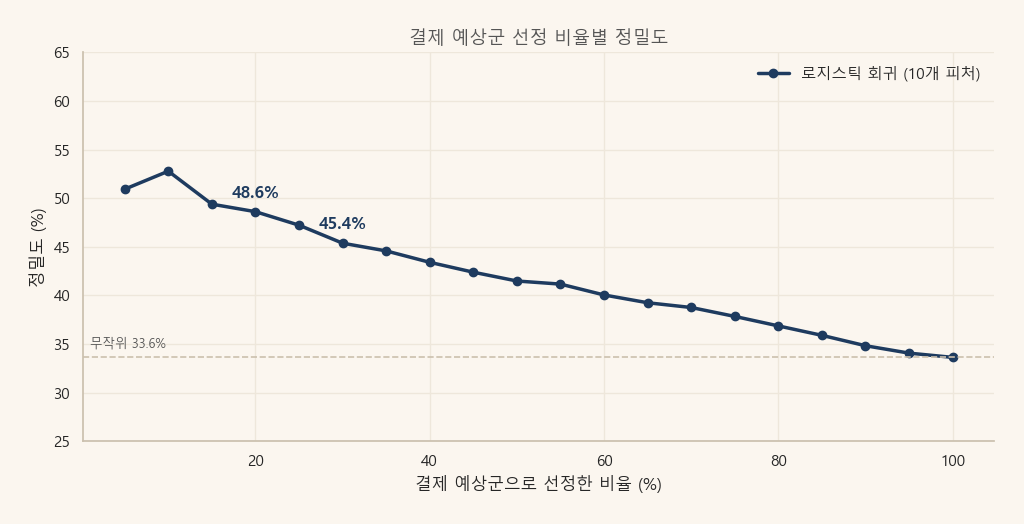

In [60]:
# 최종 모델 요약 : 교차검증(학습 데이터)과 평가 데이터
cv_lr = best_reduced.loc['로지스틱 회귀']
final_summary = pd.DataFrame({
    '교차검증 (2021~2022년)': {
        'AUC': cv_lr['AUC 평균'],
        '무작위 기준 정밀도 (결제율)': train_rate,
        '상위 20% 정밀도': cv_lr['상위 20% 정밀도'],
        '상위 20% 무작위 대비': cv_lr['상위 20% 정밀도'] / train_rate,
        '상위 30% 정밀도': cv_lr['상위 30% 정밀도'],
        '상위 30% 무작위 대비': cv_lr['상위 30% 정밀도'] / train_rate,
    },
    '평가 데이터 (2023년)': {
        'AUC': final_auc,
        '무작위 기준 정밀도 (결제율)': test_rate,
        '상위 20% 정밀도': precision_at_k(y_test, reduced_prob, 0.2),
        '상위 20% 무작위 대비': precision_at_k(y_test, reduced_prob, 0.2) / test_rate,
        '상위 30% 정밀도': precision_at_k(y_test, reduced_prob, 0.3),
        '상위 30% 무작위 대비': precision_at_k(y_test, reduced_prob, 0.3) / test_rate,
    },
})
final_summary.index.name = '최종 모델 (10개 피처 로지스틱 회귀)'

# 행마다 형식이 달라 문자열로 바꿔 표시한다
row_fmt = {k: '{:.2f}배' if '대비' in k else '{:.1%}' if '정밀도' in k else '{:.3f}' for k in final_summary.index}
display(final_summary.apply(lambda col: [row_fmt[k].format(v) for k, v in col.items()]))

# 그래프 : 결제 예상군 선정 비율별 정밀도 (평가 데이터, 최종 모델)
ks = np.arange(0.05, 1.0001, 0.05)
prec_final = [precision_at_k(y_test, reduced_prob, k) for k in ks]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ks * 100, np.array(prec_final) * 100, color=NAVY, marker='o', linewidth=2.5, label='로지스틱 회귀 (10개 피처)')
ax.axhline(test_rate * 100, color=BEIGE, linestyle='--', linewidth=1.2)
ax.text(1, test_rate * 100 + 1, f'무작위 {test_rate:.1%}', ha='left', fontsize=9, color=DARK)
for k in (0.2, 0.3):
    p = precision_at_k(y_test, reduced_prob, k)
    ax.annotate(f'{p:.1%}', (k * 100, p * 100), textcoords='offset points',
                xytext=(0, 10), ha='center', color=NAVY, fontweight='bold')
ax.set_xlabel('결제 예상군으로 선정한 비율 (%)')
ax.set_ylabel('정밀도 (%)')
ax.set_ylim(25, 65)
ax.set_title('결제 예상군 선정 비율별 정밀도', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
plt.show()

- 평가 AUC는 0.623으로 교차검증(0.606)과 비슷하다. 부트스트랩 95% 신뢰구간(0.598\~0.647)에 교차검증 AUC가 포함되므로 평가 데이터에서 성능이 좋아졌다고 해석하지 않는다. 학습 기간과 평가 기간이 달라도 성능이 떨어지지 않았다는 점을 확인한 결과다.
- 상위 20%를 결제 예상군으로 선정하면 정밀도는 48.6%(95% 신뢰구간 44.0\~53.5%)로 무작위(33.6%)보다 15.0%p 높은 1.45배다. 상위 30%면 45.4%(41.4\~49.2%)로 1.35배다. 두 신뢰구간 모두 하한이 무작위 기준보다 높다.
- 평가 정밀도가 교차검증(56.6%, 54.3%)보다 낮은 것은 평가 기간의 결제율 자체가 낮기 때문이다. 무작위 대비 배율은 교차검증 1.35배·1.29배, 평가 1.45배·1.35배로 평가 데이터가 낮지 않다.
- 재현율은 상위 20%가 28.9%, 상위 30%가 40.5%다. 상위 30%를 선정하면 2023년 결제자의 약 40%가 결제 예상군에 들어간다.
- 확률 0.5 기준은 결제 예상군 비율(19.7%)과 정밀도(49.1%)가 상위 20%와 비슷하게 나왔다. 다만 모델 확률은 결제율이 높던 학습 기간에 맞춰져 있어(4.6), 기간에 따라 결과가 달라질 수 있다. 따라서 4.6과 같이 상위 K% 방식으로 판단한다.
- 최종 모델은 10개 피처 로지스틱 회귀(C = 0.1)이고, 평가 데이터 성능은 AUC 0.623, 상위 20% 정밀도 48.6%(무작위 대비 1.45배), 상위 30% 정밀도 45.4%(1.35배)다. 4.9 이후의 해석과 고객군 나누기는 이 모델을 쓴다.

## 4.9 실제 결제율과 대조

4.8에서 정한 10개 피처 로지스틱 회귀가 실제 결제자를 상위에 배치했는지 실제 결제율로 확인한다. 방문자를 모델의 결제 확률이 높은 순서로 정렬하고, 순위 구간마다 실제로 결제한 비율을 계산한다.

확률값 자체는 사용하지 않는다. 평가 데이터에서 모델 확률의 평균은 40.6%인데 실제 결제율은 33.6%다. 결제율이 높던 학습 기간으로 학습했기 때문이다. 예측 확률의 절댓값이 실제 결제율과 다르더라도 순서가 정확하면 결제 가능성이 높은 사람을 식별할 수 있다.

- 4.9.1 순위 구간별 실제 결제율
- 4.9.2 모델 고객군 나누기

### 4.9.1 순위 구간별 실제 결제율

순위를 10% 단위로 나눠 구간마다 실제 결제율을 계산한다. 순서가 맞다면 상위 구간일수록 결제율이 높다. 학습 기간(42.0%)과 평가 기간(33.6%)은 결제율 수준이 다르므로, 교차검증과 평가 데이터는 무작위 대비 배율로 비교한다. 그래프는 평가 데이터의 구간별 결제율이고, 교차검증 결과는 표에만 적는다. 가로축의 0\~10% 구간이 결제 확률이 가장 높은 구간이다.

무작위 기준 : 교차검증 42.0% / 평가 33.6%
평가 데이터의 모델 확률 평균 : 40.6%


,교차검증 결제율,교차검증 무작위 대비,평가 인원,평가 결제자,평가 결제율,평가 무작위 대비
구간,,,,,,
0~10%,58.4%,1.39배,216,114,52.8%,1.57배
10~20%,54.8%,1.31배,216,96,44.4%,1.32배
20~30%,49.9%,1.19배,216,84,38.9%,1.16배
30~40%,43.3%,1.03배,216,81,37.5%,1.12배
40~50%,45.5%,1.08배,216,73,33.8%,1.01배
50~60%,33.2%,0.79배,216,71,32.9%,0.98배
60~70%,33.6%,0.80배,216,67,31.0%,0.92배
70~80%,37.8%,0.90배,216,51,23.6%,0.70배
80~90%,32.1%,0.76배,216,40,18.5%,0.55배


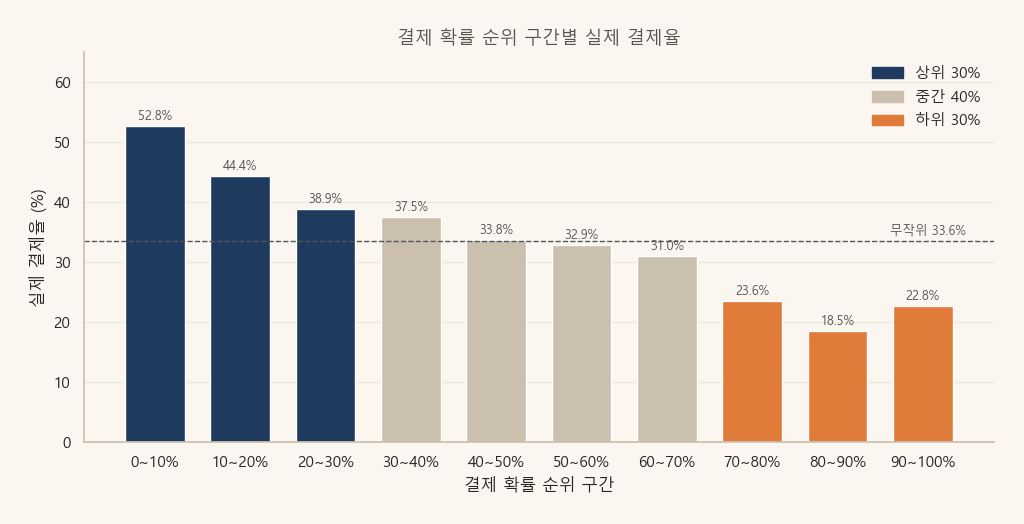

In [61]:
# 결제 확률 순위를 10% 단위로 나눠 구간마다 실제 결제율을 계산한다 (4.8의 10개 피처 모델)
def band_table(y_true, prob, n_bands=10):
    """점수 상위부터 10% 구간마다 인원, 결제자, 실제 결제율을 계산"""
    y_sorted = np.asarray(y_true)[np.argsort(-np.asarray(prob))]
    n = len(y_sorted)
    edges = [int(np.ceil(n * i / n_bands)) for i in range(n_bands + 1)]
    rows = []
    for i in range(n_bands):
        band = y_sorted[edges[i]:edges[i + 1]]
        rows.append({
            '구간': f'{i * 10}~{(i + 1) * 10}%',
            '인원': len(band),
            '결제자': int(band.sum()),
            '실제 결제율': band.mean(),
        })
    return pd.DataFrame(rows).set_index('구간')


# 교차검증 : 검증 폴드마다 구간별 결제율을 구해 평균한다 (4.5와 같은 폴드, 폴드마다 site_rate 재계산)
cv_bands = []
for tr_idx, va_idx in skf.split(train_df, train_df[TARGET]):
    tr = train_df.iloc[tr_idx].copy()
    va = train_df.iloc[va_idx].copy()
    tr['site_rate'] = add_site_rate(tr, tr)
    va['site_rate'] = add_site_rate(tr, va)
    fitted = clone(reduced_model).fit(tr[FEATURES_REDUCED], tr[TARGET])
    cv_bands.append(band_table(va[TARGET], fitted.predict_proba(va[FEATURES_REDUCED])[:, 1]))
cv_band = pd.concat(cv_bands).groupby(level=0, sort=False)['실제 결제율'].mean()

# 평가 데이터
test_band = band_table(y_test, reduced_prob)
test_rate = y_test.mean()
train_rate = y_train.mean()

band_view = pd.DataFrame({
    '교차검증 결제율': cv_band,
    '교차검증 무작위 대비': cv_band / train_rate,
    '평가 인원': test_band['인원'],
    '평가 결제자': test_band['결제자'],
    '평가 결제율': test_band['실제 결제율'],
    '평가 무작위 대비': test_band['실제 결제율'] / test_rate,
})
print(f'무작위 기준 : 교차검증 {train_rate:.1%} / 평가 {test_rate:.1%}')
print(f'평가 데이터의 모델 확률 평균 : {reduced_prob.mean():.1%}')
display(band_view.style.format({
    '교차검증 결제율': '{:.1%}', '교차검증 무작위 대비': '{:.2f}배',
    '평가 결제율': '{:.1%}', '평가 무작위 대비': '{:.2f}배',
}))

# 그래프 : 평가 데이터 구간별 실제 결제율 (색은 4.9.2의 세 고객군)
from matplotlib.patches import Patch

colors = [NAVY] * 3 + [BEIGE] * 4 + [ORANGE] * 3
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(test_band.index, test_band['실제 결제율'] * 100, color=colors, width=0.7)
for i, v in enumerate(test_band['실제 결제율']):
    ax.text(i, v * 100 + 1, f'{v:.1%}', ha='center', fontsize=9, color=DARK)
ax.axhline(test_rate * 100, color=DARK, linestyle='--', linewidth=1)
ax.text(len(test_band) - 0.5, test_rate * 100 + 1, f'무작위 {test_rate:.1%}', ha='right', fontsize=9, color=DARK)
ax.legend(handles=[Patch(color=NAVY, label='상위 30%'), Patch(color=BEIGE, label='중간 40%'), Patch(color=ORANGE, label='하위 30%')],
          frameon=False, loc='upper right')
ax.set_xlabel('결제 확률 순위 구간')
ax.set_ylabel('실제 결제율 (%)')
ax.set_ylim(0, 65)
ax.set_title('결제 확률 순위 구간별 실제 결제율', fontsize=13, color=DARK)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0)
plt.tight_layout()
plt.show()

- 평가 데이터에서는 상위 구간일수록 실제 결제율이 높다. 최상위 10% 구간은 52.8%로 무작위(33.6%)의 1.57배이고, 60\~70% 구간(31.0%)까지 구간마다 결제율이 낮아진다.
- 최하위 세 구간(70\~100%)은 18.5\~23.6%로 무작위의 0.55\~0.70배다. 다만 세 구간 내에서는 순서가 일관되지 않는다(23.6% → 18.5% → 22.8%).
- 교차검증에서도 상위 세 구간(49.9\~58.4%)이 무작위(42.0%)의 1.19\~1.39배로 가장 높다. 하위 구간은 평가 데이터보다 구간별 차이가 덜 뚜렷하다. 70\~80% 구간(37.8%)이 50\~70% 구간(33.2\~33.6%)보다 높고, 30\~40% 구간(43.3%)보다 40\~50% 구간(45.5%)의 결제율이 높아 순서가 역전된다.
- 모델 점수의 순서와 실제 결제율의 순서는 대체로 일치한다. 차이는 최상위와 최하위 구간에서 가장 뚜렷하고, 평가 데이터의 중간 구간(40\~70%)은 무작위와 비슷하다(0.92\~1.01배).

### 4.9.2 모델 고객군 나누기

4.9.1의 구간별 결제율을 바탕으로, 방문자를 결제 확률 순위에 따라 세 고객군으로 나눈다(3:4:3). 5.8에서 이 고객군을 군집별로 교차 비교한다.

| 고객군 | 구분 기준 (4.9.1 평가 데이터 구간 결제율) |
|---|---|
| 상위 30% | 구간 결제율이 38.9\~52.8%로 무작위(33.6%)보다 높다 |
| 중간 40% (30\~70%) | 구간 결제율이 31.0\~37.5%로 무작위 근처에 머문다 |
| 하위 30% (70\~100%) | 70%를 넘으면 구간 결제율이 18.5\~23.6%로 크게 떨어진다 |

In [62]:
# 결제 확률 순위로 세 고객군을 나눈다 : 상위 30% / 30~70% / 70~100% (3 : 4 : 3)
SEGMENTS = [('상위 30%', 0.0, 0.3), ('중간 40% (30~70%)', 0.3, 0.7), ('하위 30% (70~100%)', 0.7, 1.0)]


def assign_segment(prob):
    """점수 순위 위치로 고객군 이름을 붙인다 (band_table과 같은 올림 기준)"""
    n = len(prob)
    pos = np.empty(n, dtype=int)
    pos[np.argsort(-np.asarray(prob))] = np.arange(n)
    seg = np.empty(n, dtype=object)
    for name, lo, hi in SEGMENTS:
        seg[(pos >= int(np.ceil(n * lo))) & (pos < int(np.ceil(n * hi)))] = name
    return seg


seg_names = [s[0] for s in SEGMENTS]

# 교차검증 : 검증 폴드마다 고객군별 결제율을 무작위 대비로 구해 평균한다
cv_seg = []
for tr_idx, va_idx in skf.split(train_df, train_df[TARGET]):
    tr = train_df.iloc[tr_idx].copy()
    va = train_df.iloc[va_idx].copy()
    tr['site_rate'] = add_site_rate(tr, tr)
    va['site_rate'] = add_site_rate(tr, va)
    fitted = clone(reduced_model).fit(tr[FEATURES_REDUCED], tr[TARGET])
    va['seg'] = assign_segment(fitted.predict_proba(va[FEATURES_REDUCED])[:, 1])
    cv_seg.append(va.groupby('seg')[TARGET].mean() / va[TARGET].mean())
cv_seg = pd.concat(cv_seg, axis=1).mean(axis=1).reindex(seg_names)

# 평가 데이터 : 고객군별 실제 결제율 (seg_df는 5.8에서 군집과 교차할 때 쓴다)
seg_df = test_df.assign(seg=assign_segment(reduced_prob))
seg_summary = seg_df.groupby('seg').agg(
    인원=(TARGET, 'size'),
    결제자=(TARGET, 'sum'),
    실제_결제율=(TARGET, 'mean'),
).reindex(seg_names)
seg_summary['무작위 대비'] = seg_summary['실제_결제율'] / test_rate
seg_summary['교차검증 무작위 대비'] = cv_seg
seg_summary['결제자 중 비중'] = seg_summary['결제자'] / seg_summary['결제자'].sum()
seg_summary = seg_summary.rename(columns={'실제_결제율': '실제 결제율'})
seg_summary.index.name = '고객군 (평가 데이터)'
display(seg_summary.style.format({
    '실제 결제율': '{:.1%}', '무작위 대비': '{:.2f}배', '교차검증 무작위 대비': '{:.2f}배', '결제자 중 비중': '{:.1%}',
}))

,인원,결제자,실제 결제율,무작위 대비,교차검증 무작위 대비,결제자 중 비중
고객군 (평가 데이터),,,,,,
상위 30%,648,294,45.4%,1.35배,1.29배,40.5%
중간 40% (30~70%),864,292,33.8%,1.01배,0.93배,40.2%
하위 30% (70~100%),647,140,21.6%,0.64배,0.80배,19.3%


- 고객군별 실제 결제율은 상위 30% 45.4%, 중간 40% 33.8%, 하위 30% 21.6%로 예측 순위와 일치한다. 무작위 대비로는 1.35배, 1.01배, 0.64배다.
- 교차검증에서도 순서가 같다(1.29배, 0.93배, 0.80배). 모델 점수에 따라 구분한 세 고객군은 실제 결제율이 서로 다른 집단이다.
- 하위 30%와 나머지의 차이는 교차검증(0.80배)이 평가 데이터(0.64배)보다 작다. 6장에서는 하위 30%를 비즈니스 액션의 대상으로 삼으므로, 이 고객군의 결제율이 운영 데이터에서도 평가 데이터와 같이 낮은 수준으로 나타나는지 다시 확인해야 한다.
- 상·중·하위 고객군을 구분하는 30%와 70% 경계는 평가 데이터의 그래프를 바탕으로 정했다. 경계의 적절성도 운영 데이터로 다시 확인한다.
- 하위 30%에도 2023년 전체 결제자의 19.3%(140명)가 포함되어 있다.

# **5. 클러스터링**

이용 행동이 비슷한 방문자끼리 묶고, 군집마다 결제율을 비교한다.
4.9.2의 고객군은 모델의 결제 확률 순위로 나눈 것이고, 이 장의 군집은 이용 방식으로 나눈 것이다.

- 대상: 4.1 모델 테이블의 방문자 전체(2021\~2023년)
- 방법: K-평균(K-Means). 피처를 표준화한 뒤 거리로 군집을 나눈다.
- 미방문 신청자는 행동 데이터가 없으므로 군집에 포함하지 않는다. 5.5에서 결제율 비교를 위한 기준 집단으로만 제시한다.

결제 여부 활용 범위

- 군집을 만드는 피처에는 결제 여부를 넣지 않는다.
- K는 실루엣 점수와 군집 크기로 정했다(5.2).
- 전체 기간을 한 번에 학습했으므로 2023년 방문자도 학습에 포함된다. 5.7과 5.8의 연도별·2023년 결과는 독립적인 검증이 아니다.
- 따라서 이 장의 결과는 탐색적·기술적으로 해석한다.

| 절 | 내용 |
|---|---|
| 5.1 | 입력 피처와 전처리 |
| 5.2 | 군집 수(K) 정하기 |
| 5.3 | 알고리즘 비교 |
| 5.4 | 군집 학습과 안정성 확인 |
| 5.5 | 군집별 특징과 결제율 |
| 5.6 | 2차원으로 본 군집 (PCA) |
| 5.7 | 연도별 군집 비중과 결제율 |
| 5.8 | 모델 고객군(4.9.2)과 비교 |

## 5.1 입력 피처와 전처리

| 피처 | 의미 | 처리 |
|---|---|---|
| `visit_days` | 1\~3일차 방문일수 | 표준화 |
| `day3` | 3일차 방문 여부 | 표준화 |
| `avg_stay_h` | 방문일당 평균 체류시간 | `log1p` 변환 후 표준화 |
| `tags_per_day` | 방문일당 입실 태그 수 | `log1p` 변환 후 표준화 |
| `any_evening` | 18시 이후 첫 입실한 날이 있는지 | 표준화 |
| `weekend_ratio` | 방문일 중 주말 비율 | 표준화 |

제외한 피처

- `day1`, `day2`, `lead_day`: `visit_days`, `day3`와 정보가 겹친다(`visit_days = day1 + day2 + day3`). 모두 넣으면 방문 일차가 거리 계산에 여러 번 반영된다.
- `stay_lt1`, `stay_1_4`, `stay_6p`: `avg_stay_h`를 구간으로 나눈 피처다.
- `n_sites`: 방문자 대부분이 한 지점만 이용해 값이 거의 같다.
- `main_site`, `site_rate`: 지점 관련 정보다. `site_rate`는 결제율로 만든 값이라 넣으면 결제 정보가 입력에 들어간다.
- `month_idx`: 이용 행동이 아니라 신청 시점이다.

K-평균은 거리로 군집을 나누므로 값의 범위가 큰 피처의 영향이 커진다. 그래서 모든 피처를 표준화한다.
체류시간과 태그 수는 오른쪽 꼬리가 길어, 표준화 전에 `log1p`로 치우침을 줄인다.
체류시간의 이상치는 2.6에서 이미 처리했다.

In [63]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

CLUSTER_FEATURES = ['visit_days', 'day3', 'avg_stay_h', 'tags_per_day', 'any_evening', 'weekend_ratio']
LOG_FEATURES = ['avg_stay_h', 'tags_per_day']
N_INIT = 50   # 초기 중심을 50번 바꿔 학습하고 군집 내 거리 합이 가장 작은 결과를 쓴다 (5.2 참고)

cl_df = model_df.copy()
X_cl = cl_df[CLUSTER_FEATURES].astype(float).copy()
X_cl[LOG_FEATURES] = np.log1p(X_cl[LOG_FEATURES])

scaler_cl = StandardScaler()
Z_cl = scaler_cl.fit_transform(X_cl)

print(f'군집 대상 방문자 : {len(cl_df):,}명')
print(f"여러 지점 이용자 비율 (n_sites ≥ 2) : {(cl_df['n_sites'] >= 2).mean():.1%}")

# log1p 변환 전후 왜도
skew_view = pd.DataFrame({
    '변환 전 왜도': cl_df[LOG_FEATURES].skew(),
    'log1p 변환 후 왜도': X_cl[LOG_FEATURES].skew(),
})
display(skew_view.style.format('{:.2f}'))

군집 대상 방문자 : 5,794명
여러 지점 이용자 비율 (n_sites ≥ 2) : 3.7%


,변환 전 왜도,log1p 변환 후 왜도
avg_stay_h,0.54,-0.54
tags_per_day,1.45,0.30


## 5.2 군집 수(K) 정하기

K를 2\~8로 바꾸면서 군집 내 거리 합과 실루엣 점수를 비교한다. 군집 크기가 한쪽으로 치우치지 않았는지도 함께 확인한다.

- 군집 내 거리 합(inertia): K가 커지면 항상 줄어든다. 감소 폭이 눈에 띄게 작아지는 지점(엘보)을 찾는다.
- 실루엣 점수: 같은 군집의 표본과는 가깝고 다른 군집의 표본과는 먼 정도를 나타낸다(−1\~1, 클수록 잘 분리됨). 계산량을 줄이기 위해 3,000명을 표본으로 추출해 계산한다.

K-평균은 초기 중심에 따라 결과가 달라질 수 있다(초기값 의존성). `n_init`은 서로 다른 초기 중심으로 K-평균을 반복 학습하고, 그중 군집 내 거리 합이 가장 작은 결과를 선택하기 위한 반복 횟수다. 10번으로는 K=5에서 `random_state`에 따라 군집 내 거리 합이 더 큰 결과가 가끔 나와서 50번으로 늘렸다.

,군집 내 거리 합,실루엣 점수,가장 작은 군집 비율
K,,,
2,"26,662",0.241,46.1%
3,"21,809",0.270,20.0%
4,"18,175",0.299,15.1%
5,"15,532",0.272,14.9%
6,"13,796",0.291,9.5%
7,"12,514",0.281,9.4%
8,"11,588",0.298,7.4%


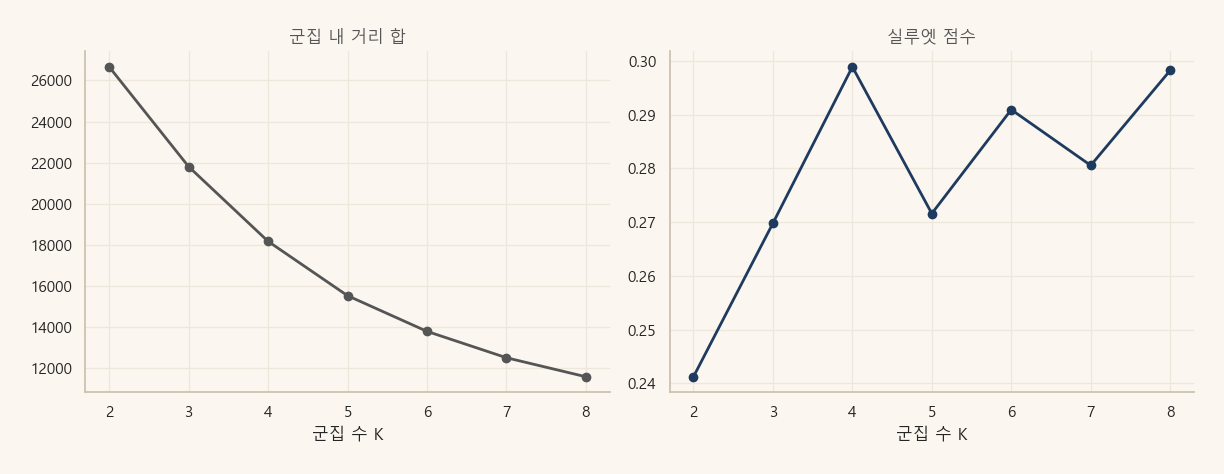

In [64]:
k_rows = []
for k in range(2, 9):
    base = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z_cl)
    k_rows.append({
        'K': k,
        '군집 내 거리 합': base.inertia_,
        '실루엣 점수': silhouette_score(Z_cl, base.labels_, sample_size=3000, random_state=RANDOM_STATE),
        '가장 작은 군집 비율': np.bincount(base.labels_).min() / len(base.labels_),
    })
k_table = pd.DataFrame(k_rows).set_index('K')
display(k_table.style.format({
    '군집 내 거리 합': '{:,.0f}', '실루엣 점수': '{:.3f}', '가장 작은 군집 비율': '{:.1%}',
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(k_table.index, k_table['군집 내 거리 합'], color=DARK, marker='o', linewidth=2)
axes[0].set_title('군집 내 거리 합', fontsize=12, color=DARK)
axes[1].plot(k_table.index, k_table['실루엣 점수'], color=NAVY, marker='o', linewidth=2)
axes[1].set_title('실루엣 점수', fontsize=12, color=DARK)
for ax in axes:
    ax.set_xlabel('군집 수 K')
    ax.set_xticks(k_table.index)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

K=4, 5, 6의 군집을 비교한다. K마다 따로 학습하므로 군집 번호는 서로 대응하지 않는다.
각 K의 군집별 행동 평균을 먼저 확인하고, 교차표로 K가 증가할 때 방문자가 어떻게 분할되는지 확인한다.

In [65]:
k_labels = {k: KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Z_cl) for k in (4, 5, 6)}


def quick_profile(k):
    """K별 군집 번호마다 인원과 주요 행동 평균"""
    prof = (
        cl_df.assign(군집=k_labels[k])
        .groupby('군집')
        .agg(인원=('visit_days', 'size'), 방문일수=('visit_days', 'mean'), 일차3_방문=('day3', 'mean'),
             체류시간=('avg_stay_h', 'mean'), 저녁_방문=('any_evening', 'mean'), 주말_비율=('weekend_ratio', 'mean'))
        .rename(columns={'일차3_방문': '3일차 방문', '체류시간': '일평균 체류시간(h)', '저녁_방문': '저녁 방문', '주말_비율': '주말 비율'})
    )
    prof.index = [f'K{k}-{i}' for i in prof.index]
    prof.index.name = f'K = {k}'
    return prof.style.format({
        '방문일수': '{:.2f}', '3일차 방문': '{:.1%}', '일평균 체류시간(h)': '{:.1f}',
        '저녁 방문': '{:.1%}', '주말 비율': '{:.2f}',
    })


def k_crosstab(k_from, k_to, normalize=False):
    """K=k_from 군집(행)의 방문자가 K=k_to의 어느 군집(열)으로 가는지"""
    ct = pd.crosstab(k_labels[k_from], k_labels[k_to], normalize='index' if normalize else False)
    ct.index = [f'K{k_from}-{i}' for i in ct.index]
    ct.columns = [f'K{k_to}-{j}' for j in ct.columns]
    ct.index.name = f'K={k_from} → K={k_to}' + (' (행 비율)' if normalize else ' (인원)')
    return ct


for k in (4, 5, 6):
    display(quick_profile(k))

for k_from, k_to in ((4, 5), (5, 6)):
    display(k_crosstab(k_from, k_to))
    display(k_crosstab(k_from, k_to, normalize=True).style.format('{:.1%}'))

,인원,방문일수,3일차 방문,일평균 체류시간(h),저녁 방문,주말 비율
K = 4,,,,,,
K4-0,877,1.27,47.2%,4.3,2.4%,0.99
K4-1,2020,1.06,12.9%,3.8,0.0%,0.00
K4-2,1756,1.99,96.7%,5.7,1.2%,0.09
K4-3,1141,1.63,60.7%,2.8,99.6%,0.19


,인원,방문일수,3일차 방문,일평균 체류시간(h),저녁 방문,주말 비율
K = 5,,,,,,
K5-0,1393,2.20,100.0%,5.7,3.4%,0.11
K5-1,1116,1.11,27.8%,2.0,0.0%,0.01
K5-2,1327,1.10,21.9%,5.9,1.1%,0.01
K5-3,1094,1.60,60.6%,2.7,100.0%,0.18
K5-4,864,1.27,47.2%,4.3,2.8%,0.99


,인원,방문일수,3일차 방문,일평균 체류시간(h),저녁 방문,주말 비율
K = 6,,,,,,
K6-0,595,2.18,93.8%,3.7,100.0%,0.24
K6-1,1324,1.10,22.0%,5.9,0.8%,0.01
K6-2,1106,1.10,27.2%,2.0,0.0%,0.01
K6-3,866,1.26,48.2%,4.3,3.0%,0.99
K6-4,548,1.08,26.1%,2.0,100.0%,0.12
K6-5,1355,2.18,100.0%,5.6,0.0%,0.11


,K5-0,K5-1,K5-2,K5-3,K5-4
K=4 → K=5 (인원),,,,,
K4-0,2,6,8,0,861
K4-1,0,1046,974,0,0
K4-2,1365,60,331,0,0
K4-3,26,4,14,1094,3


,K5-0,K5-1,K5-2,K5-3,K5-4
K=4 → K=5 (행 비율),,,,,
K4-0,0.2%,0.7%,0.9%,0.0%,98.2%
K4-1,0.0%,51.8%,48.2%,0.0%,0.0%
K4-2,77.7%,3.4%,18.8%,0.0%,0.0%
K4-3,2.3%,0.4%,1.2%,95.9%,0.3%


,K6-0,K6-1,K6-2,K6-3,K6-4,K6-5
K=5 → K=6 (인원),,,,,,
K5-0,47,0,0,0,0,1346
K5-1,0,0,1106,1,0,9
K5-2,4,1323,0,0,0,0
K5-3,538,0,0,12,544,0
K5-4,6,1,0,853,4,0


,K6-0,K6-1,K6-2,K6-3,K6-4,K6-5
K=5 → K=6 (행 비율),,,,,,
K5-0,3.4%,0.0%,0.0%,0.0%,0.0%,96.6%
K5-1,0.0%,0.0%,99.1%,0.1%,0.0%,0.8%
K5-2,0.3%,99.7%,0.0%,0.0%,0.0%,0.0%
K5-3,49.2%,0.0%,0.0%,1.1%,49.7%,0.0%
K5-4,0.7%,0.1%,0.0%,98.7%,0.5%,0.0%


K는 4로 정한다.

- K=2\~8 가운데 K=4의 실루엣 점수가 0.299로 가장 높다. 다만 모든 K의 점수가 0.24\~0.30 사이여서 차이가 작다. 군집이 뚜렷하게 분리되어 있다고 보기는 어렵다.
- K=4에서 가장 작은 군집은 방문자의 15.1%다. 지나치게 작은 군집이 없다.
- K=4 → K=5: K4-1(2,020명, 평균 방문일수 1.06일, 주말 비율 0.00)이 체류시간이 짧은 K5-1에 1,046명(51.8%), 긴 K5-2에 974명(48.2%)으로 나뉜다. K5-2(1,327명)에는 K4-2에서 옮겨 온 331명도 들어간다. K4-0과 K4-3의 방문자 중 95.9\~98.2%가 K=5에서도 각각 하나의 군집에 함께 속했고, K4-2의 방문자 중 77.7%는 K5-0에 속했다.
- K=5 → K=6: K5-3(1,094명)이 K6-0에 538명(49.2%), K6-4에 544명(49.7%)으로 나뉜다. 나머지 네 군집도 방문자의 96.6\~99.7%가 K=6에서 각각 하나의 군집에 함께 속했다.
- K=4에서는 K=5일 때 체류시간에 따라 나뉘는 1일 방문자(K4-1)가 하나의 군집으로 묶인다.
- K 값은 팀 회의에서 변경할 수 있다. 5.3의 `K_CLUSTER`를 바꾸면 5.4 이후 결과가 다시 계산되지만, 설명 셀의 수치는 직접 고쳐야 한다.

## 5.3 알고리즘 비교

5.1과 같은 입력으로 네 알고리즘을 비교한다.

- K-평균, 계층적(Ward), GMM: 군집 수를 5.2에서 정한 4개로 맞추고, 실루엣 점수와 가장 큰 군집 비중을 비교한다. GMM은 기본 설정으로 학습한다.
- DBSCAN: 군집 수를 미리 정하지 않으므로 `eps`와 `min_samples`를 바꿔 가며 군집 수, 노이즈 비율, 가장 큰 군집 비중을 확인한다. 실루엣 점수는 노이즈를 빼야 계산할 수 있어 다른 알고리즘과 같은 조건으로 비교할 수 없으므로 계산하지 않는다.

In [66]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

K_CLUSTER = 4

# 군집 수를 정하는 세 알고리즘
algo_labels = {
    'K-평균': KMeans(n_clusters=K_CLUSTER, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Z_cl),
    '계층적 (Ward)': AgglomerativeClustering(n_clusters=K_CLUSTER, linkage='ward').fit_predict(Z_cl),
    'GMM': GaussianMixture(n_components=K_CLUSTER, random_state=RANDOM_STATE).fit(Z_cl).predict(Z_cl),
}
algo_table = pd.DataFrame({
    name: {
        '실루엣 점수': silhouette_score(Z_cl, lab, sample_size=3000, random_state=RANDOM_STATE),
        '가장 큰 군집 비중': np.bincount(lab).max() / len(lab),
    }
    for name, lab in algo_labels.items()
}).T
algo_table.index.name = f'알고리즘 (K={K_CLUSTER})'
display(algo_table.style.format({'실루엣 점수': '{:.3f}', '가장 큰 군집 비중': '{:.1%}'}))

# DBSCAN : eps × min_samples
db_rows = []
for min_samples in (5, 20, 50, 100):
    for eps in (0.3, 0.5, 1.0, 1.5, 2.0):
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Z_cl)
        ok = lab != -1
        db_rows.append({
            'min_samples': min_samples, 'eps': eps,
            '군집 수': len(np.unique(lab[ok])),
            '노이즈 비율': (~ok).mean(),
            '가장 큰 군집 비중': np.bincount(lab[ok]).max() / len(lab) if ok.any() else 0,
        })
db_table = pd.DataFrame(db_rows)
for col, fmt in (('군집 수', '{:.0f}'), ('노이즈 비율', '{:.1%}'), ('가장 큰 군집 비중', '{:.1%}')):
    view = db_table.pivot(index='min_samples', columns='eps', values=col)
    view.columns = [f'eps {e}' for e in view.columns]
    view.index.name = f'DBSCAN {col} (행: min_samples, 열: eps)'
    display(view.style.format(fmt))

# 값의 종류가 적은 피처
n_combo = len(cl_df[['visit_days', 'day3', 'any_evening']].drop_duplicates())
print(f'방문일수 · 3일차 방문 · 저녁 방문의 값 조합 : {n_combo}가지, 주말 비율의 값 종류 : {cl_df["weekend_ratio"].nunique()}가지')

,실루엣 점수,가장 큰 군집 비중
알고리즘 (K=4),,
K-평균,0.299,34.9%
계층적 (Ward),0.279,32.3%
GMM,0.211,38.4%


,eps 0.3,eps 0.5,eps 1.0,eps 1.5,eps 2.0
"DBSCAN 군집 수 (행: min_samples, 열: eps)",,,,,
5,83,47,22,14,4
20,32,24,20,14,4
50,8,11,13,12,4
100,2,4,10,10,4


,eps 0.3,eps 0.5,eps 1.0,eps 1.5,eps 2.0
"DBSCAN 노이즈 비율 (행: min_samples, 열: eps)",,,,,
5,12.4%,3.4%,0.3%,0.0%,0.0%
20,43.0%,15.9%,2.4%,0.0%,0.0%
50,67.9%,45.1%,8.7%,2.2%,0.8%
100,95.7%,62.7%,20.8%,5.6%,1.0%


,eps 0.3,eps 0.5,eps 1.0,eps 1.5,eps 2.0
"DBSCAN 가장 큰 군집 비중 (행: min_samples, 열: eps)",,,,,
5,11.8%,16.2%,28.3%,28.3%,40.6%
20,11.0%,16.1%,28.3%,28.3%,40.6%
50,8.6%,15.1%,28.3%,28.3%,40.6%
100,2.4%,13.3%,28.3%,28.3%,40.6%


방문일수 · 3일차 방문 · 저녁 방문의 값 조합 : 10가지, 주말 비율의 값 종류 : 5가지


- 같은 입력을 네 알고리즘이 어떻게 나누는지 2차원에서 비교

  표준화한 6개 피처를 주성분 두 개로 투영해 알고리즘마다 군집 배정을 색으로 나타낸다. 투영 방법은 5.6과 같다.
  두 축이 설명하는 분산은 전체의 일부이므로, 이 그림만으로 군집이 잘 나뉘었는지 판단하지 않는다. 판단 근거는 위 표의 실루엣 점수이고, 그림은 나뉘는 방식을 확인하는 보조 자료다.
  색은 패널마다 인원이 많은 군집 순서로 정했다. 패널이 다르면 같은 색이라도 같은 방문자 집단이 아니다.
  DBSCAN은 군집이 4개로 나온 설정(`eps` 2.0, `min_samples` 20)만 함께 놓아 네 알고리즘의 군집 수를 맞췄다.

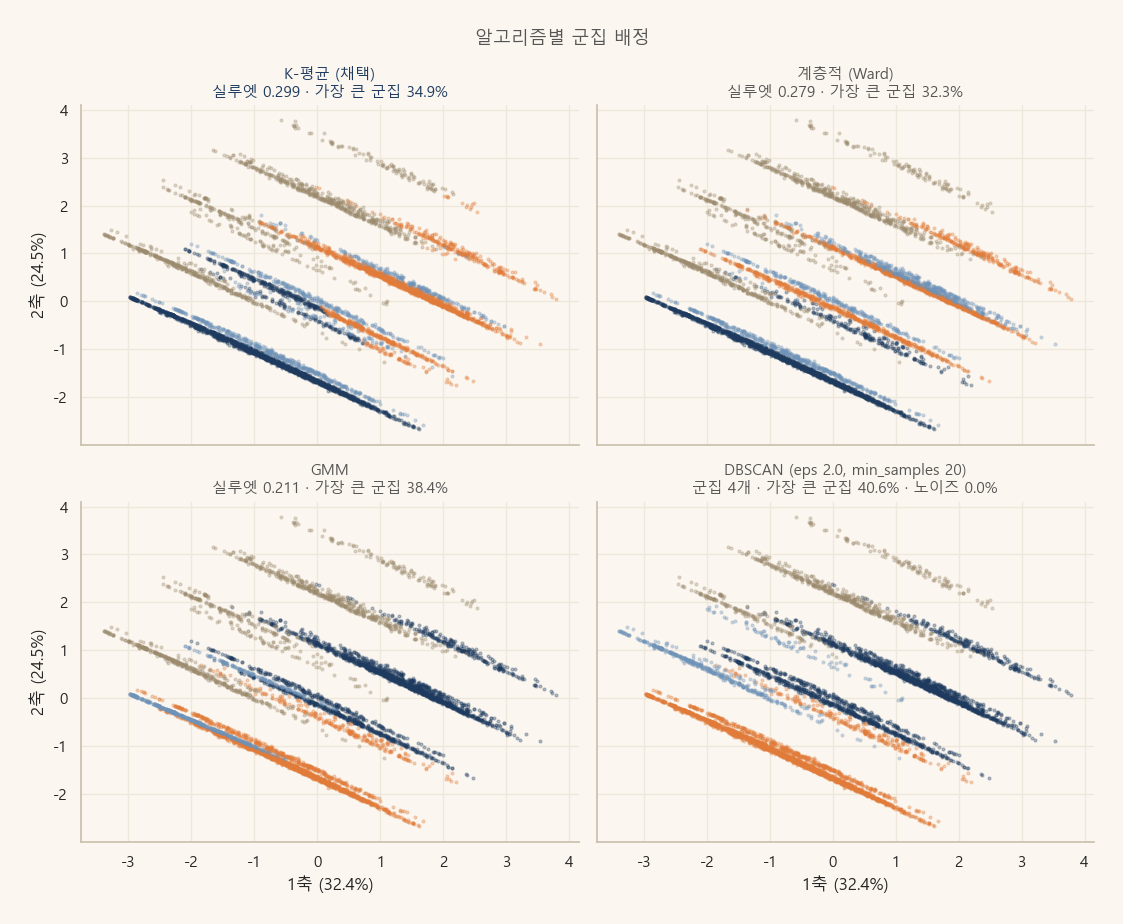

In [67]:
# 같은 입력을 네 알고리즘이 어떻게 나누는지 PCA 2차원에서 비교 (5.6과 같은 투영)
DB_EPS, DB_MIN = 2.0, 20   # DBSCAN 20개 설정 중 군집이 4개로 나온 설정

pca_view = PCA(n_components=2, random_state=RANDOM_STATE)
P_view = pca_view.fit_transform(Z_cl)
ev_view = pca_view.explained_variance_ratio_

db_label = DBSCAN(eps=DB_EPS, min_samples=DB_MIN).fit_predict(Z_cl)

panels = dict(algo_labels)
panels[f'DBSCAN (eps {DB_EPS}, min_samples {DB_MIN})'] = db_label


def size_rank(lab):
    """인원이 많은 군집부터 0, 1, 2…로 번호를 다시 붙인다 (노이즈는 -1로 둔다)"""
    order = pd.Series(lab[lab != -1]).value_counts().index
    rank_map = {c: r for r, c in enumerate(order)}
    return np.array([rank_map.get(v, -1) for v in lab])


fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes.ravel(), panels.items()):
    rank = size_rank(lab)
    if (rank == -1).any():
        ax.scatter(P_view[rank == -1, 0], P_view[rank == -1, 1], s=4, alpha=0.3, color=BEIGE_L)
    for r in range(rank.max() + 1):
        mask_r = rank == r
        ax.scatter(P_view[mask_r, 0], P_view[mask_r, 1], s=4, alpha=0.3,
                   color=CLUSTER_PALETTE[r] if r < len(CLUSTER_PALETTE) else BEIGE)
    if name in algo_table.index:
        sub = (f"실루엣 {algo_table.loc[name, '실루엣 점수']:.3f}"
               f" · 가장 큰 군집 {algo_table.loc[name, '가장 큰 군집 비중']:.1%}")
    else:
        sub = (f"군집 {rank.max() + 1}개"
               f" · 가장 큰 군집 {np.bincount(rank[rank != -1]).max() / len(rank):.1%}"
               f" · 노이즈 {(rank == -1).mean():.1%}")
    picked = name == 'K-평균'
    ax.set_title(f"{name}{' (채택)' if picked else ''}\n{sub}", fontsize=11,
                 color=NAVY if picked else DARK)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel(f'1축 ({ev_view[0]:.1%})')
for ax in axes[:, 0]:
    ax.set_ylabel(f'2축 ({ev_view[1]:.1%})')
fig.suptitle('알고리즘별 군집 배정',
             fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

- DBSCAN 설정별 군집 수와 노이즈 비율

  위 DBSCAN 표 세 개의 내용을 한 그림에 모은다. 칸의 색은 노이즈 비율이고, 칸 안의 숫자는 군집 수다. `eps`가 작을수록 군집이 잘게 나뉘거나 노이즈가 늘고, `eps` 2.0에서만 군집이 4개로 줄어든다.

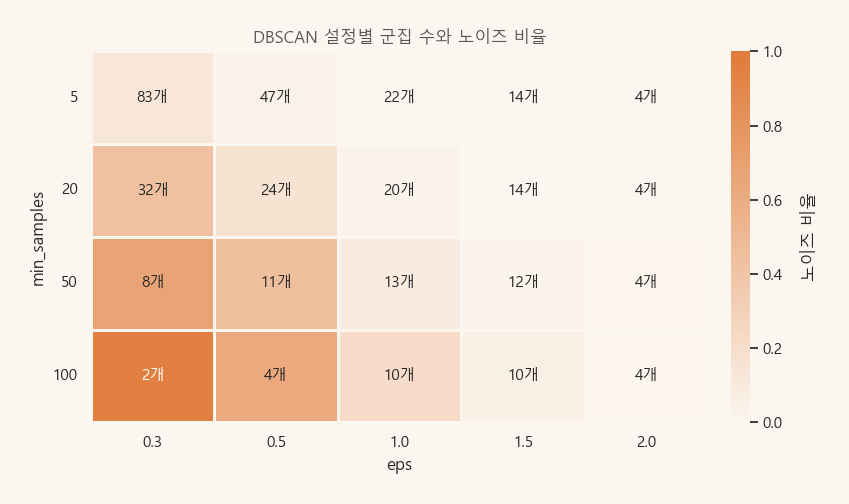

In [68]:
# DBSCAN 설정별 군집 수와 노이즈 비율 (위에서 만든 db_table 사용)
NOISE_CMAP = LinearSegmentedColormap.from_list('noise_theme', [CREAM, ORANGE])

noise_view = db_table.pivot(index='min_samples', columns='eps', values='노이즈 비율')
count_view = db_table.pivot(index='min_samples', columns='eps', values='군집 수')

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.heatmap(noise_view, annot=count_view.map(lambda v: f'{v:.0f}개').values, fmt='',
            cmap=NOISE_CMAP, vmin=0, vmax=1, linewidths=2, linecolor=CREAM,
            cbar_kws={'label': '노이즈 비율', 'pad': 0.03}, annot_kws={'size': 11}, ax=ax)
ax.grid(False)
ax.set_xlabel('eps')
ax.set_ylabel('min_samples')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.collections[0].colorbar.set_label('노이즈 비율', labelpad=14)
ax.set_title('DBSCAN 설정별 군집 수와 노이즈 비율', fontsize=12, color=DARK)
plt.tight_layout()
plt.show()

최종 군집화 알고리즘으로 K-평균을 사용한다.

- 군집 수를 4개로 맞춘 세 알고리즘 가운데 K-평균의 실루엣 점수가 0.299로 가장 높다. 계층적(Ward)은 0.279, GMM은 0.211이다.
- 가장 큰 군집 비중은 계층적(Ward)이 32.3%로 가장 낮고, K-평균은 34.9%, GMM은 38.4%다. 군집 크기의 균형은 Ward가 K-평균보다 조금 낫다.
- GMM은 기본 설정으로만 학습했다. 설정을 조정하면 결과가 달라질 수 있다.
- DBSCAN은 `eps` 5가지와 `min_samples` 4가지를 조합해 20개 설정을 시험했다.
  - `eps` 1.5 이하의 16개 설정 중 13개는 군집이 10\~83개로 세분되었다. 군집이 10개보다 적은 나머지 3개는 노이즈가 62.7\~95.7%였다.
  - `eps` 2.0에서는 군집이 4개로 줄었지만, 가장 큰 군집에 방문자의 40.6%가 몰렸다.
- 방문일수, 3일차 방문 여부, 저녁 방문 여부의 값 조합은 10가지이고 주말 비율의 값은 5가지다. 가능한 값이 제한된 피처가 많아, 동일한 값 조합을 가진 방문자들이 여러 소집단으로 분리된 것으로 보인다. 원인을 확정하려면 추가 확인이 필요하다.
- 시험한 DBSCAN 설정에서는 군집이 지나치게 세분되거나 노이즈가 많았다. 군집이 4개로 나온 `eps` 2.0도 가장 큰 군집에 방문자의 40.6%가 몰렸다. 그래서 결과를 해석하고 활용하기 어려웠다. 이 결론은 위 20개 설정에 한정된다.

## 5.4 군집 학습과 안정성 확인

5.2에서 정한 K를 적용해 방문자 전체 데이터로 모델을 학습한다.
K-평균이 매기는 군집 번호는 임의이므로, 인원이 많은 군집부터 군집1, 군집2, 군집3, 군집4로 번호를 다시 부여한다.
번호는 인원 순서일 뿐 행동이나 결제율의 순서가 아니다.

군집 이름은 팀 회의에서 정했다. 5.4 이후의 표와 그래프에는 이 이름을 사용한다.

| 번호 | 이름 | 두드러진 특징(아래 표) |
|---|---|---|
| 군집1 | 평일 하루 방문형 | 평균 방문일수 1.06일, 주말 비율 0.00 |
| 군집2 | 3일차 방문형 | 3일차 방문 96.7% |
| 군집3 | 저녁 방문형 | 저녁 방문 99.6% |
| 군집4 | 주말 방문형 | 주말 비율 0.99 |

In [69]:
kmeans_cl = KMeans(n_clusters=K_CLUSTER, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z_cl)
raw_label = pd.Series(kmeans_cl.labels_, index=cl_df.index)

# K-평균의 군집 번호는 임의이므로, 인원이 많은 군집부터 1, 2, ... 번호를 다시 매긴다
size_order = raw_label.value_counts().sort_values(ascending=False).index
cl_df['cluster'] = raw_label.map({raw: i for i, raw in enumerate(size_order, start=1)})
# 군집 이름 (팀 회의에서 정함, K=4 기준)
CLUSTER_NAMES = ['평일 하루 방문형', '3일차 방문형', '저녁 방문형', '주말 방문형']
assert len(CLUSTER_NAMES) == K_CLUSTER, 'K를 바꾸면 군집 이름도 다시 정해야 한다'

# 이후 표와 그래프는 cluster(1~K) 순서로 CLUSTER_NAMES를 쓴다
center = cl_df.groupby('cluster')[['visit_days', 'day3', 'avg_stay_h', 'any_evening', 'weekend_ratio']].mean()
center.index = CLUSTER_NAMES

size_view = cl_df['cluster'].value_counts().sort_index().to_frame('인원')
size_view['비율'] = size_view['인원'] / len(cl_df)
size_view.index = CLUSTER_NAMES
size_view.index.name = '군집'
display(size_view.join(center.rename(columns={
    'visit_days': '평균 방문일수', 'day3': '3일차 방문', 'avg_stay_h': '일평균 체류시간(h)',
    'any_evening': '저녁 방문', 'weekend_ratio': '주말 비율',
})).style.format({'인원': '{:,}', '비율': '{:.1%}', '평균 방문일수': '{:.2f}', '3일차 방문': '{:.1%}',
                  '일평균 체류시간(h)': '{:.1f}', '저녁 방문': '{:.1%}', '주말 비율': '{:.2f}'}))

,인원,비율,평균 방문일수,3일차 방문,일평균 체류시간(h),저녁 방문,주말 비율
군집,,,,,,,
평일 하루 방문형,"2,020",34.9%,1.06,12.9%,3.8,0.0%,0.00
3일차 방문형,"1,756",30.3%,1.99,96.7%,5.7,1.2%,0.09
저녁 방문형,"1,141",19.7%,1.63,60.7%,2.8,99.6%,0.19
주말 방문형,877,15.1%,1.27,47.2%,4.3,2.4%,0.99


안정성 확인

`n_init=50`은 한 번 학습할 때 군집 내 거리 합이 더 작은 초기 중심을 선택하기 위한 설정이다. 표본이 달라져도 동일한 방문자가 같은 군집에 배정되는지는 별도로 확인해야 한다.

- 시드: `random_state`를 0\~9로 바꿔 10번 다시 학습한다.
- 부트스트랩: 방문자를 복원추출해 만든 표본으로 30번 다시 학습하고, 학습한 중심으로 전체 방문자에게 군집을 배정한다.
- 일치도: 5.4의 기준 군집과 재학습한 군집을 겹치는 방문자가 가장 많은 조합으로 대응시킨 뒤, 동일한 대응 군집에 배정된 방문자의 비율을 계산한다. 서로 다른 두 기준 군집이 하나의 재학습 군집에 대응되면 1:1 대응이 아니므로 별도로 집계한다.

In [70]:
def agreement(base, new):
    """기준 군집과 가장 많이 겹치는 새 군집을 대응시켜, 대응 군집 유지 비율과 1:1 대응 여부를 반환"""
    ct = pd.crosstab(base, new)
    return ct.max(axis=1).sum() / len(base), ct.idxmax(axis=1).nunique() == len(ct)


base_label = cl_df['cluster'].values

seed_res = [agreement(base_label, KMeans(n_clusters=K_CLUSTER, n_init=N_INIT, random_state=s).fit_predict(Z_cl))
            for s in range(10)]

rng_cl = np.random.default_rng(RANDOM_STATE)
boot_res = []
for _ in range(30):
    idx = rng_cl.integers(0, len(Z_cl), len(Z_cl))
    km = KMeans(n_clusters=K_CLUSTER, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z_cl[idx])
    boot_res.append(agreement(base_label, km.predict(Z_cl)))

stab = pd.DataFrame({
    name: {
        '반복 횟수': len(res),
        '일치도 최솟값': min(r[0] for r in res),
        '일치도 중앙값': np.median([r[0] for r in res]),
        '1:1 대응이 아닌 횟수': sum(not r[1] for r in res),
    }
    for name, res in (('시드 변경', seed_res), ('부트스트랩', boot_res))
}).T
stab.index.name = f'K={K_CLUSTER} 안정성'
display(stab.style.format({'반복 횟수': '{:.0f}', '일치도 최솟값': '{:.1%}', '일치도 중앙값': '{:.1%}',
                           '1:1 대응이 아닌 횟수': '{:.0f}'}))

# 부트스트랩 결과가 기준과 가장 달랐던 경우, 기준 군집별로 대응 군집 유지 비율
worst = int(np.argmin([r[0] for r in boot_res]))
rng_cl = np.random.default_rng(RANDOM_STATE)
for b in range(worst + 1):
    idx = rng_cl.integers(0, len(Z_cl), len(Z_cl))
worst_label = KMeans(n_clusters=K_CLUSTER, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z_cl[idx]).predict(Z_cl)
worst_ct = pd.crosstab(base_label, worst_label)
worst_view = (worst_ct.max(axis=1) / worst_ct.sum(axis=1)).to_frame('대응 군집 유지 비율')
worst_view.index = CLUSTER_NAMES
worst_view.index.name = f'일치도가 가장 낮았던 부트스트랩 ({boot_res[worst][0]:.1%})'
display(worst_view.style.format('{:.1%}'))

,반복 횟수,일치도 최솟값,일치도 중앙값,1:1 대응이 아닌 횟수
K=4 안정성,,,,
시드 변경,10,99.9%,100.0%,0
부트스트랩,30,99.0%,99.5%,0


,대응 군집 유지 비율
일치도가 가장 낮았던 부트스트랩 (99.0%),
평일 하루 방문형,100.0%
3일차 방문형,98.5%
저녁 방문형,97.5%
주말 방문형,99.8%


- 시드를 바꾼 10번의 일치도는 최솟값 99.9%, 중앙값 100.0%다. 초기 중심에 따른 차이는 거의 없다.
- 부트스트랩 30번의 일치도는 중앙값 99.5%, 최솟값 99.0%다. 30번 모두 기준 군집과 1:1로 대응되었다.
- 일치도가 가장 낮았던 표본에서도 네 군집 모두 97.5\~100.0%가 대응 군집에 배정되었다.

## 5.5 군집별 특징과 결제율

- 군집별 행동 특성은 군집 형성에 사용한 피처와 참고 피처(1일차 방문, 체류 구간)의 평균을 함께 비교한다.
- 미방문 신청자와 체류시간 결측으로 분석에서 제외한 방문자는 군집에 포함하지 않고, 결제율 비교를 위한 기준 집단으로만 제시한다.
- 교차표로 군집이 방문일수만으로 구분되었는지 확인한다.

In [71]:
visitor_rate_cl = cl_df[TARGET].mean()

profile = cl_df.groupby('cluster').agg(
    인원=(TARGET, 'size'),
    결제자=(TARGET, 'sum'),
    결제율=(TARGET, 'mean'),
    방문일수=('visit_days', 'mean'),
    일차1_방문=('day1', 'mean'),
    일차3_방문=('day3', 'mean'),
    체류시간=('avg_stay_h', 'mean'),
    체류_1시간_미만=('stay_lt1', 'mean'),
    체류_6시간_이상=('stay_6p', 'mean'),
    태그수=('tags_per_day', 'mean'),
    저녁_방문=('any_evening', 'mean'),
    주말_비율=('weekend_ratio', 'mean'),
)
profile.insert(3, '방문자 대비', profile['결제율'] / visitor_rate_cl)
profile.index = CLUSTER_NAMES

# 기준 집단 : 방문자 전체, 체류시간 결측으로 제외된 방문자, 미방문 신청자
ref_groups = {
    '방문자 전체 (군집 대상)': cl_df[TARGET],
    '체류시간 결측 (제외)': u.loc[(u['visited'] == 1) & ~u['user_uuid'].isin(cl_df['user_uuid']), TARGET],
    '미방문 신청자 (1~3일차)': u.loc[u['visited'] == 0, TARGET],
}
ref_rows = []
for name, s in ref_groups.items():
    ref_rows.append({'인원': len(s), '결제자': int(s.sum()), '결제율': s.mean(),
                     '방문자 대비': s.mean() / visitor_rate_cl})
profile = pd.concat([profile, pd.DataFrame(ref_rows, index=list(ref_groups))])

profile = profile.rename(columns={
    '방문일수': '평균 방문일수', '일차1_방문': '1일차 방문', '일차3_방문': '3일차 방문',
    '체류시간': '일평균 체류시간(h)', '체류_1시간_미만': '체류 1시간 미만', '체류_6시간_이상': '체류 6시간 이상',
    '태그수': '방문일당 태그 수', '저녁_방문': '저녁 방문', '주말_비율': '주말 비율',
})
profile.index.name = '군집'
pct_cols = ['결제율', '1일차 방문', '3일차 방문', '체류 1시간 미만', '체류 6시간 이상', '저녁 방문']
fmt = {c: '{:.1%}' for c in pct_cols}
fmt.update({'인원': '{:,.0f}', '결제자': '{:,.0f}', '방문자 대비': '{:.2f}배',
            '평균 방문일수': '{:.2f}', '일평균 체류시간(h)': '{:.1f}', '방문일당 태그 수': '{:.1f}', '주말 비율': '{:.2f}'})
display(profile.style.format(fmt, na_rep=''))

# 군집이 방문일수만으로 구분되었는지 확인
days_ct = pd.crosstab(cl_df['cluster'], cl_df['visit_days'], normalize='index')
days_ct.index = CLUSTER_NAMES
days_ct.columns = [f'{d}일 방문' for d in days_ct.columns]
days_ct.index.name = '군집 (행 비율)'
display(days_ct.style.format('{:.1%}'))

,인원,결제자,결제율,방문자 대비,평균 방문일수,1일차 방문,3일차 방문,일평균 체류시간(h),체류 1시간 미만,체류 6시간 이상,방문일당 태그 수,저녁 방문,주말 비율
군집,,,,,,,,,,,,,
평일 하루 방문형,"2,020",686,34.0%,0.87배,1.06,32.7%,12.9%,3.8,15.4%,19.6%,3.0,0.0%,0.00
3일차 방문형,"1,756",719,40.9%,1.05배,1.99,23.6%,96.7%,5.7,2.0%,43.8%,4.3,1.2%,0.09
저녁 방문형,"1,141",578,50.7%,1.30배,1.63,29.0%,60.7%,2.8,18.6%,6.3%,2.3,99.6%,0.19
주말 방문형,877,269,30.7%,0.79배,1.27,21.6%,47.2%,4.3,8.2%,23.7%,3.3,2.4%,0.99
방문자 전체 (군집 대상),"5,794","2,252",38.9%,1.00배,,,,,,,,,
체류시간 결측 (제외),193,73,37.8%,0.97배,,,,,,,,,
미방문 신청자 (1~3일차),"3,610","1,319",36.5%,0.94배,,,,,,,,,


,1일 방문,2일 방문,3일 방문
군집 (행 비율),,,
평일 하루 방문형,94.2%,5.8%,0.0%
3일차 방문형,15.5%,69.9%,14.6%
저녁 방문형,45.7%,45.7%,8.5%
주말 방문형,72.6%,27.4%,0.0%


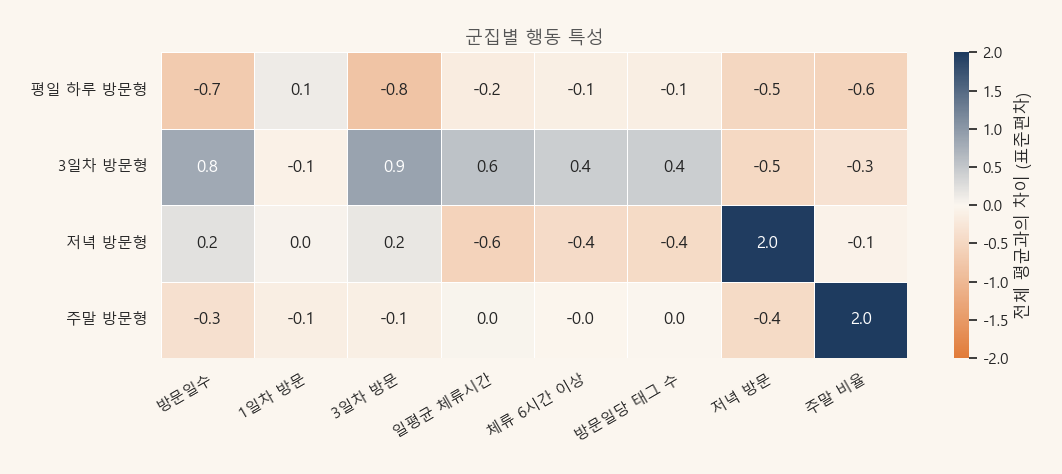

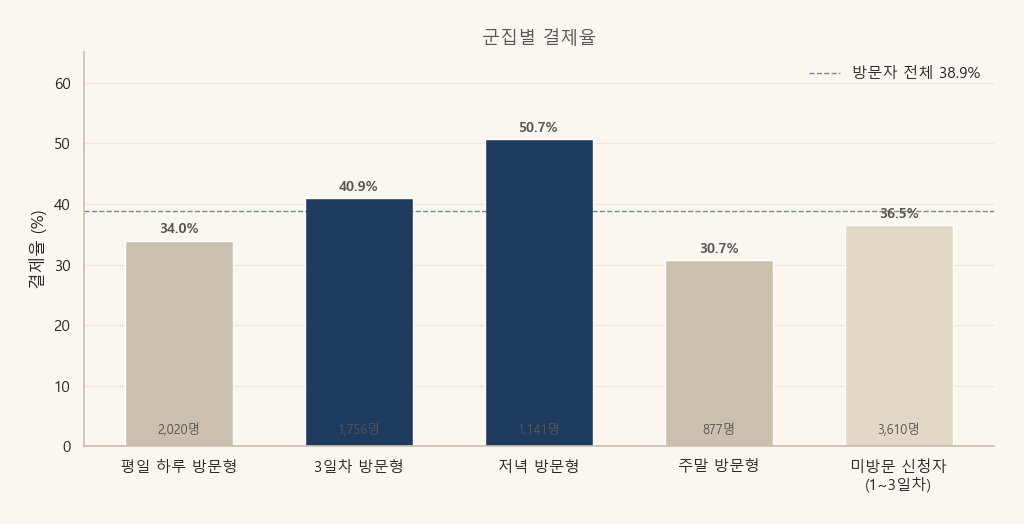

In [72]:
# 그래프 1 : 군집별 행동 특성 (방문자 전체 평균과의 차이, 표준편차 단위)
heat_cols = {
    'visit_days': '방문일수', 'day1': '1일차 방문', 'day3': '3일차 방문', 'avg_stay_h': '일평균 체류시간',
    'stay_6p': '체류 6시간 이상', 'tags_per_day': '방문일당 태그 수', 'any_evening': '저녁 방문', 'weekend_ratio': '주말 비율',
}
cl_mean = cl_df.groupby('cluster')[list(heat_cols)].mean()
heat = (cl_mean - cl_df[list(heat_cols)].mean()) / cl_df[list(heat_cols)].std()
heat.index = CLUSTER_NAMES
heat.columns = list(heat_cols.values())

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(heat, cmap=DIV_CMAP, center=0, vmin=-2, vmax=2, annot=True, fmt='.1f',
            linewidths=0.5, cbar_kws={'label': '전체 평균과의 차이 (표준편차)'}, ax=ax)
ax.grid(False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', rotation_mode='anchor')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('군집별 행동 특성', fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

# 그래프 2 : 군집별 결제율
bar = profile.loc[CLUSTER_NAMES + ['미방문 신청자 (1~3일차)']]
vals = bar['결제율'].values * 100
colors = [NAVY if r > visitor_rate_cl else BEIGE for r in bar['결제율']]
colors[-1] = BEIGE_L

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(bar)), vals, color=colors, width=0.6)
for i, (v, n) in enumerate(zip(vals, bar['인원'])):
    ax.text(i, v + 1.2, f'{v:.1f}%', ha='center', fontsize=10, color=DARK, fontweight='bold')
    ax.text(i, 2, f'{n:,.0f}명', ha='center', fontsize=9, color=DARK)
ax.axhline(visitor_rate_cl * 100, color=NAVY, linestyle='--', linewidth=1, alpha=0.6,
           label=f'방문자 전체 {visitor_rate_cl:.1%}')
ax.set_xticks(range(len(bar)))
ax.set_xticklabels([n.replace(' (', '\n(') for n in bar.index])
ax.set_ylabel('결제율 (%)')
ax.set_ylim(0, 65)
ax.legend(frameon=False, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0)
ax.set_title('군집별 결제율', fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

## 5.6 2차원으로 본 군집 (PCA)

표준화한 6개 피처를 주성분 분석(PCA)으로 2차원에 투영해, 군집이 어느 정도 분리되는지 확인한다.
두 축의 설명 분산 비율이 낮으면 2차원 그림에서 군집이 겹쳐 보여도 원래의 6차원 공간에서는 분리되어 있을 수 있다.
따라서 PCA 그림은 군집 구조를 이해하기 위한 보조 자료로 사용한다.

먼저 6개 주성분 전체의 설명 분산 비율과 계수를 확인한다.
막대는 주성분별 설명 분산 비율이고, 선은 누적 설명 분산 비율이다.
계수는 각 피처가 주성분에 기여하는 방향과 크기를 나타낸다. 절댓값이 클수록 그 피처가 해당 주성분에 크게 반영된다.
PC1과 PC2는 아래 산점도의 첫 번째 축과 두 번째 축에 해당한다. 산점도의 큰 점은 군집마다 2차원 좌표를 평균한 군집 중심이다.

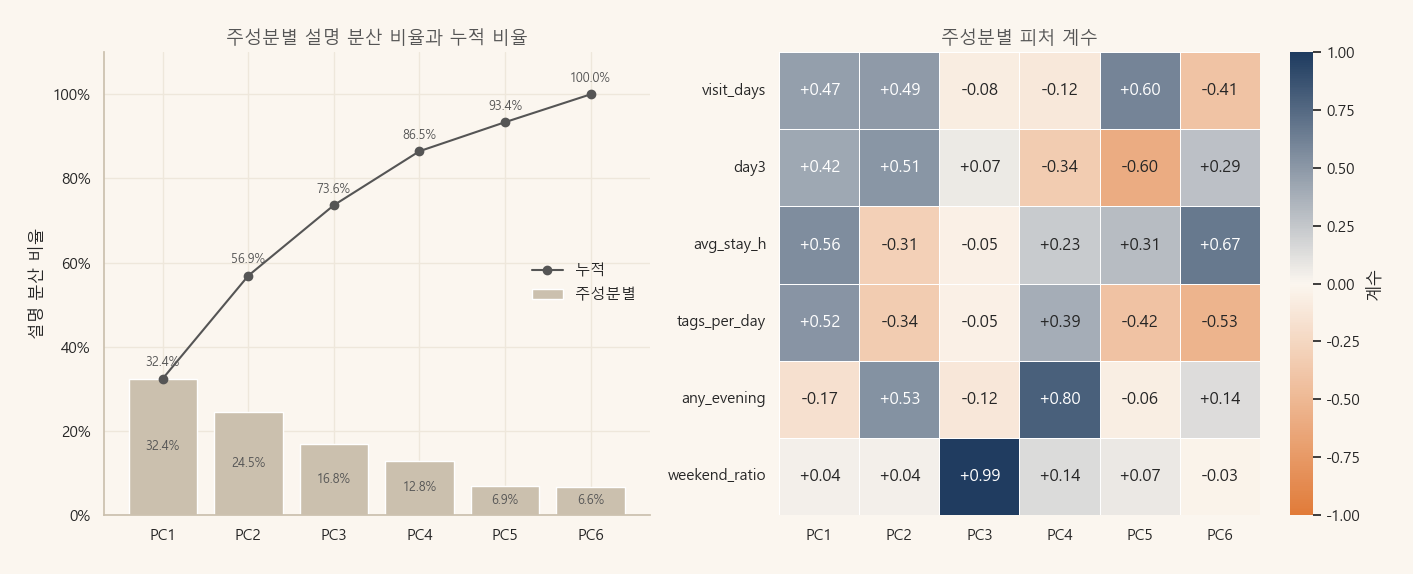

In [73]:
# 6개 주성분 전체의 설명 분산 비율과 계수
pca_full = PCA(random_state=RANDOM_STATE).fit(Z_cl)
ev_full = pca_full.explained_variance_ratio_
cum_ev = ev_full.cumsum()
pc_names = [f'PC{i}' for i in range(1, len(ev_full) + 1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.1]})

# 왼쪽 : 주성분별 설명 분산 비율(막대)과 누적 설명 분산 비율(선)
ax = axes[0]
ax.bar(pc_names, ev_full, color=BEIGE, label='주성분별')
ax.plot(pc_names, cum_ev, color=DARK, marker='o', label='누적')
for x, (v, c) in enumerate(zip(ev_full, cum_ev)):
    ax.text(x, v / 2, f'{v:.1%}', ha='center', va='center', fontsize=9, color=DARK)
    ax.text(x, c + 0.03, f'{c:.1%}', ha='center', fontsize=9, color=DARK)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylabel('설명 분산 비율')
ax.legend(frameon=False, loc='center right')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('주성분별 설명 분산 비율과 누적 비율', fontsize=13, color=DARK)

# 오른쪽 : 주성분별 피처 계수
loading_full = pd.DataFrame(pca_full.components_.T, index=CLUSTER_FEATURES, columns=pc_names)
sns.heatmap(loading_full, annot=True, fmt='+.2f', cmap=DIV_CMAP, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': '계수'}, ax=axes[1])
axes[1].set_title('주성분별 피처 계수', fontsize=13, color=DARK)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

설명 분산 비율 : 1축 32.4%, 2축 24.5%, 합계 56.9%


,1축,2축
visit_days,+0.47,+0.49
day3,+0.42,+0.51
avg_stay_h,+0.56,-0.31
tags_per_day,+0.52,-0.34
any_evening,-0.17,+0.53
weekend_ratio,+0.04,+0.04


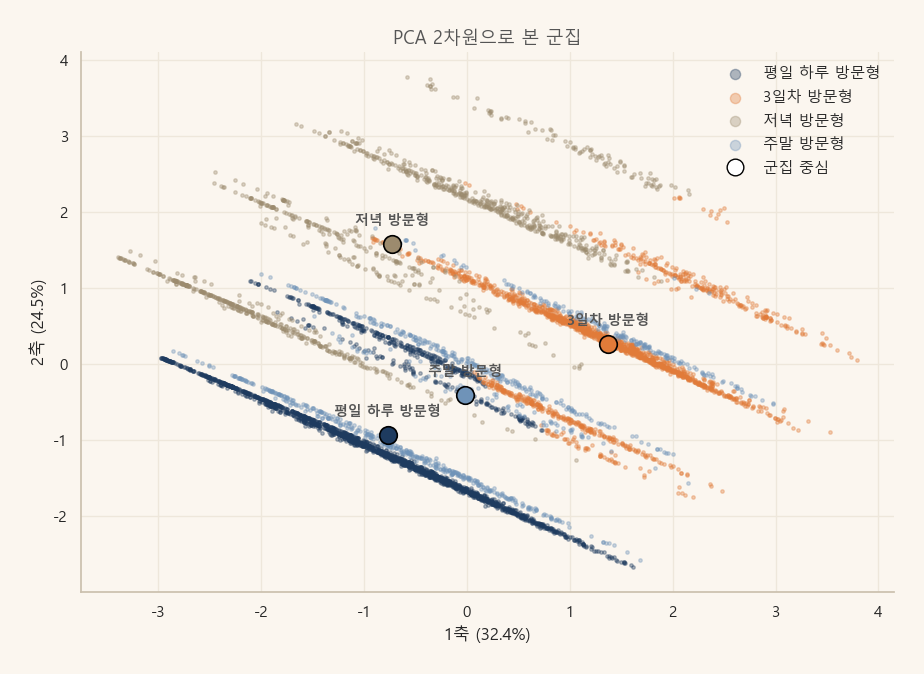

In [74]:
pca_cl = PCA(n_components=2, random_state=RANDOM_STATE)
P_cl = pca_cl.fit_transform(Z_cl)
ev = pca_cl.explained_variance_ratio_
print(f'설명 분산 비율 : 1축 {ev[0]:.1%}, 2축 {ev[1]:.1%}, 합계 {ev.sum():.1%}')

loading = pd.DataFrame(pca_cl.components_.T, index=CLUSTER_FEATURES, columns=['1축', '2축'])
display(loading.style.format('{:+.2f}'))

palette = CLUSTER_PALETTE[:K_CLUSTER]

fig, ax = plt.subplots(figsize=(9, 6.5))
for i, name in enumerate(CLUSTER_NAMES, start=1):
    mask_i = (cl_df['cluster'] == i).values
    ax.scatter(P_cl[mask_i, 0], P_cl[mask_i, 1], s=6, alpha=0.35, color=palette[i - 1], label=name)
    cx, cy = P_cl[mask_i].mean(axis=0)
    ax.scatter(cx, cy, s=160, color=palette[i - 1], edgecolor='black', linewidth=1.2, zorder=3)
    ax.text(cx, cy + 0.25, name, ha='center', fontsize=10, fontweight='bold', color=DARK, zorder=4)
ax.set_xlabel(f'1축 ({ev[0]:.1%})')
ax.set_ylabel(f'2축 ({ev[1]:.1%})')
from matplotlib.lines import Line2D

handles, names = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker='o', linestyle='', markersize=4, markerfacecolor='white', markeredgecolor='black'))
names.append('군집 중심')
ax.legend(handles, names, frameon=False, markerscale=3, loc='best')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('PCA 2차원으로 본 군집', fontsize=13, color=DARK)
plt.tight_layout()
plt.show()

## 5.7 연도별 군집 비중과 결제율

EDA에서 연도별 결제율이 낮아지는 추세를 확인했다. 이러한 변화가 군집 구성의 변화에서 비롯된 것인지, 각 군집 내 결제율 하락에서 비롯된 것인지 구분해 살펴본다.
군집은 2021\~2023년 전체로 한 번 학습했으므로 모든 연도에 같은 기준이 적용된다. 이 비교는 기술적 분석이며, 2023년을 따로 검증한 결과가 아니다.

,평일 하루 방문형,3일차 방문형,저녁 방문형,주말 방문형
연도 (군집 비중),,,,
2021,35.6%,29.6%,20.1%,14.7%
2022,37.6%,29.8%,18.1%,14.5%
2023,31.7%,31.4%,20.9%,16.0%


,평일 하루 방문형,3일차 방문형,저녁 방문형,주말 방문형,방문자 전체
연도 (결제율),,,,,
2021,39.4%,43.6%,52.5%,36.5%,42.8%
2022,34.1%,45.2%,54.6%,35.6%,41.3%
2023,29.3%,35.3%,46.1%,22.5%,33.6%


,평일 하루 방문형,3일차 방문형,저녁 방문형,주말 방문형
연도 (인원),,,,
2021,564,468,318,233
2022,771,611,372,298
2023,685,677,451,346


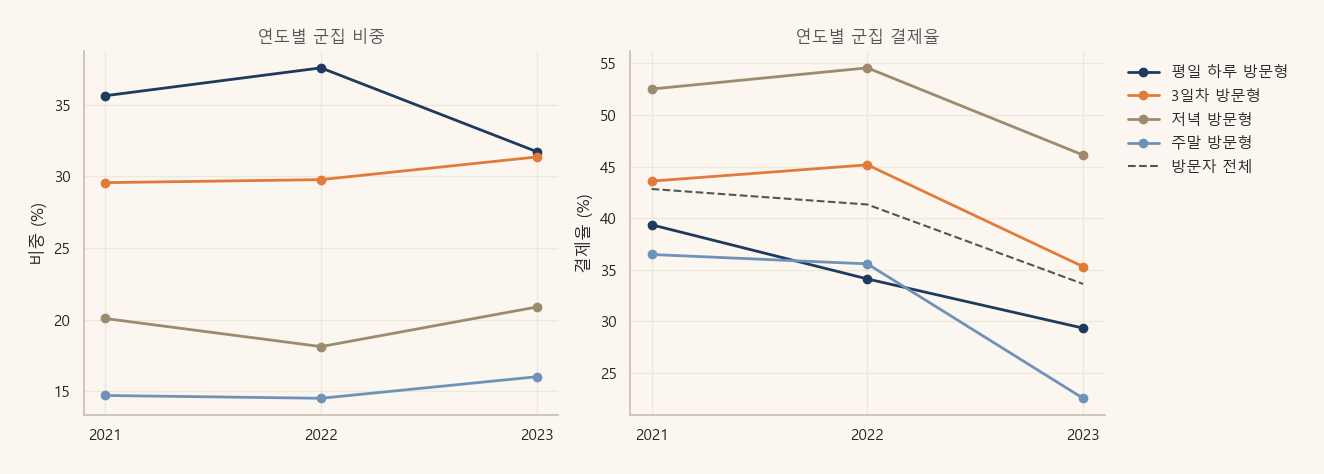

In [75]:
cl_df['year'] = cl_df['trial_date'].dt.year

year_share = pd.crosstab(cl_df['year'], cl_df['cluster'], normalize='index')
year_share.columns = CLUSTER_NAMES
year_share.index.name = '연도 (군집 비중)'
display(year_share.style.format('{:.1%}'))

year_rate = cl_df.pivot_table(index='year', columns='cluster', values=TARGET, aggfunc='mean')
year_rate.columns = CLUSTER_NAMES
year_rate['방문자 전체'] = cl_df.groupby('year')[TARGET].mean()
year_rate.index.name = '연도 (결제율)'
display(year_rate.style.format('{:.1%}'))

year_n = pd.crosstab(cl_df['year'], cl_df['cluster'])
year_n.columns = CLUSTER_NAMES
year_n.index.name = '연도 (인원)'
display(year_n)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, name in enumerate(CLUSTER_NAMES):
    axes[0].plot(year_share.index, year_share[name] * 100, marker='o', color=palette[i], linewidth=2, label=name)
    axes[1].plot(year_rate.index, year_rate[name] * 100, marker='o', color=palette[i], linewidth=2, label=name)
axes[1].plot(year_rate.index, year_rate['방문자 전체'] * 100, color=DARK, linestyle='--', linewidth=1.5, label='방문자 전체')
axes[0].set_title('연도별 군집 비중', fontsize=12, color=DARK)
axes[0].set_ylabel('비중 (%)')
axes[1].set_title('연도별 군집 결제율', fontsize=12, color=DARK)
axes[1].set_ylabel('결제율 (%)')
for ax in axes:
    ax.set_xticks(year_share.index)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5.8 모델 고객군(4.9.2)과 비교

4.9.2의 고객군은 2023년 평가 데이터에만 있으므로 2023년 방문자를 대상으로 교차표를 만든다.
군집과 모델 고객군이 유사한 방문자 집단을 구분하는지, 그리고 동일 군집 내에서도 모델 점수에 따라 고객군이 나뉘는지 확인한다.
군집 학습에 2023년 방문자도 포함되었으므로, 이 교차표는 두 구분 방식의 관계를 기술한 것이며 독립적인 검증이 아니다.

In [76]:
cmp_df = seg_df[['seg', TARGET]].join(cl_df['cluster'])
cmp_df['cluster'] = cmp_df['cluster'].map(dict(enumerate(CLUSTER_NAMES, start=1)))
print(f'비교 대상 (2023년 방문자) : {len(cmp_df):,}명, 군집이 없는 방문자 {cmp_df["cluster"].isna().sum()}명')

# 군집별 모델 고객군 구성 (행 비율)
seg_ct = pd.crosstab(cmp_df['cluster'], cmp_df['seg'], normalize='index').reindex(index=CLUSTER_NAMES, columns=seg_names)
seg_ct['인원'] = cmp_df['cluster'].value_counts().reindex(CLUSTER_NAMES)
seg_ct.index.name = '군집 (행 비율)'
seg_ct.columns.name = None
fmt_ct = {c: '{:.1%}' for c in seg_names}
fmt_ct['인원'] = '{:,}'
display(seg_ct.style.format(fmt_ct))

# 군집 × 고객군별 결제율
seg_rate = cmp_df.pivot_table(index='cluster', columns='seg', values=TARGET, aggfunc='mean').reindex(index=CLUSTER_NAMES, columns=seg_names)
seg_rate['군집 전체'] = cmp_df.groupby('cluster')[TARGET].mean().reindex(CLUSTER_NAMES)
seg_cnt = pd.crosstab(cmp_df['cluster'], cmp_df['seg']).reindex(index=CLUSTER_NAMES, columns=seg_names)
seg_rate.index.name = '군집 (2023년 결제율)'
seg_rate.columns.name = None
seg_cnt.index.name = '군집 (인원)'
seg_cnt.columns.name = None
display(seg_rate.style.format('{:.1%}', na_rep='-'))
print('칸별 인원 (30명 미만인 칸은 결제율의 변동이 크다)')
display(seg_cnt)

비교 대상 (2023년 방문자) : 2,159명, 군집이 없는 방문자 0명


,상위 30%,중간 40% (30~70%),하위 30% (70~100%),인원
군집 (행 비율),,,,
평일 하루 방문형,7.6%,45.4%,47.0%,685
3일차 방문형,34.4%,46.7%,18.9%,677
저녁 방문형,74.5%,22.4%,3.1%,451
주말 방문형,7.8%,39.3%,52.9%,346


,상위 30%,중간 40% (30~70%),하위 30% (70~100%),군집 전체
군집 (2023년 결제율),,,,
평일 하루 방문형,44.2%,35.4%,21.1%,29.3%
3일차 방문형,42.1%,33.9%,26.6%,35.3%
저녁 방문형,48.8%,42.6%,7.1%,46.1%
주말 방문형,33.3%,23.5%,20.2%,22.5%


칸별 인원 (30명 미만인 칸은 결제율의 변동이 크다)


,상위 30%,중간 40% (30~70%),하위 30% (70~100%)
군집 (인원),,,
평일 하루 방문형,52,311,322
3일차 방문형,233,316,128
저녁 방문형,336,101,14
주말 방문형,27,136,183


군집 × 모델 고객군별 인원

위의 군집 × 고객군 교차표를 인원 기준으로 나타낸다. 칸의 색은 고객군을 구분하며, 결제 확률 순위가 높은 고객군일수록 진하다(하위 30% → 중간 40% → 상위 30%). 칸별 결제율 수치는 위의 표에 있다.

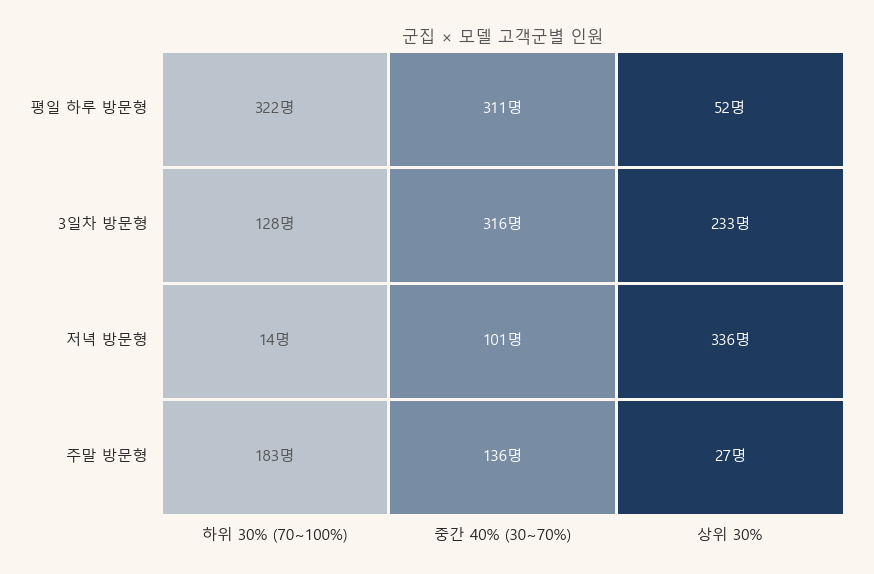

In [77]:
# 군집 × 고객군 : 색은 고객군(상위일수록 진한 남색), 칸 안의 글자는 인원 (위에서 만든 seg_cnt 사용)
from matplotlib.colors import ListedColormap

heat_order = seg_names[::-1]   # 열 순서 : 하위 30% → 중간 40% → 상위 30%
seg_colors = [SEQ_CMAP(0.3), SEQ_CMAP(0.6), SEQ_CMAP(1.0)]   # heat_order 순서 (연한 남색 → 진한 남색)
text_colors = [DARK, 'white', 'white']
cell_n = seg_cnt[heat_order]

# 열 번호(0, 1, 2)를 색 번호로 써서 같은 열은 같은 색으로 칠한다
col_idx = np.tile(np.arange(len(heat_order)), (len(cell_n), 1))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(col_idx, cmap=ListedColormap(seg_colors), vmin=-0.5, vmax=len(heat_order) - 0.5, cbar=False,
            linewidths=2, linecolor=CREAM, xticklabels=heat_order, yticklabels=cell_n.index, ax=ax)
for i in range(cell_n.shape[0]):
    for j in range(cell_n.shape[1]):
        ax.text(j + 0.5, i + 0.5, f'{cell_n.iat[i, j]:,}명', ha='center', va='center', fontsize=11, color=text_colors[j])
ax.grid(False)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('군집 × 모델 고객군별 인원', fontsize=12, color=DARK)
plt.tight_layout()
plt.show()

# **6. 결론**

5.8에서 군집마다 모델 고객군 구성과 결제율을 확인했다.
결론에서는 각 군집에서 모델 고객군 하위 30%에 속한 방문자를 대상으로 비즈니스 액션을 제안한다.

## 6.1 군집별 하위 30%를 선정한 이유

- 목표는 결제율을 높이는 것이다.
- 한 번이라도 방문한 사람은 서비스에 어느 정도 관심이 있다고 보고, 이러한 관심을 결제로 전환하기 위한 액션을 제안한다.
- 방문을 유도하는 데 투입한 고객 획득 비용과 체험 운영 자원은 결제로 이어지지 않으면 회수되지 않는다. 이 손실을 줄이기 위해 결제로 이어질 가능성이 낮은 고객을 우선 관리한다.

## 6.2 군집별 비즈니스 액션

| 군집 | 저비용 비즈니스 액션 | 고비용 비즈니스 액션 |
|---|---|---|
| 평일 하루 방문형 | 재방문 유도 알림 | 하루 무료 이용권 추가 증정 |
| 3일차 방문형 | 결제 리마인드 | 첫 달 할인 |
| 저녁 방문형 | 야간 이용권 안내 | 저녁에만 방문한 사람에게 1일 무료 이용권 제공 |
| 주말 방문형 | 주말 이용권 안내 | 주말에만 방문한 사람에게 다음 주말 1일 이용권 제공 |

## 6.3 한계

- 하위 30%는 결제 가능성이 낮은 만큼 제안한 액션에도 반응하지 않을 수 있다. 여기서 정한 액션은 효과가 검증된 방안이 아니라 실험을 통해 검증해야 할 가설이다.
- 군집마다 대상 인원에 큰 차이가 있다. 2023년 방문자 기준 하위 30%는 평일 하루 방문형 322명, 3일차 방문형 128명, 주말 방문형 183명이고, 저녁 방문형은 14명뿐이다. 저녁 방문형은 결제율의 변동이 크고, 액션을 실행해도 전체 결제자 수에 미치는 영향이 작다.
- 비용을 수치로 확인하지 않았다. 데이터에 고객 획득 비용과 체험 운영 비용이 없어 저비용·고비용은 정성적으로 구분했다. 액션 비용이 추가 결제로 발생하는 매출보다 적은지는 알 수 없다.
- 결제 이후의 이용 행태는 분석 대상에 포함하지 않았다. 목표 지표가 결제율이므로, 첫 달 할인 등으로 결제한 사람이 할인이 끝난 뒤에도 계속 이용하는지는 알 수 없다.